# Notebook 1 - EBM Poker Agent

> **Reproduce:** `.venv/Scripts/python scripts/build_notebooks.py --execute 01_ebm_poker_agent`
> (about 3 minutes on 4 worker processes; the source is `notebooks/src/01_ebm_poker_agent.py`, the adjustable numbers are in
> the *NOTEBOOK CONFIGURATION* cell below). The agent itself was trained by `.venv/Scripts/python scripts/train_ebm.py`
> (about 14 minutes on 10 cores); this notebook only *reads* the artifacts in `artifacts/models/ebm/`, the dataset
> `artifacts/datasets/teacher_bc_v2`, and runs small, clearly labelled live demos and fresh seeded evaluations on top of them.

## 1. Overview and research question

**Research question.** *Can a glass-box model - an Explainable Boosting Machine, i.e. a sum of readable one- and two-feature
curves - imitate a transparent poker policy well enough to play decent heads-up poker, and do its own explanations tell us
the truth about what it learned?*

Because the model imitates a **transparent teacher** (equity against a random hand, compared with pot odds, plus position-aware
preflop ranges) we know the *ground truth* of every decision: which rule fired and which thresholds it used. That makes
this an unusually clean test bed for interpretability: we can check an explanation against the rule that really produced the label.

Five sub-questions structure the notebook:

1. **Data (section 2-3).** What exactly is the EBM trained on, and what are the inputs and targets?
2. **Training (section 4).** What did the training cost, and did DAgger - the "better than pure imitation" option - actually help?
3. **Imitation vs skill (section 5).** How faithfully does it copy the teacher, where does it disagree, and - *separately* - how well does it play?
4. **What it looks at (section 6-7).** Global shape functions and interactions; local explanations of concrete decisions, checked against the teacher's rules.
5. **What it learned (section 8).** Do the learned thresholds match the teacher's parameters? Does it model the opponent? Which features that the teacher ignores does it use anyway?

### What is an EBM?

An **Explainable Boosting Machine** (InterpretML, `ExplainableBoostingClassifier`) is a *generalised additive model with
interactions*, fitted by cyclic gradient boosting of tiny trees (one feature at a time, so each feature ends up with a lookup table).
For a 5-class problem every action `k` has a score

> `logit_k(x) = b_k + sum_j f_jk(x_j) + sum_(i,j) f_ijk(x_i, x_j)`

and the action probabilities are the softmax of the five scores. Each `f_jk` is a **shape function** (a step function of one
feature: "how does equity change the log-odds of raising?"), each `f_ijk` an **interaction surface** over a pair of features.
Nothing else happens: no hidden layers, no tree ensembles to average over. A decision is therefore explained *exactly* by its own
terms - the contributions add up to the logit, unlike post-hoc approximations (SHAP, LIME). We verify this identity in section 6.

### The poker concepts this notebook uses

* **Heads-up no-limit hold'em.** Two players, each holds two private cards; five shared cards arrive in three steps (flop = 3 cards, turn, river).
  Players alternate betting; you may *fold* (give up the hand), *check/call* (match the bet, or pass if there is none) or *raise*.
* **Equity.** The probability of winning at showdown if all remaining cards are dealt - here against a *uniformly random* opponent hand
  (so "equity 0.85" is a very strong hand). It is the single most important number, but it ignores what the opponent's *betting* tells you.
* **Pot odds.** Calling `c` into a pot that already holds `p` costs a share `c / (p + c)` of the final pot - the equity you need to break even
  against a random hand. `equity_minus_pot_odds > 0` therefore means "calling looks profitable against a random hand".
* **Position.** Heads-up the *button* (also the small blind) acts first before the flop and last after it. Acting last is an advantage.
* **SPR** (stack-to-pot ratio): the chips behind divided by the pot. A low SPR means you are "pot-committed" and the decision is mostly shove-or-fold.
* **Value bet / semi-bluff / bluff.** Betting a strong hand to get paid / betting a drawing hand that may improve (and that may make the opponent fold) / betting a weak hand purely to make the opponent fold.
* **Action abstraction.** The agents choose among five *abstract* actions: `fold`, `check_call`, `raise_small` (about half the pot), `raise_pot` (about the pot), `all_in`; an action that is not legal in a state is masked out.

### Evidence labels used throughout

* **[saved]** - read from the artifacts of the training run (`artifacts/models/ebm/metadata.json`, `config.json`), never recomputed.
* **[data]** - computed in this notebook from the committed dataset (`teacher_bc_v2`) and the saved model, e.g. metrics on the 73,777 validation decisions.
* **[fresh]** - simulated in this notebook with a visible seed (`EVAL_SEED`, seed namespace `eval`), on deals that no training or validation step ever saw.
* **[demo]** - a small illustration with the real package code (a toy fit, a mini dataset); it is *not* evidence about the committed model.

Every number quoted in a sentence below is generated from those sources. Sentences of interpretation were written after inspecting the output;
where they depend on a number they are conditioned on it, so they stay truthful if the artifacts are regenerated.

> **Important caveat, stated up front.** The labels are the *transparent teacher's* decisions: the model imitates a rule set, not a strong player.
> **Imitation accuracy is not poker skill**, and the teacher is a heuristic, not a solver. We therefore report agreement with the teacher
> (section 5.1-5.3) and playing results (section 5.4) separately and never infer the second from the first.
>
> **About the interactive widgets.** `interpret.show(...)` renders InterpretML's own dashboards through a small local web server that lives as long
> as the Jupyter kernel. They work when you (re-)run the notebook in Jupyter; **GitHub does not render them** and a saved copy shows an empty frame.
> Every key message therefore also exists as a static matplotlib figure (saved to `artifacts/figures/nb01_*.png`).

In [1]:
# ==========================================
# NOTEBOOK CONFIGURATION
# ==========================================
EVAL_SEED = 777_002  # master seed of every FRESH simulation here (namespace "eval"); official tournament: 42, GA notebook: 777001, training: 42
EVAL_PAIRS = 1000  # duplicate pairs (2 hands each) per opponent in the fresh evaluation (section 5.4)
EVAL_PAIRS_HELDOUT = 600  # duplicate pairs per opponent the EBM never met in training (evolved GA agent, balanced, bluffer)
DEMO_SEED = 7  # seed of the live data demo (section 2.2), the toy fit (4.3) and every bootstrap / subsample of this notebook
DEMO_TRAIN_HANDS = 120  # hands of the live data-generation demo, train part
DEMO_VAL_HANDS = 40  # hands of the live data-generation demo, validation part
TOY_ROWS = 20_000  # training rows of the toy EBM fit (section 4.3); the committed model used 245,346
TOY_ROUNDS = 150  # boosting rounds of the toy fit (committed model: 300)
TOY_INTERACTIONS = 15  # pairwise terms of the toy fit (committed model: 40)
FIDELITY_ROWS = 20_000  # validation states of the explanation-fidelity study (section 7.3)
PERMUTATION_ROWS = 20_000  # validation states of the permutation tests (section 8)
PERMUTATION_REPEATS = 3  # shuffles per feature (the mean is reported)
CASE_SEED = 2026  # seed of the example-case draw (poker_arena.explain.notebook_cases; shared with the XGBoost notebook)
N_CASES = 8  # number of example decisions explained in section 7.2
SHOW_INTERPRET_WIDGETS = True  # render InterpretML's interactive dashboards (needs a live kernel; GitHub shows nothing)
EVAL_PROTOCOL = "two_table"  # duplicate protocol of every fresh evaluation: "two_table" (corrected default) or "single_table" (legacy, diagnostics only; see section 5.4)
N_WORKERS = 4  # worker processes for the simulations (shared machine: keep <= 4)

In [2]:
import json
import multiprocessing
import re
import tempfile
import time
import warnings
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
from random import Random

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from interpret import show
from interpret.glassbox import ExplainableBoostingClassifier
from matplotlib.lines import Line2D
from scipy import stats

from poker_arena.agents.ebm_agent import EBMAgent
from poker_arena.agents.ga_agent import PRESETS as GA_PRESETS
from poker_arena.agents.registry import AgentSpec
from poker_arena.agents.teacher import (
    AGGRESSION_NEUTRAL,
    CANONICAL_PARAMS,
    FOLD_TO_BET_NEUTRAL,
    MAX_VALUE_THRESHOLD,
    MIN_VALUE_THRESHOLD,
    TeacherPolicy,
)
from poker_arena.config import ARTIFACTS_DIR, MODELS_DIR, GameConfig, derive_seed
from poker_arena.data import DatasetConfig, content_hash, generate_dataset, load_dataset, load_meta, validate_frame, write_dataset
from poker_arena.data.evaluation import pair_results, summarize
from poker_arena.data.generation import CollectionSpec, assemble_frame, plan_matches, run_match_plan
from poker_arena.engine.actions import ABSTRACT_ACTION_NAMES, AbstractAction
from poker_arena.engine.deals import Deal  # notebooks may use the engine's deals (agents and features may not)
from poker_arena.explain import ebm as ebm_explain
from poker_arena.explain import notebook_plots as nbp
from poker_arena.explain.notebook_cases import select_example_cases
from poker_arena.features import (
    FEATURE_DESCRIPTIONS,
    FEATURE_GROUP_OF,
    FEATURE_GROUPS,
    FEATURE_INDEX,
    FEATURE_NAMES,
    FEATURE_RANGES,
    NUM_FEATURES,
)
from poker_arena.tournament import load_results
from poker_arena.training.common import SplitArrays, evaluate_classifier, masked_argmax, sample_weights, subsample_by_hand
from poker_arena.training.ebm import hand_aware_bags
from poker_arena.training.ebm import class_probabilities as model_probabilities

warnings.filterwarnings("ignore", message="Dropping term")  # interpret: pairs cannot be drawn for a multi-class model (section 6 draws them)
warnings.filterwarnings("ignore", message="For multiclass we cannot currently visualize pairs")
NOTEBOOK_STARTED = time.perf_counter()
nbp.apply_style()

# ---- the saved training run (everything below that says [saved] comes from these files) ----
EBM_DIR = MODELS_DIR / "ebm"
meta = json.loads((EBM_DIR / "metadata.json").read_text(encoding="utf-8"))
run_cfg = json.loads((EBM_DIR / "config.json").read_text(encoding="utf-8"))
readme_training = (EBM_DIR / "README_training.md").read_text(encoding="utf-8")
GAME = GameConfig.from_dict(meta["game_config"])
AGENT = EBMAgent.load()  # validates the schema hash, the feature list and the action space
MODEL = AGENT.model  # the fitted ExplainableBoostingClassifier
DATASET_NAME = meta["dataset"]["name"]
DS_META = load_meta(DATASET_NAME)
ACTIONS = list(ABSTRACT_ACTION_NAMES)
ACTION_COLORS = ebm_explain.ACTION_COLORS
TEACHER = TeacherPolicy()

FULL = load_dataset(DATASET_NAME)  # verifies the feature-schema hash against the dataset's meta file
TRAIN_FRAME = FULL[FULL["split"] == "train"].reset_index(drop=True)
VAL_FRAME = FULL[FULL["split"] == "val"].reset_index(drop=True)
VAL = SplitArrays.from_frame(VAL_FRAME)  # X, y, legal mask, hand ids, street of the 73,777 validation decisions
VAL_PROBA = model_probabilities(MODEL, VAL.X)  # raw softmax output of the five actions
VAL_PRED = masked_argmax(VAL_PROBA, VAL.legal)  # what the agent would play: most probable LEGAL action
RULES = VAL_FRAME["teacher_rule"].astype(str).to_numpy()
MARGIN = VAL_FRAME["teacher_margin"].to_numpy()


# ---- small display helpers (formatting only) ----
def md_table(frame: pd.DataFrame, floatfmt: str = "{:.3f}") -> Markdown:
    """A pandas frame as a GitHub-flavoured markdown table (deterministic, renders everywhere)."""
    header = "| " + " | ".join(map(str, frame.columns)) + " |"
    rule = "|" + "|".join("---" for _ in frame.columns) + "|"
    cell = lambda v: floatfmt.format(v) if isinstance(v, (float, np.floating)) else str(v)  # noqa: E731
    rows = ["| " + " | ".join(cell(v) for v in row) + " |" for row in frame.itertuples(index=False)]
    return Markdown("\n".join([header, rule, *rows]))


def ci_text(estimate: float, low: float, high: float) -> str:
    return f"{estimate:+.0f} [{low:+.0f}, {high:+.0f}]"


def verdict(low: float, high: float) -> str:
    """Words for a confidence interval of a BB/100 value or difference against zero (never more than the CI supports)."""
    return "wins" if low > 0 else "loses" if high < 0 else "no significant difference"


pct = lambda v, digits=1: f"{100 * v:.{digits}f}%"  # noqa: E731
SUITS = {"s": "♠", "h": "♥", "d": "♦", "c": "♣"}


def pretty(cards) -> str:
    return " ".join(card[0] + SUITS[card[1]] for card in cards) or "-"


display(Markdown(
    f"Loaded the saved run created at `{meta['created_at']}` (selected DAgger round {meta['selected_round']}, model fingerprint `{meta['model_fingerprint']}`) "
    f"and the dataset `{DATASET_NAME}`: {len(FULL):,} decisions, {len(TRAIN_FRAME):,} train / {len(VAL_FRAME):,} validation rows."
))

Loaded the saved run created at `2026-10-11T14:52:13+00:00` (selected DAgger round 3, model fingerprint `14f92a9cff80694b`) and the dataset `teacher_bc_v2`: 432,652 decisions, 358,875 train / 73,777 validation rows.

### Reproducibility box

Everything needed to regenerate the agent, and the seeds that keep every random stream apart.

In [3]:
cfg_run = run_cfg["script_configuration"]
ebm_params = run_cfg["ebm_params"]
lib = meta["library_versions"]
dag = meta["dagger_settings"]
seeds = meta["seeds"]
display(Markdown(f"""
| item | value |
|---|---|
| **Commands** | `.venv/Scripts/python scripts/generate_dataset.py` (data), `.venv/Scripts/python scripts/train_ebm.py` (model; config block at the top of the script, `--smoke` for a minute-long check, `--set KEY=VALUE` to override), `.venv/Scripts/python scripts/build_notebooks.py --execute 01_ebm_poker_agent` (this notebook) |
| **Master seed** | `{cfg_run['RANDOM_SEED']}`: row subsampling, EBM bagging, DAgger and validation hands all derive from it through `derive_seed(namespace, ...)` (namespaces `dataset_train`, `dataset_val`, `dagger`, `eval`, ...) |
| **Dataset** | `{DATASET_NAME}` ({meta['dataset']['rows']:,} decisions), content hash `{meta['dataset']['content_sha256'][:16]}...`, feature-schema hash `{meta['feature_schema_hash']}` |
| **Model** | `ExplainableBoostingClassifier` (interpret {lib['interpret']}): {meta['n_terms']} terms = {meta['n_terms'] - meta['n_interaction_terms']} shape functions + {meta['n_interaction_terms']} pairwise interactions; file {meta['model_file_bytes'] / 1e6:.1f} MB |
| **EBM settings** | {ebm_params['outer_bags']} outer bags, learning rate {ebm_params['learning_rate']}, {ebm_params['max_rounds']} rounds, {ebm_params['max_bins']} bins ({ebm_params['max_interaction_bins']} inside pair tables), `max_leaves={ebm_params['max_leaves']}`, class-weight power {meta['class_weight_power']}, `random_state={seeds['ebm_random_state']}` |
| **DAgger** | {dag['rounds']} rounds x {dag['hands_per_round']:,} hands, teacher mixing beta {dag['teacher_beta']} (halves every round); round {meta['selected_round']} selected by mean validation BB/100 |
| **Cost of the run** | {meta['training_time_s_all_rounds'] / 60:.1f} min of EBM fitting over {len(meta['dagger'])} rounds, {meta['total_pipeline_time_s'] / 60:.1f} min for the whole pipeline (incl. validation games) on {cfg_run['N_JOBS']} cores |
| **Libraries** | python {lib['python']}, numpy {lib['numpy']}, pandas {lib['pandas']}, scikit-learn {lib['scikit-learn']}, interpret {lib['interpret']}, pokerkit {lib['pokerkit']} |
| **This notebook (fresh simulations)** | `EVAL_SEED = {EVAL_SEED}`, namespace `eval`, duplicate protocol `{EVAL_PROTOCOL}`, {N_WORKERS} worker processes; results do not depend on the worker count |
"""))


| item | value |
|---|---|
| **Commands** | `.venv/Scripts/python scripts/generate_dataset.py` (data), `.venv/Scripts/python scripts/train_ebm.py` (model; config block at the top of the script, `--smoke` for a minute-long check, `--set KEY=VALUE` to override), `.venv/Scripts/python scripts/build_notebooks.py --execute 01_ebm_poker_agent` (this notebook) |
| **Master seed** | `42`: row subsampling, EBM bagging, DAgger and validation hands all derive from it through `derive_seed(namespace, ...)` (namespaces `dataset_train`, `dataset_val`, `dagger`, `eval`, ...) |
| **Dataset** | `teacher_bc_v2` (432,652 decisions), content hash `c14b6d5e8cd0f478...`, feature-schema hash `9dfcba73264b60de` |
| **Model** | `ExplainableBoostingClassifier` (interpret 0.7.8): 85 terms = 45 shape functions + 40 pairwise interactions; file 3.7 MB |
| **EBM settings** | 10 outer bags, learning rate 0.1, 300 rounds, 128 bins (24 inside pair tables), `max_leaves=2`, class-weight power 0.5, `random_state=42` |
| **DAgger** | 3 rounds x 10,000 hands, teacher mixing beta 0.5 (halves every round); round 3 selected by mean validation BB/100 |
| **Cost of the run** | 10.8 min of EBM fitting over 4 rounds, 14.1 min for the whole pipeline (incl. validation games) on 10 cores |
| **Libraries** | python 3.13.2, numpy 2.5.4, pandas 3.0.6, scikit-learn 1.9.1, interpret 0.7.8, pokerkit 0.7.6 |
| **This notebook (fresh simulations)** | `EVAL_SEED = 777002`, namespace `eval`, duplicate protocol `two_table`, 4 worker processes; results do not depend on the worker count |


## 2. Data generation and preparation

### 2.1 How the decision data are produced

> **Reminder (section 1): the labels are the transparent teacher's decisions.** Everything in sections 2-5.3 measures how well a model *copies a rule set*; poker strength is measured separately in section 5.4.

A row of the dataset is one *decision state* of one hand: what the acting player could see at that moment (45 numbers, section 3), which
actions were legal, and the **label**: the action the canonical **teacher** (a transparent rule set, section 3.3) would choose in exactly that state.

* **Behaviour mixture.** The player that actually *moves* in the recorded hands is not always the teacher: for each hand it is drawn from a mixture
  (teacher 30%, teacher with random exploration 20%, uniformly random 10%, and four teacher style presets - tight, loose, aggressive, passive - 10% each),
  so the data also contain the states that *mistakes* lead to. The label is nevertheless always the canonical teacher's decision.
* **Opponent mixture.** The recorded player faces opponents drawn per *match* (random, calling station, maniac, teacher, tight, loose, aggressive, passive).
  Matches last 30 to 1,000 hands with persistent opponent statistics, so the model sees both unknown and well-known opponents (`opp_log_hands`).
* **Short stacks.** 10% of the hands start with shortened stacks (10-100 big blinds) to cover push-or-fold situations.
* **Hand-level split.** Train and validation hands come from disjoint seed namespaces (`dataset_train` / `dataset_val`): decisions of one hand never sit in both splits.
* **DAgger rows.** After training a first model the *model itself* plays, the teacher relabels the states it visits and the new rows are added (section 4.2);
  they are produced during training, they are not part of the stored dataset.

In [4]:
cfg_ds = DS_META["config"]
mix = pd.DataFrame(
    {
        "policy": sorted(set(cfg_ds["behavior_mix"]) | set(cfg_ds["opponent_mix"])),
    }
)
mix["acting player (behaviour mix)"] = [pct(cfg_ds["behavior_mix"].get(p, 0.0), 0) for p in mix["policy"]]
mix["opponent (per match)"] = [pct(cfg_ds["opponent_mix"].get(p, 0.0), 0) for p in mix["policy"]]
mix["rows with this acting policy"] = [f"{DS_META['behavior_counts'].get(p, 0):,}" for p in mix["policy"]]
mix["rows against this opponent"] = [f"{DS_META['opponent_counts'].get(p, 0):,}" for p in mix["policy"]]
display(Markdown(f"**[saved]** Mixtures of dataset `{DATASET_NAME}` (master seed {cfg_ds['seed']}, exploration epsilon {cfg_ds['exploration_epsilon']}, match lengths {cfg_ds['match_lengths']} hands, "
                 f"short-stack probability {cfg_ds['short_stack_probability']:.0%}); the last two columns count rows of the generated table:"))
display(md_table(mix))

**[saved]** Mixtures of dataset `teacher_bc_v2` (master seed 42, exploration epsilon 0.15, match lengths [30, 100, 300, 1000] hands, short-stack probability 10%); the last two columns count rows of the generated table:

| policy | acting player (behaviour mix) | opponent (per match) | rows with this acting policy | rows against this opponent |
|---|---|---|---|---|
| aggressive | 10% | 10% | 43,694 | 45,230 |
| call_station | 0% | 14% | 0 | 88,702 |
| loose | 10% | 10% | 48,425 | 46,831 |
| maniac | 0% | 14% | 0 | 61,195 |
| passive | 10% | 10% | 52,688 | 37,122 |
| random | 10% | 14% | 28,564 | 45,353 |
| teacher | 30% | 18% | 133,286 | 61,359 |
| teacher_eps | 20% | 0% | 83,699 | 0 |
| tight | 10% | 10% | 42,296 | 46,860 |

### 2.2 A live, tiny generation demo `[demo]`

The same code that built the dataset, run for a few hundred hands with another master seed (`DEMO_SEED`): `poker_arena.data.generate_dataset`
plays the hands through the real engine (the recording agent sees only the restricted `Observation`), builds the features, and lets the teacher label every state.
The result is written to a temporary folder as `<name>.parquet` + `<name>.meta.json` and read back, exactly like the committed dataset.

In [5]:
demo_config = DatasetConfig(game=GAME, seed=DEMO_SEED)
t0 = time.perf_counter()
demo = generate_dataset(demo_config, DEMO_TRAIN_HANDS, DEMO_VAL_HANDS, n_workers=1)
demo_seconds = time.perf_counter() - t0
with tempfile.TemporaryDirectory() as tmp:
    parquet_path, meta_path = write_dataset(demo.frame, demo.meta, "demo", Path(tmp))
    demo_reloaded = load_dataset("demo", Path(tmp))
    demo_bytes = parquet_path.stat().st_size
validate_frame(demo_reloaded)  # columns as expected and every label is a legal action
demo_matches = float(np.mean([int(TEACHER.decide_features(row[0], row[1]).action) == lab
                              for row, lab in zip(zip(demo_reloaded[list(FEATURE_NAMES)].to_numpy(np.float32), demo_reloaded[[f"legal_{a}" for a in ACTIONS]].to_numpy(bool)),
                                                  demo_reloaded["label"])]))
overlap = len(set(demo_reloaded["hand_id"]) & set(FULL["hand_id"]))
display(Markdown(
    f"**[demo]** {len(demo.frame):,} labelled decisions from {DEMO_TRAIN_HANDS} + {DEMO_VAL_HANDS} hands in {demo_seconds:.1f} s "
    f"({len(demo.frame) / (DEMO_TRAIN_HANDS + DEMO_VAL_HANDS):.1f} decisions per hand), parquet {demo_bytes / 1e3:.0f} kB, schema hash `{demo.meta['schema_hash']}` "
    f"(committed dataset: `{DS_META['schema_hash']}`). Re-computing the teacher decision from the stored features reproduces the stored label in {pct(demo_matches, 2)} of the rows; "
    f"{overlap} hand ids coincide with the committed dataset (different master seed). Label counts of the demo: "
    + ", ".join(f"{name} {info['count']}" for name, info in demo.meta["label_distribution"].items()) + "."
))
display(demo_reloaded.drop(columns=["split", "source", "hand_id"]).iloc[:, :16].head(6).round(3))

**[demo]** 440 labelled decisions from 120 + 40 hands in 0.9 s (2.8 decisions per hand), parquet 58 kB, schema hash `9dfcba73264b60de` (committed dataset: `9dfcba73264b60de`). Re-computing the teacher decision from the stored features reproduces the stored label in 100.00% of the rows; 0 hand ids coincide with the committed dataset (different master seed). Label counts of the demo: fold 73, check_call 219, raise_small 124, raise_pot 21, all_in 3.

,hand_index,decision_idx,behavior,opponent,equity,preflop_percentile,made_hand_category,hole_high_rank,hole_low_rank,is_pair,is_suited,hole_gap,overcards,pair_with_board,flush_draw,straight_outs
0,0,0,random,passive,0.599,0.843,0.0,12.0,6.0,0.0,0.0,6.0,0.0,0.0,0.0,0.0
1,0,1,random,passive,0.486,0.843,0.0,12.0,6.0,0.0,0.0,6.0,1.0,0.0,0.0,0.0
2,0,2,random,passive,0.406,0.843,0.0,12.0,6.0,0.0,0.0,6.0,1.0,0.0,0.0,0.0
3,0,3,random,passive,0.453,0.843,1.0,12.0,6.0,0.0,0.0,6.0,1.0,0.0,0.0,0.0
4,1,0,passive,passive,0.560,0.715,0.0,12.0,1.0,0.0,0.0,11.0,0.0,0.0,0.0,0.0
5,1,1,passive,passive,0.793,0.715,1.0,12.0,1.0,0.0,0.0,11.0,0.0,1.0,0.0,0.0


**One hand, decision by decision.** The dataset stores *features*, not cards, but for the demo we can also keep the hand records and replay one hand to see what
a row corresponds to. Below, seat 0 is the recorded player (a mixture policy, `behavior`), its decisions are the rows, and the label column is what the *teacher* would do.

In [6]:
demo_spec = CollectionSpec(demo_config, "dataset_train", (DEMO_SEED,), "train", "bc", demo_config.opponent_mix)
match_result = run_match_plan(demo_spec, plan_matches(demo_spec, DEMO_TRAIN_HANDS)[0], keep_records=True)
match_frame = assemble_frame([match_result], "train", "bc")
by_hand = match_frame.groupby("hand_id").agg(n=("label", "size"), labels=("label", "nunique"), played=("behavior_action", list), teacher=("label", list))
instructive = by_hand[(by_hand["n"] >= 3) & (by_hand["labels"] >= 2) & by_hand.apply(lambda r: r["played"] != r["teacher"], axis=1)]
chosen_hand_id = int((instructive if len(instructive) else by_hand[by_hand["n"] >= 3]).index[0])  # first hand with several decisions where behaviour and teacher differ
record = match_result.records[list(match_result.hand_ids).index(chosen_hand_id)]
hand_rows = match_frame[match_frame["hand_id"] == chosen_hand_id].reset_index(drop=True)
hero_hole = record.deal.button_hole if record.button_seat == 0 else record.deal.bb_hole
villain_hole = record.deal.bb_hole if record.button_seat == 0 else record.deal.button_hole
street_cards = {0: 0, 1: 3, 2: 4, 3: 5}
table = pd.DataFrame(
    {
        "street": [["preflop", "flop", "turn", "river"][int(s)] for s in hand_rows["street"]],
        "board": [pretty(record.deal.board[: street_cards[int(s)]]) for s in hand_rows["street"]],
        "pot (bb)": hand_rows["pot_bb"],
        "to call (bb)": hand_rows["to_call_bb"],
        "equity": hand_rows["equity"],
        "behaviour played": [ACTIONS[a] if a >= 0 else "?" for a in hand_rows["behavior_action"]],
        "teacher label": [ACTIONS[a] for a in hand_rows["label"]],
        "teacher rule": hand_rows["teacher_rule"].astype(str),
    }
)
display(Markdown(
    f"**[demo]** Hand `{chosen_hand_id}`: recorded player (seat 0, behaviour policy **{hand_rows['behavior'].iloc[0]}**, {'button' if record.button_seat == 0 else 'big blind'}) holds {pretty(hero_hole)}, "
    f"opponent (**{hand_rows['opponent'].iloc[0]}**) holds {pretty(villain_hole)}, board {pretty(record.deal.board)}; result {record.result.payoffs[0] / GAME.big_blind:+.1f} big blinds for seat 0. "
    f"Its {len(hand_rows)} decisions are {len(hand_rows)} rows:"
))
display(md_table(table, "{:.2f}"))
row = hand_rows.iloc[0]
decision = TEACHER.decide_features(row[list(FEATURE_NAMES)].to_numpy(np.float32), row[[f"legal_{a}" for a in ACTIONS]].to_numpy(bool))
example = pd.DataFrame(
    {"feature": [f"`{n}`" for n in FEATURE_NAMES], "value": [float(row[n]) for n in FEATURE_NAMES], "meaning": [FEATURE_DESCRIPTIONS[n] for n in FEATURE_NAMES]}
)
display(Markdown(
    f"The **first row** of that hand in full - the 45 numbers a model sees (cards never appear, only what they imply), the 5-entry legal mask "
    f"`{row[[f'legal_{a}' for a in ACTIONS]].astype(int).tolist()}` ({', '.join(a for a in ACTIONS if row['legal_' + a])} are legal), and the teacher's decision: **{ACTIONS[int(row['label'])]}** because *{decision.summary()}* "
    f"(rule trace `{' > '.join(decision.rules)}`, margin {decision.margin:.3f})."
))
display(md_table(example, "{:.3f}"))

**[demo]** Hand `2048381385964409541`: recorded player (seat 0, behaviour policy **random**, button) holds 8♦ A♠, opponent (**passive**) holds 4♥ 4♣, board 9♣ 2♠ T♦ 3♣ 3♠; result -24.0 big blinds for seat 0. Its 4 decisions are 4 rows:

| street | board | pot (bb) | to call (bb) | equity | behaviour played | teacher label | teacher rule |
|---|---|---|---|---|---|---|---|
| preflop | - | 1.50 | 0.50 | 0.60 | raise_pot | raise_small | pre_open |
| flop | 9♣ 2♠ T♦ | 6.00 | 0.00 | 0.49 | raise_small | raise_small | cbet_bluff |
| turn | 9♣ 2♠ T♦ 3♣ | 12.00 | 0.00 | 0.41 | raise_small | check_call | check_weak |
| river | 9♣ 2♠ T♦ 3♣ 3♠ | 24.00 | 0.00 | 0.45 | raise_small | check_call | check_weak |

The **first row** of that hand in full - the 45 numbers a model sees (cards never appear, only what they imply), the 5-entry legal mask `[1, 1, 1, 1, 1]` (fold, check_call, raise_small, raise_pot, all_in are legal), and the teacher's decision: **raise_small** because *Button: hand strength 84% clears the 18% opening line, so raise.* (rule trace `preflop > pre_open`, margin 0.663).

| feature | value | meaning |
|---|---|---|
| `equity` | 0.599 | Chance (0-1) that my hand beats a uniformly random opponent hand at showdown, counting ties as half and all cards still to come. |
| `preflop_percentile` | 0.843 | Share (0-1) of all starting hands that are strictly weaker than my two hole cards (1 = pocket aces). |
| `made_hand_category` | 0.000 | Best five-card hand made so far: 0 high card, 1 pair, 2 two pair, 3 trips, 4 straight, 5 flush, 6 full house, 7 quads, 8 straight flush (preflop: 1 only for a pocket pair). |
| `hole_high_rank` | 12.000 | Rank of my higher hole card (0 = deuce ... 12 = ace). |
| `hole_low_rank` | 6.000 | Rank of my lower hole card (0 = deuce ... 12 = ace). |
| `is_pair` | 0.000 | 1 if my hole cards are a pocket pair. |
| `is_suited` | 0.000 | 1 if my two hole cards share a suit. |
| `hole_gap` | 6.000 | Rank distance between my hole cards (0 pair, 1 connectors, 2 one-gapper, ...). |
| `overcards` | 0.000 | How many of my hole cards (0-2) are higher than every board card; 0 before the flop. |
| `pair_with_board` | 0.000 | 1 if one of my hole cards pairs a card on the board. |
| `flush_draw` | 0.000 | 1 if I hold four cards of one suit (using a hole card) on the flop or turn. |
| `straight_outs` | 0.000 | Cards that would complete a straight using a hole card, as 0 / 4 (gutshot) / 8 (open-ended) on the flop or turn. |
| `street` | 0.000 | Betting round: 0 preflop, 1 flop, 2 turn, 3 river. |
| `board_paired` | 0.000 | 1 if the board shows a pair or better (any rank twice). |
| `board_max_suit_count` | 0.000 | Most board cards of a single suit (3 = flush is possible, 0 before the flop). |
| `board_straightness` | 0.000 | Most board ranks inside one five-rank window (3 = a straight is two cards away). |
| `board_high_rank` | -1.000 | Rank of the highest board card (0 = deuce ... 12 = ace); -1 before the flop. |
| `is_button` | 1.000 | 1 if I am on the button (small blind): first to act preflop but last to act on every later street. |
| `pot_bb` | 1.500 | Chips in the middle including bets this street, in big blinds. |
| `my_stack_bb` | 99.500 | My chips behind, in big blinds. |
| `opp_stack_bb` | 99.000 | The opponent's chips behind, in big blinds. |
| `effective_stack_bb` | 99.000 | Chips that can still go in after the bet I face is called (the shorter stack), in big blinds. |
| `spr` | 49.500 | Stack-to-pot ratio: effective stack divided by the pot after I call (low = pot-committed). |
| `my_commit_frac` | 0.005 | Share (0-1) of my chips for this hand that are already in the pot. |
| `opp_commit_frac` | 0.010 | Share (0-1) of the opponent's chips for this hand that are already in the pot. |
| `facing_bet` | 1.000 | 1 if I must put chips in to continue (a bet, raise or the small blind to complete). |
| `facing_all_in` | 0.000 | 1 if I face a bet and the opponent has no chips left behind. |
| `can_raise` | 1.000 | 1 if raising is possible (stacks and betting rules allow it). |
| `to_call_bb` | 0.500 | Chips I must add to call, in big blinds (0 when I can check). |
| `pot_odds` | 0.250 | Share of the final pot I would pay to call: call / (pot + call) = the equity needed to break even. |
| `equity_minus_pot_odds` | 0.349 | My equity minus the pot odds: positive means calling beats a random hand's break-even price. |
| `bet_fraction_of_pot` | 0.500 | Size of the bet or raise I face as a fraction of the pot before it (0.5 = half pot, 1 = pot). |
| `call_stack_fraction` | 0.005 | Share (0-1) of my remaining chips that calling would cost (1 = a call puts me all-in). |
| `num_raises_street` | 0.000 | Bets and raises made so far on this street by either player. |
| `num_raises_hand` | 0.000 | Bets and raises made so far in the whole hand by either player. |
| `i_raised_this_street` | 0.000 | 1 if I have already bet or raised on this street. |
| `opp_raised_this_street` | 0.000 | 1 if the opponent has already bet or raised on this street. |
| `i_have_initiative` | 0.000 | 1 if I made the last bet or raise on an earlier street (e.g. I was the preflop aggressor on the flop). |
| `opp_has_initiative` | 0.000 | 1 if the opponent made the last bet or raise on an earlier street. |
| `opp_vpip` | 0.500 | Share of hands the opponent voluntarily puts chips in preflop (smoothed). |
| `opp_pfr` | 0.300 | Share of hands the opponent raises preflop (smoothed). |
| `opp_aggression` | 0.400 | Opponent's postflop bets+raises divided by bets+raises+calls (smoothed). |
| `opp_fold_to_bet` | 0.400 | Share of the opponent's decisions facing a bet or raise that were folds (smoothed). |
| `opp_showdown_rate` | 0.300 | Share of hands that reached a showdown (smoothed). |
| `opp_log_hands` | 0.000 | log(1 + number of hands observed against this opponent): how much to trust the opponent statistics. |

### 2.3 The committed dataset `[data]`

Statistics of `teacher_bc_v2` computed from the parquet file: rows, hands, label distribution (the *class imbalance* the training has to handle),
how often each action is legal (the reason for *masking*), and how the rows spread over streets.

**[data]** Label distribution per split (share of the rows whose teacher label is that action). Train and validation hand ids are disjoint (0 shared hands); the validation split loaded here is byte-identical (content SHA-256) to the one the saved metrics were computed on: **True**. The most frequent class (`check_call`) is 38x as frequent as the rarest (`all_in`).

| split | rows | hands | decisions / hand | mean legal actions | fold | check_call | raise_small | raise_pot | all_in |
|---|---|---|---|---|---|---|---|---|---|
| train | 358,875 | 110,999 | 3.23 | 4.34 | 11.1% | 51.0% | 27.2% | 9.5% | 1.3% |
| validation | 73,777 | 22,261 | 3.31 | 4.30 | 9.9% | 51.2% | 27.7% | 9.8% | 1.4% |

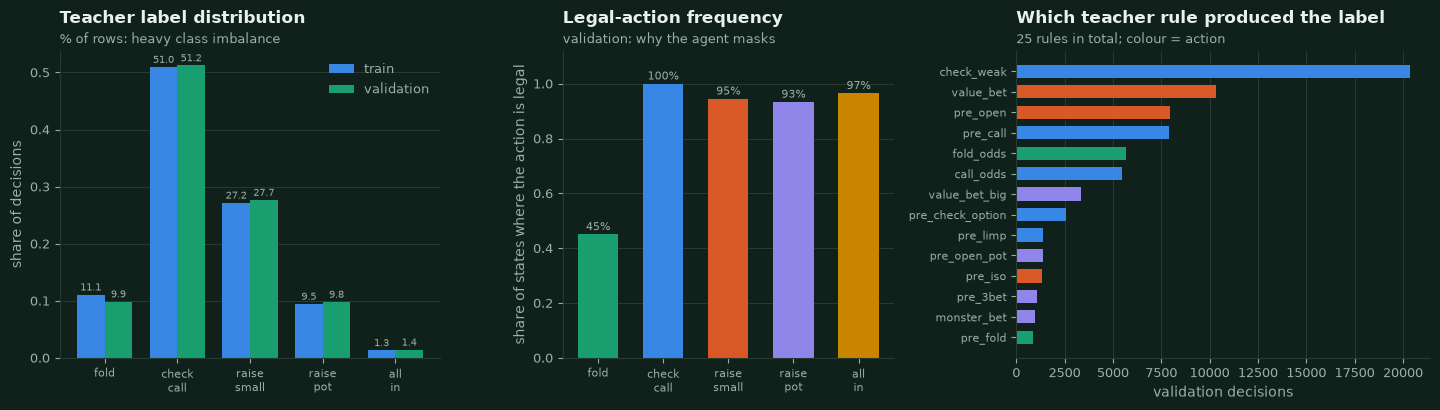

Decisions by street (validation, in brackets train): preflop 35.2% (36.2%); flop 29.6% (30.6%); turn 20.0% (19.3%); river 15.2% (13.9%).

In [7]:
def split_summary(frame: pd.DataFrame) -> dict:
    labels = frame["label"].to_numpy()
    legal = frame[[f"legal_{a}" for a in ACTIONS]].to_numpy(bool)
    return {
        "rows": len(frame), "hands": frame["hand_id"].nunique(), "decisions per hand": len(frame) / frame["hand_id"].nunique(),
        "label_share": np.bincount(labels, minlength=5) / len(frame), "legal_share": legal.mean(axis=0), "mean_legal": legal.sum(axis=1).mean(),
        "street_share": frame["street"].value_counts(normalize=True).sort_index().to_numpy(),
    }


summary = {"train": split_summary(TRAIN_FRAME), "val": split_summary(VAL_FRAME)}
disjoint_hands = len(set(TRAIN_FRAME["hand_id"]) & set(VAL_FRAME["hand_id"]))
val_hash_matches = content_hash(FULL[FULL["split"] == "val"]) == meta["dataset"]["val_split_sha256"]
train_label_share = summary["train"]["label_share"]
imbalance = float(train_label_share.max() / train_label_share.min())
table = pd.DataFrame(
    {
        "split": ["train", "validation"],
        "rows": [f"{summary[s]['rows']:,}" for s in ("train", "val")],
        "hands": [f"{summary[s]['hands']:,}" for s in ("train", "val")],
        "decisions / hand": [f"{summary[s]['decisions per hand']:.2f}" for s in ("train", "val")],
        "mean legal actions": [f"{summary[s]['mean_legal']:.2f}" for s in ("train", "val")],
        **{a: [pct(summary[s]["label_share"][i]) for s in ("train", "val")] for i, a in enumerate(ACTIONS)},
    }
)
display(Markdown(
    f"**[data]** Label distribution per split (share of the rows whose teacher label is that action). Train and validation hand ids are disjoint ({disjoint_hands} shared hands); "
    f"the validation split loaded here is byte-identical (content SHA-256) to the one the saved metrics were computed on: **{val_hash_matches}**. "
    f"The most frequent class (`{ACTIONS[int(train_label_share.argmax())]}`) is {imbalance:.0f}x as frequent as the rarest (`{ACTIONS[int(train_label_share.argmin())]}`)."
))
display(md_table(table))

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2), gridspec_kw={"width_ratios": [1.15, 1.0, 1.25]})
ax = axes[0]
width = 0.38
x = np.arange(5)
for k, (name, color) in enumerate((("train", nbp.SERIES[1]), ("val", nbp.ACCENT))):
    bars = ax.bar(x + (k - 0.5) * width, summary[name]["label_share"], width, color=color, label="train" if name == "train" else "validation")
    for xi, value in zip(x + (k - 0.5) * width, summary[name]["label_share"]):
        ax.annotate(f"{100 * value:.1f}", (xi, value), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7.5, color=nbp.MUTED)
ax.set_xticks(x, [a.replace("_", "\n") for a in ACTIONS], fontsize=8)
ax.set_ylabel("share of decisions")
ax.legend()
ax.grid(axis="x", visible=False)
nbp.title(ax, "Teacher label distribution", "% of rows: heavy class imbalance")
ax = axes[1]
legal_share = summary["val"]["legal_share"]
ax.bar(x, legal_share, color=[ACTION_COLORS[a] for a in ACTIONS], width=0.62)
for xi, value in zip(x, legal_share):
    ax.annotate(f"{100 * value:.0f}%", (xi, value), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=nbp.MUTED)
ax.set_xticks(x, [a.replace("_", "\n") for a in ACTIONS], fontsize=8)
ax.set_ylim(0, 1.12)
ax.set_ylabel("share of states where the action is legal")
ax.grid(axis="x", visible=False)
nbp.title(ax, "Legal-action frequency", "validation: why the agent masks")
ax = axes[2]
rule_counts = VAL_FRAME["teacher_rule"].astype(str).value_counts()
label_of_rule = VAL_FRAME.groupby(VAL_FRAME["teacher_rule"].astype(str))["label"].agg(lambda s: int(s.mode().iloc[0]))
top_rules = rule_counts.head(14)
ax.barh(range(len(top_rules)), top_rules.to_numpy(), color=[ACTION_COLORS[ACTIONS[label_of_rule[r]]] for r in top_rules.index], height=0.65)
ax.set_yticks(range(len(top_rules)), top_rules.index, fontsize=8)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("validation decisions")
nbp.title(ax, "Which teacher rule produced the label", f"{len(rule_counts)} rules in total; colour = action")
fig.tight_layout()
nbp.savefig("nb01_dataset_overview", fig)
plt.show()

display(Markdown("Decisions by street (validation, in brackets train): " + "; ".join(
    f"{name} {pct(val_share)} ({pct(train_share)})" for name, val_share, train_share in zip(
        ["preflop", "flop", "turn", "river"], summary["val"]["street_share"], summary["train"]["street_share"])) + "."))

## 3. Input features and training targets

### 3.1 The 45 features

One flat vector of 45 numbers describes a decision, identically for training and for play (the same `build_features` function is used by the dataset generator and by the agent at inference time).
Money is expressed in big blinds (clipped at a named cap so no shape function has to extrapolate), binary flags are 0/1, and the opponent model is built only from the *public* actions of **previous** hands.
Nothing in the vector reveals the opponent's cards or the undealt board - that is enforced by an automated test (`tests/test_features_leakage.py`).

In [8]:
feature_table = pd.DataFrame(
    {
        "group": [FEATURE_GROUP_OF[n].replace("_", " ") for n in FEATURE_NAMES],
        "feature": [f"`{n}`" for n in FEATURE_NAMES],
        "range": [f"{{0, 1}}" if FEATURE_RANGES[n] == (0.0, 1.0) and VAL_FRAME[n].nunique() <= 2 else f"[{FEATURE_RANGES[n][0]:g}, {FEATURE_RANGES[n][1]:g}]" for n in FEATURE_NAMES],
        "val. median": [float(VAL_FRAME[n].median()) for n in FEATURE_NAMES],
        "meaning": [FEATURE_DESCRIPTIONS[n] for n in FEATURE_NAMES],
    }
)
group_sizes = {g: len(names) for g, names in FEATURE_GROUPS.items()}
display(Markdown("**[data]** Features by group (`range` = documented bounds that a test enforces; `val. median` from the validation split): "
                 + ", ".join(f"{g.replace('_', ' ')} {n}" for g, n in group_sizes.items()) + f" - {NUM_FEATURES} in total."))
display(md_table(feature_table, "{:.3g}"))

**[data]** Features by group (`range` = documented bounds that a test enforces; `val. median` from the validation split): hand strength 12, board 5, position 1, money 7, betting 8, history 6, opponent 6 - 45 in total.

| group | feature | range | val. median | meaning |
|---|---|---|---|---|
| hand strength | `equity` | [0, 1] | 0.485 | Chance (0-1) that my hand beats a uniformly random opponent hand at showdown, counting ties as half and all cards still to come. |
| hand strength | `preflop_percentile` | [0, 1] | 0.51 | Share (0-1) of all starting hands that are strictly weaker than my two hole cards (1 = pocket aces). |
| hand strength | `made_hand_category` | [0, 8] | 0 | Best five-card hand made so far: 0 high card, 1 pair, 2 two pair, 3 trips, 4 straight, 5 flush, 6 full house, 7 quads, 8 straight flush (preflop: 1 only for a pocket pair). |
| hand strength | `hole_high_rank` | [0, 12] | 9 | Rank of my higher hole card (0 = deuce ... 12 = ace). |
| hand strength | `hole_low_rank` | [0, 12] | 3 | Rank of my lower hole card (0 = deuce ... 12 = ace). |
| hand strength | `is_pair` | {0, 1} | 0 | 1 if my hole cards are a pocket pair. |
| hand strength | `is_suited` | {0, 1} | 0 | 1 if my two hole cards share a suit. |
| hand strength | `hole_gap` | [0, 12] | 4 | Rank distance between my hole cards (0 pair, 1 connectors, 2 one-gapper, ...). |
| hand strength | `overcards` | [0, 2] | 0 | How many of my hole cards (0-2) are higher than every board card; 0 before the flop. |
| hand strength | `pair_with_board` | {0, 1} | 0 | 1 if one of my hole cards pairs a card on the board. |
| hand strength | `flush_draw` | {0, 1} | 0 | 1 if I hold four cards of one suit (using a hole card) on the flop or turn. |
| hand strength | `straight_outs` | [0, 8] | 0 | Cards that would complete a straight using a hole card, as 0 / 4 (gutshot) / 8 (open-ended) on the flop or turn. |
| board | `street` | [0, 3] | 1 | Betting round: 0 preflop, 1 flop, 2 turn, 3 river. |
| board | `board_paired` | {0, 1} | 0 | 1 if the board shows a pair or better (any rank twice). |
| board | `board_max_suit_count` | [0, 5] | 2 | Most board cards of a single suit (3 = flush is possible, 0 before the flop). |
| board | `board_straightness` | [0, 5] | 2 | Most board ranks inside one five-rank window (3 = a straight is two cards away). |
| board | `board_high_rank` | [-1, 12] | 8 | Rank of the highest board card (0 = deuce ... 12 = ace); -1 before the flop. |
| position | `is_button` | {0, 1} | 0 | 1 if I am on the button (small blind): first to act preflop but last to act on every later street. |
| money | `pot_bb` | [0, 800] | 4 | Chips in the middle including bets this street, in big blinds. |
| money | `my_stack_bb` | [0, 400] | 98 | My chips behind, in big blinds. |
| money | `opp_stack_bb` | [0, 400] | 98 | The opponent's chips behind, in big blinds. |
| money | `effective_stack_bb` | [0, 400] | 98 | Chips that can still go in after the bet I face is called (the shorter stack), in big blinds. |
| money | `spr` | [0, 100] | 24.5 | Stack-to-pot ratio: effective stack divided by the pot after I call (low = pot-committed). |
| money | `my_commit_frac` | [0, 1] | 0.02 | Share (0-1) of my chips for this hand that are already in the pot. |
| money | `opp_commit_frac` | [0, 1] | 0.02 | Share (0-1) of the opponent's chips for this hand that are already in the pot. |
| betting | `facing_bet` | {0, 1} | 0 | 1 if I must put chips in to continue (a bet, raise or the small blind to complete). |
| betting | `facing_all_in` | {0, 1} | 0 | 1 if I face a bet and the opponent has no chips left behind. |
| betting | `can_raise` | {0, 1} | 1 | 1 if raising is possible (stacks and betting rules allow it). |
| betting | `to_call_bb` | [0, 400] | 0 | Chips I must add to call, in big blinds (0 when I can check). |
| betting | `pot_odds` | [0, 1] | 0 | Share of the final pot I would pay to call: call / (pot + call) = the equity needed to break even. |
| betting | `equity_minus_pot_odds` | [-1, 1] | 0.33 | My equity minus the pot odds: positive means calling beats a random hand's break-even price. |
| betting | `bet_fraction_of_pot` | [0, 5] | 0 | Size of the bet or raise I face as a fraction of the pot before it (0.5 = half pot, 1 = pot). |
| betting | `call_stack_fraction` | [0, 1] | 0 | Share (0-1) of my remaining chips that calling would cost (1 = a call puts me all-in). |
| history | `num_raises_street` | [0, 6] | 0 | Bets and raises made so far on this street by either player. |
| history | `num_raises_hand` | [0, 12] | 1 | Bets and raises made so far in the whole hand by either player. |
| history | `i_raised_this_street` | {0, 1} | 0 | 1 if I have already bet or raised on this street. |
| history | `opp_raised_this_street` | {0, 1} | 0 | 1 if the opponent has already bet or raised on this street. |
| history | `i_have_initiative` | {0, 1} | 0 | 1 if I made the last bet or raise on an earlier street (e.g. I was the preflop aggressor on the flop). |
| history | `opp_has_initiative` | {0, 1} | 0 | 1 if the opponent made the last bet or raise on an earlier street. |
| opponent | `opp_vpip` | [0, 1] | 0.882 | Share of hands the opponent voluntarily puts chips in preflop (smoothed). |
| opponent | `opp_pfr` | [0, 1] | 0.398 | Share of hands the opponent raises preflop (smoothed). |
| opponent | `opp_aggression` | [0, 1] | 0.651 | Opponent's postflop bets+raises divided by bets+raises+calls (smoothed). |
| opponent | `opp_fold_to_bet` | [0, 1] | 0.131 | Share of the opponent's decisions facing a bet or raise that were folds (smoothed). |
| opponent | `opp_showdown_rate` | [0, 1] | 0.429 | Share of hands that reached a showdown (smoothed). |
| opponent | `opp_log_hands` | [0, 12] | 5.72 | log(1 + number of hands observed against this opponent): how much to trust the opponent statistics. |

### 3.2 The target: five abstract actions

| index | action | meaning | concrete size |
|---|---|---|---|
| 0 | `fold` | give up the hand | - (never legal when a free check exists) |
| 1 | `check_call` | check, or match the bet | - |
| 2 | `raise_small` | bet / raise about half the pot | `pot_fraction_raise_to(0.5, ...)` |
| 3 | `raise_pot` | bet / raise about the pot | `pot_fraction_raise_to(1.0, ...)` |
| 4 | `all_in` | put every chip in | the legal maximum |

Distinct abstract actions always map to distinct chip amounts (duplicates are removed in the order all-in > raise_small > raise_pot), and short stacks or minimum-raise rules can make some of them unavailable
- the **legal mask**. The model never needs to learn legality: the agent restricts its arg-max to the legal actions, and the training metrics are reported after the same masking.
The raw model nevertheless puts very little probability on illegal actions - see section 5.1.

### 3.3 The teacher's logic (the ground truth the EBM imitates)

The teacher is a pure function of the 45 features and the legal mask, so it can be recomputed for any row. It reads **equity against a random hand**, corrects it for what the opponent's *bet* implies
(a bettor holds a stronger-than-random range: the larger the bet and the more raises, the more equity is subtracted, partly given back when the opponent has been very aggressive), and compares it with the
**pot-odds price**. Before the flop it uses the starting-hand percentile with position-dependent thresholds. All thresholds live in `TeacherParams`:

In [9]:
P = CANONICAL_PARAMS
rule_rows = [
    ("preflop, button, first to act", "shove at <= `push_fold_bb` bb effective stack if percentile >= `push_pct`; else raise to pot if >= `open_pot_pct`; raise half pot if >= `open_pct`; limp if >= `limp_pct`; else fold",
     f"{P.push_fold_bb:g} bb; push {P.push_pct}; open {P.open_pct}; open pot {P.open_pot_pct}; limp {P.limp_pct}"),
    ("preflop, big blind after a limp", "raise to pot if percentile >= `iso_pot_pct`, raise half pot if >= `iso_pct`, else check", f"iso {P.iso_pct}; iso pot {P.iso_pot_pct}"),
    ("preflop, facing a raise", "shove premium (>= `shove_pct`, 3-bet or later) / 3-bet (>= `threebet_pct`) / 4-bet (>= `fourbet_pct`), else call iff equity minus a range penalty >= pot odds + `pre_call_margin`",
     f"3-bet {P.threebet_pct}; 4-bet {P.fourbet_pct}; shove {P.shove_pct}; margin {P.pre_call_margin}; penalty <= {P.pre_penalty_max}"),
    ("postflop, checked to", "all-in / pot bet with a monster (equity >= `monster_equity`); pot bet (>= `pot_bet_equity`, or `wet_pot_equity` on a wet board); half-pot value bet if equity >= value line "
     "(`value_equity` + `value_fold_slope` x (opponent fold-to-bet - neutral), clipped to [0.52, 0.92]); semi-bluff a strong draw; continuation-bet a dry flop; else check",
     f"monster {P.monster_equity}; pot {P.pot_bet_equity} (wet {P.wet_pot_equity}); value {P.value_equity}, slope {P.value_fold_slope}; c-bet equity >= {P.cbet_min_equity}, fold >= {P.cbet_min_fold}"),
    ("postflop, facing a bet", "raise for value if equity >= `raise_equity` (+ `raise_extra` per extra raise), semi-bluff-raise a combo draw, else call iff equity minus penalty >= pot odds + `call_margin` (+ `oop_margin` out of position); "
     "penalty = `penalty_max` x b / (b + `penalty_half`) + `raise_penalty` per extra raise - `aggression_slope` x (opponent aggression - neutral) - `draw_credit` with a strong draw, fading to 0 between `penalty_relief_equity` and equity 1",
     f"raise {P.raise_equity}; margin {P.call_margin} (+{P.oop_margin} oop); penalty max {P.penalty_max}, half {P.penalty_half}; aggression slope {P.aggression_slope}; relief from equity {P.penalty_relief_equity}"),
]
display(Markdown("**The rule cascade** (thresholds read from `CANONICAL_PARAMS`; \"percentile\" = share of starting hands that are weaker, \"equity\" = chance to beat a random hand):"))
display(md_table(pd.DataFrame(rule_rows, columns=["situation", "rule (checked in this order)", "key parameters"])))
rule_freq = VAL_FRAME["teacher_rule"].astype(str).value_counts(normalize=True)
teacher_reproduces = float(np.mean([int(TEACHER.decide_features(VAL.X[i], VAL.legal[i]).action) == VAL.y[i] for i in range(len(VAL.y))]))
display(Markdown(
    f"**[data]** The teacher has {len(rule_freq)} distinct deciding rules in the validation data; the five most frequent cover {pct(rule_freq.head(5).sum())} of the decisions "
    f"({', '.join(f'`{r}` {pct(v)}' for r, v in rule_freq.head(5).items())}). "
    f"Re-running `TeacherPolicy.decide_features` on the stored feature vector reproduces the stored label for **{pct(teacher_reproduces, 3)}** of the {len(VAL.y):,} validation rows - "
    f"so the ground truth is exactly recoverable, and a model that sees the same features can *in principle* reproduce the teacher perfectly."
))

**The rule cascade** (thresholds read from `CANONICAL_PARAMS`; "percentile" = share of starting hands that are weaker, "equity" = chance to beat a random hand):

| situation | rule (checked in this order) | key parameters |
|---|---|---|
| preflop, button, first to act | shove at <= `push_fold_bb` bb effective stack if percentile >= `push_pct`; else raise to pot if >= `open_pot_pct`; raise half pot if >= `open_pct`; limp if >= `limp_pct`; else fold | 12 bb; push 0.3; open 0.18; open pot 0.88; limp 0.06 |
| preflop, big blind after a limp | raise to pot if percentile >= `iso_pot_pct`, raise half pot if >= `iso_pct`, else check | iso 0.6; iso pot 0.9 |
| preflop, facing a raise | shove premium (>= `shove_pct`, 3-bet or later) / 3-bet (>= `threebet_pct`) / 4-bet (>= `fourbet_pct`), else call iff equity minus a range penalty >= pot odds + `pre_call_margin` | 3-bet 0.82; 4-bet 0.96; shove 0.985; margin 0.03; penalty <= 0.12 |
| postflop, checked to | all-in / pot bet with a monster (equity >= `monster_equity`); pot bet (>= `pot_bet_equity`, or `wet_pot_equity` on a wet board); half-pot value bet if equity >= value line (`value_equity` + `value_fold_slope` x (opponent fold-to-bet - neutral), clipped to [0.52, 0.92]); semi-bluff a strong draw; continuation-bet a dry flop; else check | monster 0.93; pot 0.84 (wet 0.76); value 0.57, slope 0.4; c-bet equity >= 0.38, fold >= 0.35 |
| postflop, facing a bet | raise for value if equity >= `raise_equity` (+ `raise_extra` per extra raise), semi-bluff-raise a combo draw, else call iff equity minus penalty >= pot odds + `call_margin` (+ `oop_margin` out of position); penalty = `penalty_max` x b / (b + `penalty_half`) + `raise_penalty` per extra raise - `aggression_slope` x (opponent aggression - neutral) - `draw_credit` with a strong draw, fading to 0 between `penalty_relief_equity` and equity 1 | raise 0.86; margin 0.03 (+0.02 oop); penalty max 0.6, half 0.25; aggression slope 0.8; relief from equity 0.7 |

**[data]** The teacher has 25 distinct deciding rules in the validation data; the five most frequent cover 70.8% of the decisions (`check_weak` 27.6%, `value_bet` 14.0%, `pre_open` 10.7%, `pre_call` 10.7%, `fold_odds` 7.7%). Re-running `TeacherPolicy.decide_features` on the stored feature vector reproduces the stored label for **100.000%** of the 73,777 validation rows - so the ground truth is exactly recoverable, and a model that sees the same features can *in principle* reproduce the teacher perfectly.

### 3.4 Correlations and redundancy among the features

The feature set is deliberately redundant: `equity_minus_pot_odds` is *by construction* `equity - pot_odds`, `pot_odds` and `bet_fraction_of_pot` are two views of the same ratio,
`preflop_percentile` and preflop `equity` rank the same 169 hand classes, and stack features overlap. An additive model spreads the credit of a redundant group over several curves, so individual
shape functions of correlated features must be read *together* (the saved `README_training.md` says the same). The next cell verifies the identities and quantifies the redundancy.

**[data]** Identities on the validation split: `equity_minus_pot_odds = equity - pot_odds` holds to within 6.0e-08; `pot_odds = b / (1 + 2b)` with `b = bet_fraction_of_pot` holds to within 1.9e-08 on all 32,144 states that face an uncapped bet; and in the 54.9% of states where the player is *not* facing a bet, `equity_minus_pot_odds` and `equity` are **the same number**. 25 of the 2,025 feature pairs have a Spearman correlation of at least 0.9 in absolute value. The ten strongest:

| feature A | feature B | Spearman rho |
|---|---|---|
| `pot_odds` | `bet_fraction_of_pot` | +1.000 |
| `to_call_bb` | `call_stack_fraction` | +0.997 |
| `opp_stack_bb` | `effective_stack_bb` | +0.996 |
| `spr` | `opp_commit_frac` | -0.991 |
| `num_raises_street` | `opp_raised_this_street` | +0.990 |
| `facing_all_in` | `can_raise` | -0.989 |
| `to_call_bb` | `pot_odds` | +0.965 |
| `to_call_bb` | `bet_fraction_of_pot` | +0.965 |
| `bet_fraction_of_pot` | `call_stack_fraction` | +0.960 |
| `pot_odds` | `call_stack_fraction` | +0.960 |

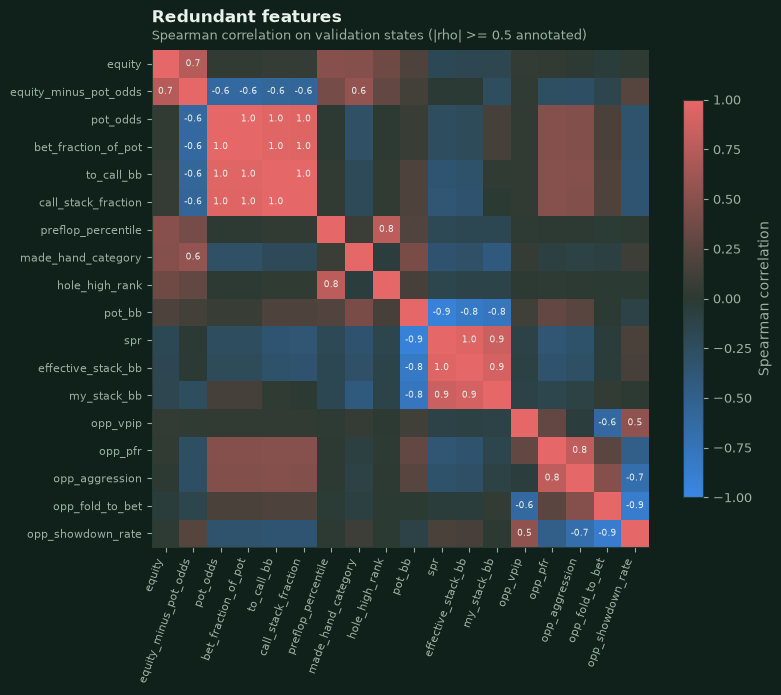

In [10]:
Xv = VAL_FRAME[list(FEATURE_NAMES)].astype(float)
emp_error = float(np.abs(Xv["equity_minus_pot_odds"] - (Xv["equity"] - Xv["pot_odds"])).max())
facing = Xv["facing_bet"] == 1
uncapped = facing & (Xv["bet_fraction_of_pot"] < 4.99)
relation_error = float(np.abs(Xv.loc[uncapped, "pot_odds"] - Xv.loc[uncapped, "bet_fraction_of_pot"] / (1 + 2 * Xv.loc[uncapped, "bet_fraction_of_pot"])).max())
identical_share = float(((Xv["equity_minus_pot_odds"] - Xv["equity"]).abs() < 1e-6).mean())
corr = Xv.loc[:, Xv.nunique() > 1].corr(method="spearman")
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().rename("rho").reset_index()
pairs.columns = ["feature A", "feature B", "rho"]
strongest = pairs.reindex(pairs["rho"].abs().sort_values(ascending=False).index).head(10)
n_pairs_90 = int((pairs["rho"].abs() >= 0.9).sum())
display(Markdown(
    f"**[data]** Identities on the validation split: `equity_minus_pot_odds = equity - pot_odds` holds to within {emp_error:.1e}; `pot_odds = b / (1 + 2b)` with `b = bet_fraction_of_pot` holds to within {relation_error:.1e} on "
    f"all {int(uncapped.sum()):,} states that face an uncapped bet; and in the {pct(identical_share)} of states where the player is *not* facing a bet, `equity_minus_pot_odds` and `equity` are **the same number**. "
    f"{n_pairs_90} of the {len(pairs):,} feature pairs have a Spearman correlation of at least 0.9 in absolute value. The ten strongest:"
))
display(md_table(pd.DataFrame({"feature A": [f"`{a}`" for a in strongest["feature A"]], "feature B": [f"`{b}`" for b in strongest["feature B"]], "Spearman rho": strongest["rho"]}), "{:+.3f}"))

SHOWN = ["equity", "equity_minus_pot_odds", "pot_odds", "bet_fraction_of_pot", "to_call_bb", "call_stack_fraction", "preflop_percentile", "made_hand_category", "hole_high_rank",
         "pot_bb", "spr", "effective_stack_bb", "my_stack_bb", "opp_vpip", "opp_pfr", "opp_aggression", "opp_fold_to_bet", "opp_showdown_rate"]
fig, ax = plt.subplots(figsize=(8.6, 7.0))
matrix = corr.loc[SHOWN, SHOWN].to_numpy()
mesh = ax.imshow(matrix, cmap=nbp.DIVERGING.reversed(), vmin=-1, vmax=1)
ax.set_xticks(range(len(SHOWN)), SHOWN, rotation=70, ha="right", fontsize=8)
ax.set_yticks(range(len(SHOWN)), SHOWN, fontsize=8)
ax.grid(False)
for i in range(len(SHOWN)):
    for j in range(len(SHOWN)):
        if abs(matrix[i, j]) >= 0.5 and i != j:
            ax.text(j, i, f"{matrix[i, j]:.1f}", ha="center", va="center", fontsize=6.5, color=nbp.TEXT)
fig.colorbar(mesh, ax=ax, shrink=0.8, label="Spearman correlation")
nbp.title(ax, "Redundant features", "Spearman correlation on validation states (|rho| >= 0.5 annotated)")
fig.tight_layout()
nbp.savefig("nb01_feature_correlation", fig)
plt.show()

### 3.5 Why legal-action masking and class weighting are needed

* **Masking.** Whether an action is legal depends on the stacks and the betting round (e.g. no raise after the opponent went all-in, no pot raise if it equals the all-in, folding is illegal when a check is free).
  An additive model of 45 features can learn most of this from `can_raise`, `facing_bet`, `spr`, ... but never perfectly, and an illegal action would be a rules violation, not a mistake. The agent therefore takes the arg-max over legal actions
  *only* (`LearnedPolicyAgent.act`); it never falls back to random play.
* **Class weights.** The rare decisions (all-in, pot raise, fold) are exactly the high-stakes ones, but plain log-loss minimisation is dominated by `check_call`. Rows are weighted by
  `(n / (K * class count)) ** 0.5`: a compromise between no weighting (power 0) and fully balanced classes (power 1); the saved tuning table (section 4.4) measured both extremes.

In [11]:
weights = pd.DataFrame({"action": ACTIONS, "train share": train_label_share, "legal in val.": summary["val"]["legal_share"],
                        "class weight (power 0.5)": [meta["class_weights"][a] for a in ACTIONS]})
weights["action"] = [f"`{a}`" for a in weights["action"]]
display(Markdown(f"**[saved] [data]** The weights applied to the {meta['n_train_rows']:,} training rows of the final fit (power {meta['class_weight_power']}); the rarest action is up-weighted {weights['class weight (power 0.5)'].max() / weights['class weight (power 0.5)'].min():.1f}x relative to the most frequent one:"))
display(md_table(weights, "{:.3f}"))

**[saved] [data]** The weights applied to the 245,346 training rows of the final fit (power 0.5); the rarest action is up-weighted 5.9x relative to the most frequent one:

| action | train share | legal in val. | class weight (power 0.5) |
|---|---|---|---|
| `fold` | 0.111 | 0.451 | 1.313 |
| `check_call` | 0.510 | 1.000 | 0.629 |
| `raise_small` | 0.272 | 0.945 | 0.860 |
| `raise_pot` | 0.095 | 0.934 | 1.454 |
| `all_in` | 0.013 | 0.965 | 3.744 |

## 4. Model configuration and training

### 4.1 The EBM settings and what the training cost `[saved]`

The hyper-parameters were chosen on the validation split with a series of one-seed behaviour-cloning fits (the table of section 4.4 is that record).
They are stored with the artifact (`config.json`) and printed here with the meaning each one has for the model:

In [12]:
MEANING = {
    "max_rounds": "boosting rounds cap; one round = one small step for every term, cycling through the features",
    "learning_rate": "size of each boosting step",
    "interactions": "number of pairwise terms picked by InterpretML's FAST ranking after the main effects are fitted (0 = purely additive)",
    "outer_bags": "bagged sub-models whose score tables are averaged into the final shape functions (smooths them; also gives the standard deviation shown in section 6)",
    "inner_bags": "extra bagging inside every outer bag (0 = off)",
    "max_bins": "maximum number of bins (steps) per feature in a shape function",
    "max_interaction_bins": "bins per feature inside a pairwise table; the main driver of the file size (24 bins -> 4 MB, 64 bins -> 16 MB at equal accuracy)",
    "min_samples_leaf": "minimum rows (weight) in a bin split",
    "max_leaves": "2 = every boosting step is a single cut: the classic EBM",
    "early_stopping_rounds": "stop a stage when the held-out loss has not improved for this many rounds",
    "validation_fraction": "share of the training HANDS each outer bag holds out for early stopping (never the dataset's validation split)",
}
settings = pd.DataFrame({"parameter": [f"`{k}`" for k in run_cfg["ebm_params"]], "value": [f"{v:g}" for v in run_cfg["ebm_params"].values()], "meaning": [MEANING[k] for k in run_cfg["ebm_params"]]})
settings.loc[len(settings)] = ["`class_weight_power`", f"{run_cfg['class_weight_power']:g}", "rows weighted by (n / (K * class count)) ** power (section 3.5)"]
settings.loc[len(settings)] = ["`max_train_rows`", f"{run_cfg['max_train_rows']:,}", "behaviour-cloning rows (whole hands) kept for training; the same budget as the XGBoost agent"]
display(Markdown("**[saved]** `config.json` -> the `ExplainableBoostingClassifier` arguments of the committed model:"))
display(md_table(settings))

rounds = meta["dagger"]
cost = pd.DataFrame(
    {
        "round": [r["round"] for r in rounds],
        "training rows": [f"{r['n_train_rows']:,}" for r in rounds],
        "fit time": [f"{r['fit_seconds']:.0f} s" for r in rounds],
        "main-effect rounds used (cap {})".format(ebm_params["max_rounds"]): [f"{r['main_effect_rounds_mean']:.0f}" for r in rounds],
        "interaction rounds used": [f"{r['interaction_rounds_mean']:.0f}" for r in rounds],
        "hit the round cap": [("yes" if r["main_effect_rounds_hit_cap"] or r["interaction_rounds_hit_cap"] else "no") for r in rounds],
    }
)
n_params = sum(int(np.asarray(s).size) for s in MODEL.term_scores_)
main_params = sum(int(np.asarray(s).size) for s, f in zip(MODEL.term_scores_, MODEL.term_features_) if len(f) == 1)
display(Markdown(
    f"**[saved]** Fit time per DAgger round (10 threads): the whole fit of the committed round-{meta['selected_round']} model took {meta['training_time_s']:.0f} s, all four fits together {meta['training_time_s_all_rounds'] / 60:.1f} min, "
    f"the complete pipeline (fits + on-policy data collection + validation games) {meta['total_pipeline_time_s'] / 60:.1f} min. The final model has {len(MODEL.term_features_)} additive terms and **{n_params:,} stored scores** "
    f"({main_params:,} in the 45 shape functions, {n_params - main_params:,} in the {meta['n_interaction_terms']} pairwise tables; each score is one log-odds number per bin and action) in a {meta['model_file_bytes'] / 1e6:.1f} MB file; "
    f"one decision takes {meta['inference']['predict_proba_median_ms']:.1f} ms (median `predict_proba`, {meta['inference']['term_decomposition_median_ms']:.1f} ms for the full term decomposition)."
))
display(md_table(cost))
display(Markdown(
    f"Boosting **never stopped early** ({sum(r['main_effect_rounds_hit_cap'] or r['interaction_rounds_hit_cap'] for r in rounds)} of {len(rounds)} rounds hit the cap): the teacher's labels are noise-free, so the held-out loss keeps falling, "
    f"and `max_rounds` - not early stopping - is the effective regularizer. The consequence is visible in section 6: sharp, threshold-like shape functions with log-odds contributions of tens of units."
))

**[saved]** `config.json` -> the `ExplainableBoostingClassifier` arguments of the committed model:

| parameter | value | meaning |
|---|---|---|
| `max_rounds` | 300 | boosting rounds cap; one round = one small step for every term, cycling through the features |
| `learning_rate` | 0.1 | size of each boosting step |
| `interactions` | 40 | number of pairwise terms picked by InterpretML's FAST ranking after the main effects are fitted (0 = purely additive) |
| `outer_bags` | 10 | bagged sub-models whose score tables are averaged into the final shape functions (smooths them; also gives the standard deviation shown in section 6) |
| `inner_bags` | 0 | extra bagging inside every outer bag (0 = off) |
| `max_bins` | 128 | maximum number of bins (steps) per feature in a shape function |
| `max_interaction_bins` | 24 | bins per feature inside a pairwise table; the main driver of the file size (24 bins -> 4 MB, 64 bins -> 16 MB at equal accuracy) |
| `min_samples_leaf` | 4 | minimum rows (weight) in a bin split |
| `max_leaves` | 2 | 2 = every boosting step is a single cut: the classic EBM |
| `early_stopping_rounds` | 50 | stop a stage when the held-out loss has not improved for this many rounds |
| `validation_fraction` | 0.15 | share of the training HANDS each outer bag holds out for early stopping (never the dataset's validation split) |
| `class_weight_power` | 0.5 | rows weighted by (n / (K * class count)) ** power (section 3.5) |
| `max_train_rows` | 150,000 | behaviour-cloning rows (whole hands) kept for training; the same budget as the XGBoost agent |

**[saved]** Fit time per DAgger round (10 threads): the whole fit of the committed round-3 model took 205 s, all four fits together 10.8 min, the complete pipeline (fits + on-policy data collection + validation games) 14.1 min. The final model has 85 additive terms and **71,470 stored scores** (11,470 in the 45 shape functions, 60,000 in the 40 pairwise tables; each score is one log-odds number per bin and action) in a 3.7 MB file; one decision takes 0.6 ms (median `predict_proba`, 0.6 ms for the full term decomposition).

| round | training rows | fit time | main-effect rounds used (cap 300) | interaction rounds used | hit the round cap |
|---|---|---|---|---|---|
| 0 | 150,000 | 114 s | 300 | 241 | yes |
| 1 | 180,458 | 146 s | 300 | 272 | yes |
| 2 | 212,917 | 183 s | 300 | 294 | yes |
| 3 | 245,346 | 205 s | 300 | 278 | yes |

Boosting **never stopped early** (4 of 4 rounds hit the cap): the teacher's labels are noise-free, so the held-out loss keeps falling, and `max_rounds` - not early stopping - is the effective regularizer. The consequence is visible in section 6: sharp, threshold-like shape functions with log-odds contributions of tens of units.

### 4.2 DAgger: aggregating the states the model itself visits `[saved]`

**The problem.** Plain behaviour cloning trains on states visited by the *teacher-like* behaviour policies. A learner that makes a small mistake drifts into states those policies rarely visit,
where it has seen little data (*covariate shift*); mistakes then compound.

**DAgger** (Dataset Aggregation, Ross et al. 2011): (1) fit a model on the current rows; (2) let *that model* play hands, but have the **teacher label every state the model visits**; (3) append those rows and refit from scratch; repeat.
Early rounds mix the teacher back in per decision with probability `beta` (here 0.5, halving every round) so the model is not thrown into hopeless states at once.
It is the principled "better than pure imitation" option inside supervised learning - it needs no reward and no change of the model class - which is why this project uses it for the EBM and the XGBoost agent.
**Whether it actually helps is an empirical question**, so every round is evaluated on held-out validation data: agreement with the teacher on the dataset's validation states *and* on fresh states the round's own EBM visits (4,000 validation hands, seeds no training step used),
plus duplicate-deal BB/100 against four opponents (500 pairs each, namespace `dataset_val`, identical deals in every round). The round with the best mean validation BB/100 was kept (ties: the earlier round).

> **Legacy protocol warning.** The BB/100 columns of this section were computed at training time with the *legacy single-table duplicate protocol* (section 5.4 explains the artifact it contains). They are **informational**:
> the DAgger candidates were near-tied, and absolute BB/100 against the teacher from that protocol should not be quoted. The imitation and on-policy agreement columns are unaffected by it.

**[saved]** The per-round table of `metadata.json` (agreement = legal-masked accuracy against the teacher; positive *gap* = the model agrees less on the states it visits itself than on the dataset's validation states). The three BB/100 columns come from the **legacy single-table protocol (informational, see `evaluation_protocol_note`)**.

> `evaluation_protocol_note` in `metadata.json`: policy_validation and every dagger[*].policy_validation entry were computed with the legacy single-table duplicate protocol (the two hands of a deal shared agents and opponent trackers), which gives the second-moving agent a small advantage (roughly +10 to +13 BB/100 between identical adaptive agents). They are informational: the DAgger round was selected among near-tied candidates. Tournament results in artifacts/tournaments use the corrected two-table protocol. See docs/METHODOLOGY.md, section 5.

| round | rows added | beta of added rows | agreement, dataset val. | agreement, own states | gap (shift) | mean BB/100 (4 opp., legacy protocol) | BB/100 vs teacher [95% CI] (legacy) | paired vs round 0, vs teacher (legacy) |
|---|---|---|---|---|---|---|---|---|
| 0 | 0 | - | 97.92% | 97.81% | +0.11 pt | +762 | +106 [+45, +167] | - |
| 1 | 30,458 | 0.500 | 98.07% | 98.13% | -0.06 pt | +767 | +37 [-31, +105] | -69 [-124, -15] |
| 2 | 32,459 | 0.250 | 98.33% | 98.12% | +0.21 pt | +728 | +15 [-46, +75] | -91 [-152, -31] |
| **3 (kept)** | 32,429 | 0.125 | 97.86% | 97.92% | -0.05 pt | +772 | +61 [+7, +114] | -46 [-98, +7] |

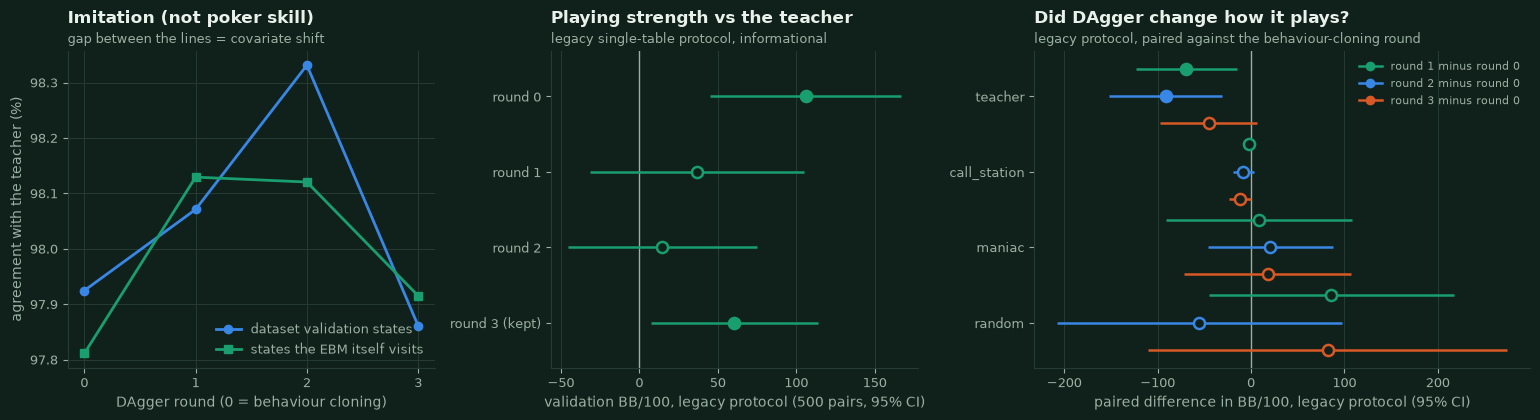

**Did DAgger help? (what the saved numbers say)**

* *Covariate shift is small here.* The behaviour-cloning model agrees with the teacher on 97.81% of the states it visits itself against 97.92% on the dataset's validation states (gap +0.11 points). The behaviour mixture of the dataset (random, exploring and style-shifted players) had already covered most of the states the EBM reaches.
* *Agreement moved by tenths of a point, not monotonically.* On the model's own states the change relative to round 0 is +0.32, +0.31, +0.10 points (rounds 1-3); on the dataset's validation states +0.15, +0.41, -0.06 points. The four rounds span 0.47 points on the dataset-validation metric although they differ only by the number of added DAgger rows, i.e. changes of this size are within training noise.
* *Playing strength (legacy protocol, informational): no resolvable gain.* Mean validation BB/100 over the four opponents: round 0 +762, round 1 +767, round 2 +728, round 3 +772 - a spread of 44 BB/100, dominated by the maniac and random opponents whose per-opponent intervals are several hundred BB/100 wide. Paired against round 0 on identical deals, 0 of 12 (round, opponent) cells are significantly better, 2 significantly worse (round 1 vs teacher, round 2 vs teacher). The legacy protocol favours the second-moving agent of each pair, so even the paired differences are not used for any conclusion here.
* *Selection.* The kept round (3) was chosen as the one with the best mean validation BB/100 - a near-tie among noisy numbers (winner's curse): its stored validation results are slightly optimistic and come from the legacy protocol, which is why section 5.4 re-evaluates on fresh deals with the corrected protocol.

**Reading.** The data give **no evidence that DAgger improved the EBM** over behaviour cloning: imitation changed by a few tenths of a point, and the (legacy-protocol, near-tied) BB/100 numbers show no resolvable difference. That is a statement about *this* teacher, dataset and sample size, not about DAgger in general - the dataset already used exploring behaviour policies, and the teacher's labels are so regular that the first model is already a very good copy.

In [13]:
opponents = list(meta["policy_validation"]["opponents"])
dag_table = pd.DataFrame(
    {
        "round": [("**%d (kept)**" if r["selected"] else "%d") % r["round"] for r in rounds],
        "rows added": [f"{r['n_dagger_rows_added']:,}" for r in rounds],
        "beta of added rows": ["-" if r["teacher_beta_of_added_rows"] is None else f"{r['teacher_beta_of_added_rows']:.3f}" for r in rounds],
        "agreement, dataset val.": [pct(r["bc_validation"]["masked_accuracy"], 2) for r in rounds],
        "agreement, own states": [pct(r["on_policy_validation"]["masked_accuracy"], 2) for r in rounds],
        "gap (shift)": [f"{100 * (r['bc_validation']['masked_accuracy'] - r['on_policy_validation']['masked_accuracy']):+.2f} pt" for r in rounds],
        "mean BB/100 (4 opp., legacy protocol)": [f"{r['mean_bb_per_100']:+.0f}" for r in rounds],
        "BB/100 vs teacher [95% CI] (legacy)": [ci_text(r["policy_validation"]["teacher"]["bb_per_100"], *r["policy_validation"]["teacher"]["ci95_pairs"]) for r in rounds],
        "paired vs round 0, vs teacher (legacy)": ["-" if "paired_vs_bc" not in r else ci_text(r["paired_vs_bc"]["teacher"]["bb_per_100"], *r["paired_vs_bc"]["teacher"]["ci95_pairs"]) for r in rounds],
    }
)
display(Markdown("**[saved]** The per-round table of `metadata.json` (agreement = legal-masked accuracy against the teacher; positive *gap* = the model agrees less on the states it visits itself than on the dataset's validation states). "
                 "The three BB/100 columns come from the **legacy single-table protocol (informational, see `evaluation_protocol_note`)**."))
if meta.get("evaluation_protocol_note"):
    display(Markdown("> `evaluation_protocol_note` in `metadata.json`: " + meta["evaluation_protocol_note"]))
display(md_table(dag_table))

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3), gridspec_kw={"width_ratios": [1.0, 1.0, 1.35]})
ax = axes[0]
index = [r["round"] for r in rounds]
ax.plot(index, [100 * r["bc_validation"]["masked_accuracy"] for r in rounds], marker="o", color=nbp.SERIES[1], label="dataset validation states")
ax.plot(index, [100 * r["on_policy_validation"]["masked_accuracy"] for r in rounds], marker="s", color=nbp.ACCENT, label="states the EBM itself visits")
ax.set_xticks(index)
ax.set_xlabel("DAgger round (0 = behaviour cloning)")
ax.set_ylabel("agreement with the teacher (%)")
ax.legend(loc="lower right")
nbp.title(ax, "Imitation (not poker skill)", "gap between the lines = covariate shift")
ax = axes[1]
nbp.forest_plot(ax, [f"round {r['round']}" + (" (kept)" if r["selected"] else "") for r in rounds],
                {"EBM vs teacher": ([r["policy_validation"]["teacher"]["bb_per_100"] for r in rounds], [r["policy_validation"]["teacher"]["ci95_pairs"][0] for r in rounds], [r["policy_validation"]["teacher"]["ci95_pairs"][1] for r in rounds])},
                x_label="validation BB/100, legacy protocol (500 pairs, 95% CI)", legend=False)
nbp.title(ax, "Playing strength vs the teacher", "legacy single-table protocol, informational")
ax = axes[2]
paired = {f"round {r['round']} minus round 0": ([r["paired_vs_bc"][o]["bb_per_100"] for o in opponents], [r["paired_vs_bc"][o]["ci95_pairs"][0] for o in opponents], [r["paired_vs_bc"][o]["ci95_pairs"][1] for o in opponents]) for r in rounds if "paired_vs_bc" in r}
nbp.forest_plot(ax, opponents, paired, x_label="paired difference in BB/100, legacy protocol (95% CI)", legend=False)
ax.legend(handles=[Line2D([0], [0], color=nbp.SERIES[k], marker="o", linewidth=1.8, label=name) for k, name in enumerate(paired)], loc="upper right", fontsize=8)
nbp.title(ax, "Did DAgger change how it plays?", "legacy protocol, paired against the behaviour-cloning round")
fig.tight_layout()
nbp.savefig("nb01_dagger_rounds", fig)
plt.show()

# the numbers behind the discussion
first, last_round = rounds[0], rounds[-1]
shift = [r["bc_validation"]["masked_accuracy"] - r["on_policy_validation"]["masked_accuracy"] for r in rounds]
paired_cells = [(r["round"], o, r["paired_vs_bc"][o]) for r in rounds if "paired_vs_bc" in r for o in opponents]
paired_better = [(k, o) for k, o, c in paired_cells if c["ci95_pairs"][0] > 0]
paired_worse = [(k, o) for k, o, c in paired_cells if c["ci95_pairs"][1] < 0]
on_policy_delta = [100 * (r["on_policy_validation"]["masked_accuracy"] - first["on_policy_validation"]["masked_accuracy"]) for r in rounds]
val_delta = [100 * (r["bc_validation"]["masked_accuracy"] - first["bc_validation"]["masked_accuracy"]) for r in rounds]
mean_bb = [r["mean_bb_per_100"] for r in rounds]
dagger_helped = bool(paired_better) and not paired_worse
display(Markdown(
    f"**Did DAgger help? (what the saved numbers say)**\n\n"
    f"* *Covariate shift is small here.* The behaviour-cloning model agrees with the teacher on {pct(first['on_policy_validation']['masked_accuracy'], 2)} of the states it visits itself against {pct(first['bc_validation']['masked_accuracy'], 2)} on the dataset's validation states (gap {100 * shift[0]:+.2f} points). "
    f"The behaviour mixture of the dataset (random, exploring and style-shifted players) had already covered most of the states the EBM reaches.\n"
    f"* *Agreement moved by tenths of a point, not monotonically.* On the model's own states the change relative to round 0 is {', '.join(f'{d:+.2f}' for d in on_policy_delta[1:])} points (rounds 1-{len(rounds) - 1}); "
    f"on the dataset's validation states {', '.join(f'{d:+.2f}' for d in val_delta[1:])} points. The four rounds span {100 * (max(r['bc_validation']['masked_accuracy'] for r in rounds) - min(r['bc_validation']['masked_accuracy'] for r in rounds)):.2f} points on the dataset-validation metric although they differ only by the number of added DAgger rows, i.e. changes of this size are within training noise.\n"
    f"* *Playing strength (legacy protocol, informational): no resolvable gain.* Mean validation BB/100 over the four opponents: {', '.join(f'round {r['round']} {r['mean_bb_per_100']:+.0f}' for r in rounds)} - a spread of {max(mean_bb) - min(mean_bb):.0f} BB/100, dominated by the maniac and random opponents whose per-opponent intervals are several hundred BB/100 wide. "
    f"Paired against round 0 on identical deals, {len(paired_better)} of {len(paired_cells)} (round, opponent) cells are significantly better, {len(paired_worse)} significantly worse"
    f"{' (' + ', '.join(f'round {k} vs {o}' for k, o in paired_worse) + ')' if paired_worse else ''}. The legacy protocol favours the second-moving agent of each pair, so even the paired differences are not used for any conclusion here.\n"
    f"* *Selection.* The kept round ({meta['selected_round']}) was chosen as the one with the best mean validation BB/100 - a near-tie among noisy numbers (winner's curse): its stored validation results are slightly optimistic and come from the legacy protocol, which is why section 5.4 re-evaluates on fresh deals with the corrected protocol.\n\n"
    f"**Reading.** " + (
        "DAgger produced a measurable gain on the paired comparison." if dagger_helped else
        "The data give **no evidence that DAgger improved the EBM** over behaviour cloning: imitation changed by a few tenths of a point, and the (legacy-protocol, near-tied) BB/100 numbers show no resolvable difference. "
        "That is a statement about *this* teacher, dataset and sample size, not about DAgger in general - the dataset already used exploring behaviour policies, and the teacher's labels are so regular that the first model is already a very good copy."
    )
))

### 4.3 A live toy fit: the `ExplainableBoostingClassifier` API and how interactions are added `[demo]`

**This is a toy demonstration, not the committed model.** It fits two small EBMs on a hand-level subsample of the training split with the same recipe as `training/ebm.py::fit_ebm`
(class-weighted rows, hand-aware early-stopping bags, continuous features) but with fewer rows, rounds and bins, so it runs in seconds:

```python
model = ExplainableBoostingClassifier(
    feature_names=list(FEATURE_NAMES), feature_types=["continuous"] * 45,
    interactions=0 or 15,                 # 0 = purely additive; k = main effects first, then the k best pairs (FAST ranking)
    outer_bags=4, learning_rate=0.1, max_rounds=150, max_bins=64, max_interaction_bins=16, max_leaves=2, ...)
model.fit(X, y, sample_weight=class_weights[y], bags=hand_aware_bags)      # bags: +1 train / -1 early-stopping rows, whole hands
```

How interactions are added: InterpretML fits the 45 main effects first; then it *ranks all feature pairs* by how much a tiny two-feature model would still reduce the loss on the residual (the FAST algorithm),
keeps the best `interactions` pairs, and boosts those pair tables on top of the frozen main effects. Both models below are scored on the **full validation split** (73,777 decisions).

In [14]:
toy_train = SplitArrays.from_frame(subsample_by_hand(TRAIN_FRAME, TOY_ROWS, DEMO_SEED))
toy_bags = hand_aware_bags(toy_train.hand_id, 4, 0.15, DEMO_SEED)
toy_weights = sample_weights(toy_train.y, meta["class_weight_power"])


def fit_toy(interactions: int) -> tuple[ExplainableBoostingClassifier, float]:
    started = time.perf_counter()
    model = ExplainableBoostingClassifier(
        feature_names=list(FEATURE_NAMES), feature_types=["continuous"] * NUM_FEATURES, interactions=interactions, outer_bags=4, inner_bags=0,
        learning_rate=0.1, max_rounds=TOY_ROUNDS, early_stopping_rounds=20, max_bins=64, max_interaction_bins=16, min_samples_leaf=4, max_leaves=2,
        n_jobs=N_WORKERS, random_state=DEMO_SEED,
    )  # fmt: skip
    model.fit(toy_train.X, toy_train.y, sample_weight=toy_weights, bags=toy_bags)
    return model, time.perf_counter() - started


toy = {}
for name, k in (("main effects only", 0), (f"+ {TOY_INTERACTIONS} interactions", TOY_INTERACTIONS)):
    model, seconds = fit_toy(k)
    metrics = evaluate_classifier(model_probabilities(model, VAL.X), VAL.y, VAL.legal, VAL.street)
    with tempfile.TemporaryDirectory() as tmp:
        joblib.dump(model, Path(tmp) / "toy.joblib", compress=3)
        size = (Path(tmp) / "toy.joblib").stat().st_size
    toy[name] = {"model": model, "seconds": seconds, "metrics": metrics, "terms": len(model.term_features_), "size": size}
committed = evaluate_classifier(VAL_PROBA, VAL.y, VAL.legal, VAL.street)
toy_table = pd.DataFrame(
    {
        "model": [*toy, f"committed EBM (round {meta['selected_round']})"],
        "training rows": [f"{len(toy_train):,}"] * 2 + [f"{meta['n_train_rows']:,}"],
        "terms": [toy[n]["terms"] for n in toy] + [meta["n_terms"]],
        "fit time": [f"{toy[n]['seconds']:.0f} s" for n in toy] + [f"{meta['training_time_s']:.0f} s"],
        "file": [f"{toy[n]['size'] / 1e6:.1f} MB" for n in toy] + [f"{meta['model_file_bytes'] / 1e6:.1f} MB"],
        "masked accuracy": [pct(toy[n]["metrics"]["masked_accuracy"], 2) for n in toy] + [pct(committed["masked_accuracy"], 2)],
        "macro-F1": [f"{toy[n]['metrics']['masked_macro_f1']:.4f}" for n in toy] + [f"{committed['masked_macro_f1']:.4f}"],
        "log-loss": [f"{toy[n]['metrics']['log_loss']:.4f}" for n in toy] + [f"{committed['log_loss']:.4f}"],
    }
)
(toy_main_name, toy_inter_name) = list(toy)
toy_pairs = {frozenset(FEATURE_NAMES[i] for i in f) for f in toy[toy_inter_name]["model"].term_features_ if len(f) == 2}
committed_pairs = {frozenset(FEATURE_NAMES[i] for i in f) for f in MODEL.term_features_ if len(f) == 2}
gain = 100 * (toy[toy_inter_name]["metrics"]["masked_accuracy"] - toy[toy_main_name]["metrics"]["masked_accuracy"])
display(Markdown(
    f"**[demo]** Two toy fits on {len(toy_train):,} rows ({TOY_ROUNDS} rounds, 4 bags, 64 bins; {N_WORKERS} threads) against the committed model, all scored on the same {len(VAL.y):,} validation decisions. "
    f"Adding {TOY_INTERACTIONS} interactions changes the agreement by **{gain:+.2f} points** and the file from {toy[toy_main_name]['size'] / 1e6:.1f} to {toy[toy_inter_name]['size'] / 1e6:.1f} MB."
))
display(md_table(toy_table))
feature_counts = pd.Series([f for p in toy_pairs for f in p]).value_counts()
shared_feature_sentence = (
    f"Every one of them contains `{feature_counts.index[0]}`: the fast pair ranking is greedy and, on a small sample, keeps pairing the single feature with the most residual structure. " if feature_counts.iloc[0] == len(toy_pairs)
    else f"`{feature_counts.index[0]}` appears in {feature_counts.iloc[0]} of the {len(toy_pairs)} pairs. "
)
display(Markdown(
    f"The {TOY_INTERACTIONS} pairs FAST selected for the toy ({len(toy_pairs & committed_pairs)} of them are also among the committed model's {len(committed_pairs)}): "
    + ", ".join("`" + " x ".join(sorted(p)) + "`" for p in sorted(toy_pairs, key=lambda p: sorted(p))) + ". "
    f"{shared_feature_sentence}Toy models are *not* the committed model: they use {len(toy_train) / meta['n_train_rows']:.0%} of the rows, half the rounds and coarser bins."
))

**[demo]** Two toy fits on 20,000 rows (150 rounds, 4 bags, 64 bins; 4 threads) against the committed model, all scored on the same 73,777 validation decisions. Adding 15 interactions changes the agreement by **+0.65 points** and the file from 0.3 to 0.8 MB.

| model | training rows | terms | fit time | file | masked accuracy | macro-F1 | log-loss |
|---|---|---|---|---|---|---|---|
| main effects only | 20,000 | 45 | 6 s | 0.3 MB | 95.30% | 0.9300 | 0.1420 |
| + 15 interactions | 20,000 | 60 | 5 s | 0.8 MB | 95.96% | 0.9346 | 0.1219 |
| committed EBM (round 3) | 245,346 | 85 | 205 s | 3.7 MB | 97.86% | 0.9721 | 0.0596 |

The 15 pairs FAST selected for the toy (15 of them are also among the committed model's 40): `board_high_rank x opp_aggression`, `board_max_suit_count x opp_aggression`, `board_straightness x opp_aggression`, `call_stack_fraction x opp_aggression`, `effective_stack_bb x opp_aggression`, `equity x opp_aggression`, `made_hand_category x opp_aggression`, `my_commit_frac x opp_aggression`, `num_raises_hand x opp_aggression`, `opp_aggression x opp_commit_frac`, `opp_aggression x opp_stack_bb`, `opp_aggression x pot_bb`, `opp_aggression x spr`, `opp_aggression x street`, `opp_aggression x to_call_bb`. Every one of them contains `opp_aggression`: the fast pair ranking is greedy and, on a small sample, keeps pairing the single feature with the most residual structure. Toy models are *not* the committed model: they use 8% of the rows, half the rounds and coarser bins.

### 4.4 The saved tuning record `[saved]`

The hyper-parameters were not tuned on the toy fits above. The record of what was tried (one seed per row, behaviour cloning only, scored on the full validation split) is in `artifacts/models/ebm/README_training.md`;
it is parsed from that file here rather than retyped. It is the full-scale evidence for the two central design decisions - *interactions on* and *class-weight power 0.5*.

In [15]:
tuning_rows = []
for line in readme_training.splitlines():
    if re.match(r"^\| \**\d+k", line):
        cells = [c.strip().replace("*", "") for c in line.strip().strip("|").split("|")]
        tuning_rows.append(cells)
tuning = pd.DataFrame(tuning_rows, columns=["rows", "pair terms (pair bins)", "bins", "lr x rounds", "class-weight power", "fit", "masked acc.", "macro-F1", "balanced acc.", "log-loss", "file"])
n_inter = tuning["pair terms (pair bins)"].map(lambda c: int(re.match(r"\d+", c).group()))
acc = tuning["masked acc."].astype(float)
display(md_table(tuning))
display(Markdown(
    f"**What the record shows.** Without interactions the best masked agreement is {pct(acc[n_inter == 0].max(), 2)} (training rows {', '.join(sorted(set(tuning.loc[n_inter == 0, 'rows'])))}: more rows barely help an additive model); "
    f"with 15-40 pair terms it reaches {pct(acc[n_inter > 0].min(), 2)} to {pct(acc[n_inter > 0].max(), 2)}. Class-weight power 0 / 0.5 / 1 (100k rows, 30 pair terms with 32 bins) gave "
    f"{' / '.join(pct(float(acc[(tuning['pair terms (pair bins)'] == '30 (32)') & (tuning['rows'] == '100k') & (tuning['class-weight power'] == w)].iloc[0]), 2) for w in ('0', '0.5', '1'))} agreement. "
    f"The committed configuration (bold row in the file) was chosen on these validation numbers, so the *imitation* metrics of the saved model are slightly optimistic; the fresh evaluation of section 5.4 does not share that bias."
))

| rows | pair terms (pair bins) | bins | lr x rounds | class-weight power | fit | masked acc. | macro-F1 | balanced acc. | log-loss | file |
|---|---|---|---|---|---|---|---|---|---|---|
| 40k | 0 | 256 | 0.03 x 300, 4 bags | 0.5 | 10 s | 0.9613 | 0.9487 | 0.9675 | 0.1253 | 0.6 MB |
| 359k | 0 | 256 | 0.03 x 1000, 4 bags | 0.5 | 343 s | 0.9676 | 0.9636 | 0.9753 | 0.1021 | 0.6 MB |
| 100k | 0 | 256 | 0.05 x 500, 8 bags | 0.5 | 77 s | 0.9669 | 0.9605 | 0.9736 | 0.1066 | 0.9 MB |
| 100k | 0, row-wise early-stopping split | 256 | 0.05 x 500, 8 bags | 0.5 | 72 s | 0.9670 | 0.9614 | 0.9741 | 0.1063 | 0.9 MB |
| 100k | 15 (64) | 256 | 0.05 x 500, 8 bags | 0.5 | 97 s | 0.9780 | 0.9702 | 0.9812 | 0.0708 | 6.2 MB |
| 100k | 40 (64) | 256 | 0.05 x 500, 8 bags | 0.5 | 141 s | 0.9826 | 0.9747 | 0.9834 | 0.0524 | 16.4 MB |
| 100k | 30 (32) | 128 | 0.05 x 500, 8 bags | 0.5 | 128 s | 0.9795 | 0.9715 | 0.9809 | 0.0604 | 5.5 MB |
| 100k | 30 (16) | 128 | 0.05 x 500, 8 bags | 0.5 | 109 s | 0.9783 | 0.9702 | 0.9790 | 0.0670 | 2.0 MB |
| 100k | 30 (32) | 128 | 0.05 x 500, 8 bags | 0 | 86 s | 0.9756 | 0.9696 | 0.9697 | 0.0742 | 2.5 MB |
| 100k | 30 (32) | 128 | 0.05 x 500, 8 bags | 1 | 91 s | 0.9734 | 0.9604 | 0.9819 | 0.0772 | 5.8 MB |
| 150k | 30 (32) | 128 | 0.1 x 300, 10 bags | 0.5 | 119 s | 0.9792 | 0.9705 | 0.9804 | 0.0594 | 5.6 MB |
| 150k | 30 (32) | 128 | 0.05 x 500, 10 bags | 0.5 | 175 s | 0.9795 | 0.9711 | 0.9810 | 0.0590 | 5.7 MB |
| 150k | 40 (24) | 128 | 0.1 x 300, 10 bags | 0.5 | 133 s | 0.9798 | 0.9719 | 0.9818 | 0.0572 | 4.0 MB |

**What the record shows.** Without interactions the best masked agreement is 96.76% (training rows 100k, 359k, 40k: more rows barely help an additive model); with 15-40 pair terms it reaches 97.34% to 98.26%. Class-weight power 0 / 0.5 / 1 (100k rows, 30 pair terms with 32 bins) gave 97.56% / 97.95% / 97.34% agreement. The committed configuration (bold row in the file) was chosen on these validation numbers, so the *imitation* metrics of the saved model are slightly optimistic; the fresh evaluation of section 5.4 does not share that bias.

## 5. Classification and policy evaluation

Two different questions are answered separately:

* **5.1-5.3 Imitation**: how often does the (legal-masked) arg-max of the EBM equal the teacher's label on the 73,777 held-out validation decisions? (Agreement with the teacher.)
* **5.4 Policy**: how many big blinds per 100 hands does the EBM win when it actually *plays*? (Poker outcome.)

A model can be an excellent copy and still lose chips - or play differently and win; the two do not follow from each other.

In [16]:
metrics = evaluate_classifier(VAL_PROBA, VAL.y, VAL.legal, VAL.street)  # recomputed here from the model and the validation rows
saved = meta["imitation"]
diff = max(abs(metrics[k] - saved[k]) for k in ("accuracy", "masked_accuracy", "masked_macro_f1", "masked_balanced_accuracy", "log_loss", "illegal_mass"))
onp = meta["imitation_on_policy"]
codes = pd.factorize(VAL.hand_id)[0]
n_hands = int(codes.max()) + 1
wrong_by_hand = np.bincount(codes, weights=(VAL_PRED != VAL.y).astype(float), minlength=n_hands)
rows_by_hand = np.bincount(codes, minlength=n_hands).astype(float)
boot_rng = np.random.default_rng(DEMO_SEED)
boot_acc = np.empty(2000)
for b in range(len(boot_acc)):
    pick = boot_rng.integers(0, n_hands, n_hands)
    boot_acc[b] = 1.0 - wrong_by_hand[pick].sum() / rows_by_hand[pick].sum()
acc_low, acc_high = np.percentile(boot_acc, [2.5, 97.5])
metric_table = pd.DataFrame(
    {
        "metric": ["accuracy (raw arg-max)", "masked accuracy (what the agent plays)", "masked macro-F1", "masked balanced accuracy", "log-loss (raw probabilities)", "mean probability on illegal actions"],
        "validation, recomputed here": [f"{metrics[k]:.4f}" if k == "log_loss" else f"{metrics[k]:.5f}" for k in ("accuracy", "masked_accuracy", "masked_macro_f1", "masked_balanced_accuracy", "log_loss", "illegal_mass")],
        "validation, saved": [f"{saved[k]:.4f}" if k == "log_loss" else f"{saved[k]:.5f}" for k in ("accuracy", "masked_accuracy", "masked_macro_f1", "masked_balanced_accuracy", "log_loss", "illegal_mass")],
        f"EBM's own states, saved (n={onp['n']:,})": [f"{onp[k]:.4f}" if k == "log_loss" else f"{onp[k]:.5f}" for k in ("accuracy", "masked_accuracy", "masked_macro_f1", "masked_balanced_accuracy", "log_loss", "illegal_mass")],
    }
)
display(Markdown(
    f"### 5.1 Agreement with the teacher `[data]` `[saved]`\n\n"
    f"All metrics recomputed from `artifacts/models/ebm/ebm.joblib` and the {len(VAL.y):,} validation decisions ({n_hands:,} hands the model never trained on); the largest difference to the stored values is {diff:.1e} (the artifact reproduces exactly). "
    f"The legal-masked accuracy of {pct(metrics['masked_accuracy'], 2)} has a 95% bootstrap interval of [{pct(acc_low, 2)}, {pct(acc_high, 2)}] when whole *hands* are resampled (decisions of one hand are dependent). "
    f"The raw model puts on average only {metrics['illegal_mass']:.1e} probability on illegal actions: legality is learned, the mask is a safeguard."
))
display(md_table(metric_table))

### 5.1 Agreement with the teacher `[data]` `[saved]`

All metrics recomputed from `artifacts/models/ebm/ebm.joblib` and the 73,777 validation decisions (22,261 hands the model never trained on); the largest difference to the stored values is 0.0e+00 (the artifact reproduces exactly). The legal-masked accuracy of 97.86% has a 95% bootstrap interval of [97.76%, 97.97%] when whole *hands* are resampled (decisions of one hand are dependent). The raw model puts on average only 7.7e-05 probability on illegal actions: legality is learned, the mask is a safeguard.

| metric | validation, recomputed here | validation, saved | EBM's own states, saved (n=12,376) |
|---|---|---|---|
| accuracy (raw arg-max) | 0.97856 | 0.97856 | 0.97907 |
| masked accuracy (what the agent plays) | 0.97861 | 0.97861 | 0.97915 |
| masked macro-F1 | 0.97208 | 0.97208 | 0.97753 |
| masked balanced accuracy | 0.98064 | 0.98064 | 0.98267 |
| log-loss (raw probabilities) | 0.0596 | 0.0596 | 0.0622 |
| mean probability on illegal actions | 0.00008 | 0.00008 | 0.00010 |

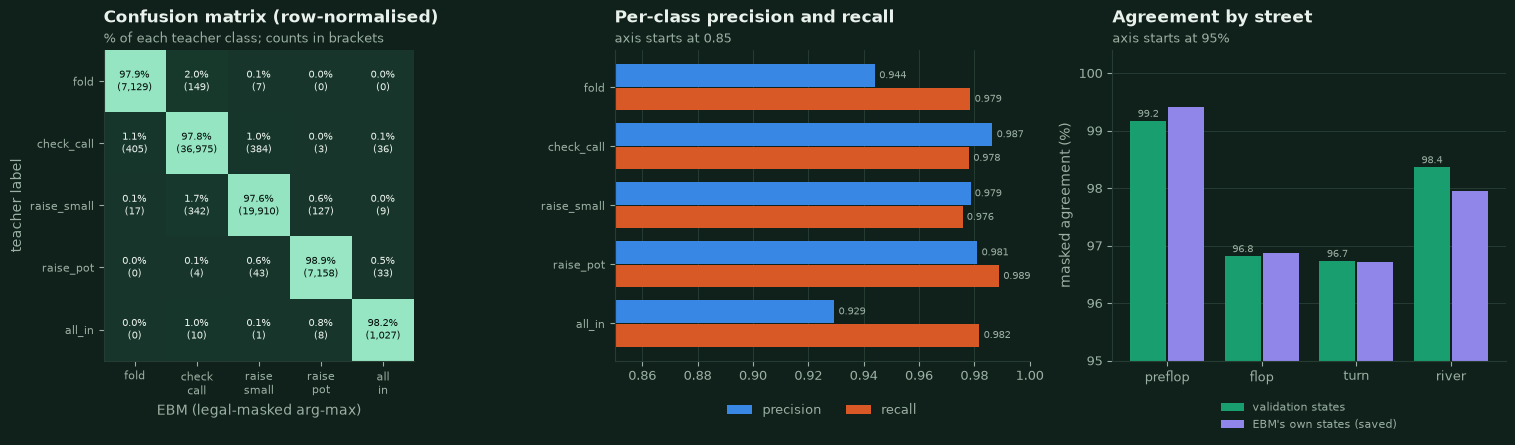

**Reading.** Per street the agreement is highest preflop (99.2%) and lowest on the turn (96.7%); the class with the lowest F1 is `all_in` (precision 0.929, recall 0.982, support 1,046). The three largest confusions (teacher -> EBM) are `check_call` -> `fold` (405 decisions, 1.1% of that class), `check_call` -> `raise_small` (384 decisions, 1.0% of that class), `raise_small` -> `check_call` (342 decisions, 1.7% of that class).

In [17]:
cm = np.array(metrics["confusion_matrix"], dtype=float)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
per_class = pd.DataFrame(metrics["per_class"]).T
fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.6), gridspec_kw={"width_ratios": [1.25, 0.95, 0.9]})
ax = axes[0]
mesh = ax.imshow(cm_norm, cmap=nbp.SEQUENTIAL, vmin=0, vmax=1)
ax.set_xticks(range(5), [a.replace("_", "\n") for a in ACTIONS], fontsize=8)
ax.set_yticks(range(5), ACTIONS, fontsize=8)
ax.set_xlabel("EBM (legal-masked arg-max)")
ax.set_ylabel("teacher label")
ax.grid(False)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{100 * cm_norm[i, j]:.1f}%\n({int(cm[i, j]):,})", ha="center", va="center", fontsize=7.5, color=nbp.TEXT if cm_norm[i, j] < 0.6 else "#06110c")
nbp.title(ax, "Confusion matrix (row-normalised)", "% of each teacher class; counts in brackets")
ax = axes[1]
y_pos = np.arange(5)
ax.barh(y_pos - 0.2, per_class["precision"].astype(float), height=0.38, color=nbp.SERIES[1], label="precision")
ax.barh(y_pos + 0.2, per_class["recall"].astype(float), height=0.38, color=nbp.SERIES[2], label="recall")
ax.set_yticks(y_pos, ACTIONS, fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0.85, 1.0)
for i, name in enumerate(ACTIONS):
    ax.annotate(f"{per_class.loc[name, 'precision']:.3f}", (per_class.loc[name, "precision"], i - 0.2), xytext=(3, 0), textcoords="offset points", va="center", fontsize=7.5, color=nbp.MUTED)
    ax.annotate(f"{per_class.loc[name, 'recall']:.3f}", (per_class.loc[name, "recall"], i + 0.2), xytext=(3, 0), textcoords="offset points", va="center", fontsize=7.5, color=nbp.MUTED)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=2)
nbp.title(ax, "Per-class precision and recall", "axis starts at 0.85")
ax = axes[2]
streets = ["preflop", "flop", "turn", "river"]
street_acc = metrics["masked_accuracy_by_street"]
onp_street = onp["masked_accuracy_by_street"]
x = np.arange(4)
ax.bar(x - 0.2, [100 * street_acc[s] for s in streets], width=0.38, color=nbp.ACCENT, label="validation states")
ax.bar(x + 0.2, [100 * onp_street[s] for s in streets], width=0.38, color=nbp.SERIES[3], label="EBM's own states (saved)")
for xi, s in zip(x, streets):
    ax.annotate(f"{100 * street_acc[s]:.1f}", (xi - 0.2, 100 * street_acc[s]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7.5, color=nbp.MUTED)
ax.set_xticks(x, streets)
ax.set_ylim(95, 100.4)
ax.set_ylabel("masked agreement (%)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=1, fontsize=8)
nbp.title(ax, "Agreement by street", "axis starts at 95%")
fig.tight_layout()
nbp.savefig("nb01_confusion_and_streets", fig)
plt.show()
worst_street = min(street_acc, key=street_acc.get)
best_street = max(street_acc, key=street_acc.get)
worst_class = per_class["f1"].astype(float).idxmin()
off = cm.copy()
np.fill_diagonal(off, 0)
top_conf = np.dstack(np.unravel_index(np.argsort(-off, axis=None)[:3], off.shape))[0]
display(Markdown(
    f"**Reading.** Per street the agreement is highest {best_street} ({pct(street_acc[best_street], 1)}) and lowest on the {worst_street} ({pct(street_acc[worst_street], 1)}); the class with the lowest F1 is `{worst_class}` "
    f"(precision {per_class.loc[worst_class, 'precision']:.3f}, recall {per_class.loc[worst_class, 'recall']:.3f}, support {int(per_class.loc[worst_class, 'support']):,}). "
    f"The three largest confusions (teacher -> EBM) are " + ", ".join(f"`{ACTIONS[i]}` -> `{ACTIONS[j]}` ({int(off[i, j]):,} decisions, {pct(off[i, j] / cm[i].sum(), 1)} of that class)" for i, j in top_conf) + "."
))

### 5.2 Calibration `[data]`

The labels are deterministic functions of the features, so a perfect model would give probability 1 to the teacher's action everywhere. Calibration therefore asks something narrower: when the model *is* unsure
(near a threshold), is the spread of its probabilities honest? Left: top-1 **confidence** (largest legal-masked probability) against how often that action equals the teacher's. Right: one-vs-rest reliability of the raw probability of each action.

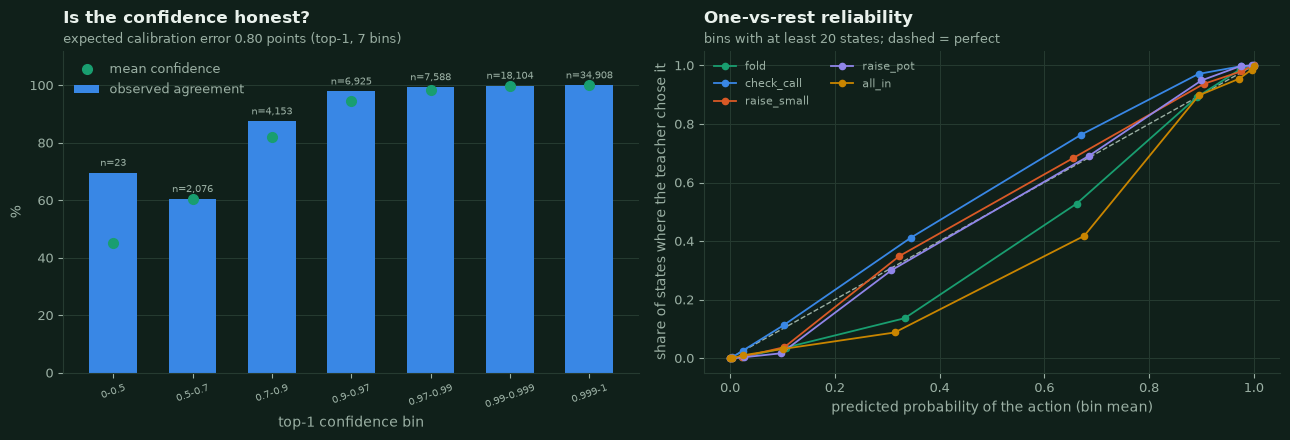

**[data]** 71.9% of the validation decisions get a top-1 confidence of at least 0.99, and on those the EBM agrees with the teacher 99.94% of the time; on the 8.5% of decisions with confidence below 0.9 it agrees 78.4%. Brier scores per action (lower is better): `fold` 0.0058, `check_call` 0.0134, `raise_small` 0.0095, `raise_pot` 0.0024, `all_in` 0.0011. In the uncertain band (predicted probability between 0.2 and 0.8) the model over-predicts `fold` (predicted 0.49, observed 0.32, 1,469 states), `all_in` (predicted 0.46, observed 0.22, 193 states) and under-predicts `check_call` (predicted 0.53, observed 0.61) - consistent with, though not proven to come from, the class weights that shift probability mass towards the rare actions (section 3.5). So the *ranking* of confidence is informative - low confidence flags the states near a teacher threshold - but the model is sharp: its probabilities are extreme almost everywhere, so they should not be read as the probabilities of a stochastic player.

In [18]:
masked_proba = np.where(VAL.legal, VAL_PROBA, 0.0)
masked_proba = masked_proba / masked_proba.sum(axis=1, keepdims=True)
confidence = masked_proba.max(axis=1)
correct = VAL_PRED == VAL.y
conf_edges = np.array([0.0, 0.5, 0.7, 0.9, 0.97, 0.99, 0.999, 1.0 + 1e-9])
conf_bin = np.digitize(confidence, conf_edges[1:-1])
rel = pd.DataFrame(
    {
        "bin": [f"{conf_edges[i]:.3g}-{min(conf_edges[i + 1], 1.0):.3g}" for i in range(len(conf_edges) - 1)],
        "n": [int((conf_bin == i).sum()) for i in range(len(conf_edges) - 1)],
        "mean confidence": [confidence[conf_bin == i].mean() if (conf_bin == i).any() else np.nan for i in range(len(conf_edges) - 1)],
        "accuracy": [correct[conf_bin == i].mean() if (conf_bin == i).any() else np.nan for i in range(len(conf_edges) - 1)],
    }
)
ece = float(np.nansum(rel["n"] * (rel["mean confidence"] - rel["accuracy"]).abs()) / rel["n"].sum())
class_edges = np.array([0.0, 0.001, 0.01, 0.05, 0.2, 0.5, 0.8, 0.95, 0.99, 0.999, 1.0 + 1e-9])
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.0, 4.5), gridspec_kw={"width_ratios": [1.0, 1.0]})
valid = rel.dropna()
xs = np.arange(len(valid))
ax.bar(xs, 100 * valid["accuracy"], color=nbp.SERIES[1], width=0.6, label="observed agreement")
ax.plot(xs, 100 * valid["mean confidence"], "o", color=nbp.ACCENT, markersize=7, label="mean confidence")
for xi, (_, r) in zip(xs, valid.iterrows()):
    ax.annotate(f"n={int(r['n']):,}", (xi, 100 * r["accuracy"]), xytext=(0, 5), textcoords="offset points", ha="center", fontsize=7.5, color=nbp.MUTED)
ax.set_xticks(xs, valid["bin"], fontsize=7.5, rotation=20)
ax.set_xlabel("top-1 confidence bin")
ax.set_ylabel("%")
ax.set_ylim(0, 112)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
nbp.title(ax, "Is the confidence honest?", f"expected calibration error {100 * ece:.2f} points (top-1, {len(valid)} bins)")
ax2.plot([0, 1], [0, 1], color=nbp.MUTED, linestyle="--", linewidth=1)
brier = {}
for k, name in enumerate(ACTIONS):
    p, truth = VAL_PROBA[:, k], (VAL.y == k).astype(float)
    brier[name] = float(np.mean((p - truth) ** 2))
    idx = np.digitize(p, class_edges[1:-1])
    pts = [(p[idx == i].mean(), truth[idx == i].mean(), (idx == i).sum()) for i in range(len(class_edges) - 1) if (idx == i).sum() >= 20]
    ax2.plot([a for a, _, _ in pts], [b for _, b, _ in pts], "-o", color=ACTION_COLORS[name], markersize=4.5, linewidth=1.3, label=name)
ax2.set_xlabel("predicted probability of the action (bin mean)")
ax2.set_ylabel("share of states where the teacher chose it")
ax2.legend(loc="upper left", fontsize=8, ncols=2)
nbp.title(ax2, "One-vs-rest reliability", "bins with at least 20 states; dashed = perfect")
fig.tight_layout()
nbp.savefig("nb01_calibration", fig)
plt.show()
mid_band = {name: (float(VAL_PROBA[(VAL_PROBA[:, k] > 0.2) & (VAL_PROBA[:, k] < 0.8), k].mean()), float((VAL.y[(VAL_PROBA[:, k] > 0.2) & (VAL_PROBA[:, k] < 0.8)] == k).mean()), int(((VAL_PROBA[:, k] > 0.2) & (VAL_PROBA[:, k] < 0.8)).sum())) for k, name in enumerate(ACTIONS)}
over = [n for n, (predicted, observed, count) in mid_band.items() if count >= 100 and predicted - observed > 0.05]
under_predicted = [n for n, (predicted, observed, count) in mid_band.items() if count >= 100 and observed - predicted > 0.05]
share_confident = float((confidence >= 0.99).mean())
acc_confident = float(correct[confidence >= 0.99].mean())
acc_unsure = float(correct[confidence < 0.9].mean()) if (confidence < 0.9).any() else float("nan")
display(Markdown(
    f"**[data]** {pct(share_confident, 1)} of the validation decisions get a top-1 confidence of at least 0.99, and on those the EBM agrees with the teacher {pct(acc_confident, 2)} of the time; on the {pct(float((confidence < 0.9).mean()), 1)} of decisions with "
    f"confidence below 0.9 it agrees {pct(acc_unsure, 1)}. Brier scores per action (lower is better): " + ", ".join(f"`{n}` {b:.4f}" for n, b in brier.items()) + ". "
    f"In the uncertain band (predicted probability between 0.2 and 0.8) the model over-predicts " + (", ".join(f"`{n}` (predicted {mid_band[n][0]:.2f}, observed {mid_band[n][1]:.2f}, {mid_band[n][2]:,} states)" for n in over) or "no action") + " and under-predicts "
    + (", ".join(f"`{n}` (predicted {mid_band[n][0]:.2f}, observed {mid_band[n][1]:.2f})" for n in under_predicted) or "no action")
    + " - consistent with, though not proven to come from, the class weights that shift probability mass towards the rare actions (section 3.5). "
    f"So the *ranking* of confidence is informative - low confidence flags the states near a teacher threshold - but the model is sharp: its probabilities are extreme almost everywhere, so they should not be read as the probabilities of a stochastic player."
))

### 5.3 Error analysis: where does it disagree with the teacher? `[data]`

The teacher stores for every label its `margin`: how far the deciding quantity (equity or hand percentile) was from the threshold that would have changed the decision. Errors should concentrate at *small* margins
(the EBM's step functions are slightly shifted against the teacher's exact thresholds) - if they do not, the model misses structure rather than blurring a boundary. We check that, then ask which rules and which action pairs are affected.

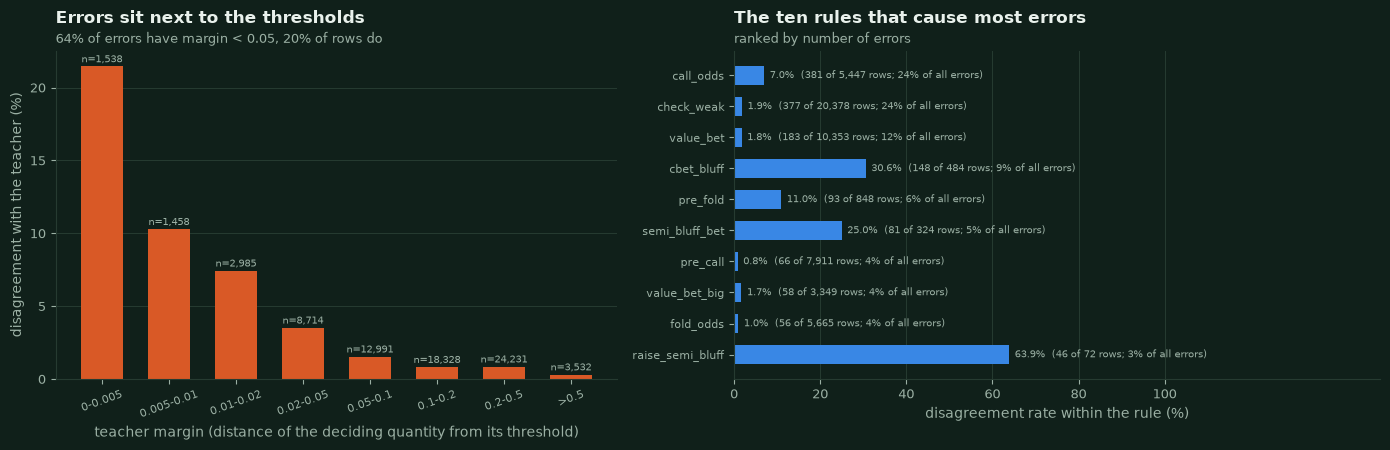

**[data]** 1,578 of 73,777 validation decisions (2.14%) disagree with the teacher. 64% of them have a teacher margin below 0.05 although only 20% of all rows do; the error rate in the lowest margin bin is 21.5% against 0.31% in the highest. The 10 rules above account for 94% of all errors; the highest disagreement *rate* among rules with at least 100 rows is `cbet_bluff` (30.6%). When the EBM is wrong it usually moves to a neighbouring action: 94% of the errors differ by one step of the fold < call < raise_small < raise_pot < all_in ladder, and in 99% of them the teacher's action is the EBM's *second* choice among the legal actions.

In [19]:
err = VAL_PRED != VAL.y
margin_edges = np.array([0.0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, np.inf])
margin_bin = np.digitize(MARGIN, margin_edges[1:-1])
margin_rows = pd.DataFrame(
    {
        "margin": [f"{margin_edges[i]:g}-{margin_edges[i + 1]:g}" if np.isfinite(margin_edges[i + 1]) else f">{margin_edges[i]:g}" for i in range(len(margin_edges) - 1)],
        "n": [(margin_bin == i).sum() for i in range(len(margin_edges) - 1)],
        "error rate": [err[margin_bin == i].mean() if (margin_bin == i).any() else np.nan for i in range(len(margin_edges) - 1)],
    }
)
rule_err = pd.DataFrame({"rule": RULES, "err": err}).groupby("rule")["err"].agg(["size", "sum", "mean"]).sort_values("sum", ascending=False)
rule_err["share of all errors"] = rule_err["sum"] / err.sum()
expected_conf = pd.crosstab(pd.Series(VAL.y, name="teacher"), pd.Series(VAL_PRED, name="ebm"))
near_boundary_share = float(err[MARGIN < 0.05].sum() / err.sum())
near_boundary_rows = float((MARGIN < 0.05).mean())
step = np.abs(VAL_PRED - VAL.y)
teacher_rank = np.argsort(np.argsort(-np.where(VAL.legal, VAL_PROBA, -1.0), axis=1), axis=1)[np.arange(len(VAL.y)), VAL.y]  # 0 = teacher action is the model's top legal choice
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14.0, 4.6), gridspec_kw={"width_ratios": [1.0, 1.15]})
ax.bar(range(len(margin_rows)), 100 * margin_rows["error rate"], color=nbp.SERIES[2], width=0.62)
for i, r in margin_rows.iterrows():
    ax.annotate(f"n={int(r['n']):,}", (i, 100 * r["error rate"]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7.5, color=nbp.MUTED)
ax.set_xticks(range(len(margin_rows)), margin_rows["margin"], rotation=20, fontsize=8)
ax.set_xlabel("teacher margin (distance of the deciding quantity from its threshold)")
ax.set_ylabel("disagreement with the teacher (%)")
ax.grid(axis="x", visible=False)
nbp.title(ax, "Errors sit next to the thresholds", f"{pct(near_boundary_share, 0)} of errors have margin < 0.05, {pct(near_boundary_rows, 0)} of rows do")
top_rules_err = rule_err.head(10)
ax2.barh(range(len(top_rules_err)), 100 * top_rules_err["mean"], color=nbp.SERIES[1], height=0.62)
for i, (name, r) in enumerate(top_rules_err.iterrows()):
    ax2.annotate(f"{100 * r['mean']:.1f}%  ({int(r['sum']):,} of {int(r['size']):,} rows; {100 * r['share of all errors']:.0f}% of all errors)", (100 * r["mean"], i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=7.5, color=nbp.MUTED)
ax2.set_yticks(range(len(top_rules_err)), top_rules_err.index, fontsize=8)
ax2.invert_yaxis()
ax2.set_xlim(0, 150)
ax2.set_xticks(range(0, 101, 20))
ax2.grid(axis="y", visible=False)
ax2.set_xlabel("disagreement rate within the rule (%)")
nbp.title(ax2, "The ten rules that cause most errors", "ranked by number of errors")
fig.tight_layout()
nbp.savefig("nb01_error_analysis", fig)
plt.show()
display(Markdown(
    f"**[data]** {int(err.sum()):,} of {len(err):,} validation decisions ({pct(err.mean(), 2)}) disagree with the teacher. {pct(near_boundary_share, 0)} of them have a teacher margin below 0.05 although only {pct(near_boundary_rows, 0)} of all rows do; "
    f"the error rate in the lowest margin bin is {pct(margin_rows['error rate'].iloc[0], 1)} against {pct(margin_rows['error rate'].dropna().iloc[-1], 2)} in the highest. "
    f"The {len(top_rules_err)} rules above account for {pct(top_rules_err['share of all errors'].sum(), 0)} of all errors; the highest disagreement *rate* among rules with at least 100 rows is "
    f"`{rule_err[rule_err['size'] >= 100]['mean'].idxmax()}` ({pct(rule_err[rule_err['size'] >= 100]['mean'].max(), 1)}). "
    f"When the EBM is wrong it usually moves to a neighbouring action: {pct(float((step[err] == 1).mean()), 0)} of the errors differ by one step of the fold < call < raise_small < raise_pot < all_in ladder, "
    f"and in {pct(float((teacher_rank[err] == 1).mean()), 0)} of them the teacher's action is the EBM's *second* choice among the legal actions."
))

### 5.4 Policy evaluation: how well does it *play*? `[saved]` `[fresh]`

Imitation is not skill, so the EBM is now put at a table. Every number is **BB/100** (big blinds won per 100 hands) of the EBM, with 95% Student-t intervals over **duplicate pairs**:
a pair plays one deal twice with the seats swapped, which cancels the luck of the cards (hands inside a pair are strongly dependent, so hands are never treated as independent).
"wins" / "loses" mean *the interval excludes zero*; "no significant difference" is absence of evidence, not equality. Adaptive agents (EBM and teacher both read opponent statistics) make consecutive pairs of a match slightly dependent,
so the more conservative interval over 50-pair matches is shown next to each result.

**The duplicate protocol (two tables).** A duplicate evaluation must make sure that nothing about a deal can leak from one play of it to the other. The legacy *single-table* protocol played both hands of a deal back-to-back with the same agents and the same opponent trackers,
so the second play of every deal faced an opponent model that already contained the first play of *the same deal*: two identical adaptive agents did not cancel (the first-named side lost roughly 10-13 BB/100 in an A/A test). Every fresh number below therefore uses the corrected
**two-table** protocol (`protocol="two_table"`, the default of `poker_arena.data.evaluation.pair_results`): each session is two independent tables with their own agent copies and opponent trackers, the same deals, seats complemented - identical adaptive agents now cancel.
The diagnostic (an A/A test of two identical teachers) is in Notebook 4, section 6. The BB/100 stored in `metadata.json` at training time (`policy_validation`, `dagger[*]`) predate the change: they are shown only as *legacy single-table protocol (informational, see `evaluation_protocol_note`)*.

**What is held out here.**

1. **Deals.** Everything below uses the `eval` seed namespace with `EVAL_SEED`; the model was trained on `dataset_train` / `dagger` deals, and the DAgger round was *selected* on `dataset_val` deals. No deal is shared (verified below).
2. **Opponent styles.** The teacher, the three bots and (teacher-style) tight / loose / aggressive / passive players were in the training mixture (as opponents and behaviour policies) - strength against them is strength against *familiar* styles. The teacher is additionally the label source, never a held-out judge.
   The evolved genetic-algorithm agent (`ga_evolved`) and the hand-made `balanced` and `bluffer` genomes never appeared in the data: they are the genuinely unseen opponents.
3. **The saved validation results** (`policy_validation` in `metadata.json`) used `dataset_val` deals, were used to *pick* the DAgger round (winner's curse) and come from the legacy single-table protocol, so they are a reference, not an independent test.

To see whether imitation costs strength, the **teacher itself plays the same duplicate deals** against the same opponents; the paired difference "EBM minus teacher" per opponent is the cleanest answer.

In [20]:
GA_DIR = MODELS_DIR / "ga"
ga_meta = json.loads((GA_DIR / "metadata.json").read_text(encoding="utf-8"))
GENOME_DIR = ARTIFACTS_DIR / "tmp" / "nb01_genomes"


def genome_spec(label: str, genome) -> AgentSpec:
    """A hand-made GA genome as a registry spec (written in the two-file artifact format of artifacts/models/ga)."""
    folder = GENOME_DIR / label
    folder.mkdir(parents=True, exist_ok=True)
    (folder / "best_genome.json").write_text(json.dumps({"schema_version": ga_meta["schema_version"], "genes": genome.to_dict()}))
    (folder / "metadata.json").write_text(json.dumps({"schema_version": ga_meta["schema_version"], "gene_names": list(genome.to_dict()), "equity_samples": ga_meta["equity_samples"]}))
    return AgentSpec("ga", {"model_dir": str(folder)}, label=label)


EBM_SPEC = AgentSpec("ebm", {}, label="EBM")
SPECS = {
    "teacher": AgentSpec("teacher", {}, label="teacher"),
    "random": AgentSpec("random"), "call_station": AgentSpec("call_station"), "maniac": AgentSpec("maniac"),
    "ga_evolved": AgentSpec("ga", {}, label="ga_evolved"),
    "balanced": genome_spec("balanced", GA_PRESETS["balanced"]), "bluffer": genome_spec("bluffer", GA_PRESETS["bluffer"]),
}  # fmt: skip
SOLID = ("teacher", "ga_evolved", "balanced", "bluffer")
BOTS = ("call_station", "maniac", "random")
EVAL_OPPONENTS = (*SOLID, *BOTS)
HELD_OUT = ("ga_evolved", "balanced", "bluffer")
pairs_for = lambda opponent: EVAL_PAIRS_HELDOUT if opponent in HELD_OUT else EVAL_PAIRS  # noqa: E731


def run_pairs(jobs: dict) -> dict:
    """Duplicate-pair evaluations of many matchups on ONE process pool: ``{key: (hero, opponent, pairs, seed_parts)}``
    -> ``{key: BB per pair of the hero}`` (``poker_arena.data.evaluation.pair_results``; deterministic, any worker count)."""
    order = sorted(jobs, key=lambda k: -jobs[k][2])
    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=multiprocessing.get_context("spawn")) as pool:
        futures = {k: pool.submit(pair_results, jobs[k][0], jobs[k][1], jobs[k][2], jobs[k][3], GAME, 1, "eval", EVAL_PROTOCOL) for k in order}
        return {k: futures[k].result() for k in jobs}


jobs = {}
for hero_name, hero in (("EBM", EBM_SPEC), ("teacher", SPECS["teacher"])):
    for opponent in EVAL_OPPONENTS:
        if hero_name == opponent:
            continue
        jobs[hero_name, opponent] = (hero, SPECS[opponent], pairs_for(opponent), (EVAL_SEED, opponent))  # same seed parts for both heroes: identical deals
started = time.perf_counter()
raw_pairs = run_pairs(jobs)
fresh_seconds = time.perf_counter() - started
fresh = {key: summarize(*key, pairs) for key, pairs in raw_pairs.items()}
total_hands = sum(r.n_hands for r in fresh.values())

# deals used here vs every deal of the training / validation / DAgger namespaces that could coincide (regenerated, not assumed)
def deal_set(namespace: str, *parts, n: int) -> set:
    return {Deal.from_seed(derive_seed(namespace, *parts, "deal", i)).cards for i in range(n)}


eval_deals = set().union(*(deal_set("eval", EVAL_SEED, o, n=pairs_for(o)) for o in EVAL_OPPONENTS))
val_policy_deals = set().union(*(deal_set("dataset_val", "ebm_policy_validation", cfg_run["RANDOM_SEED"], o, n=cfg_run["VALIDATION_PAIRS"]) for o in opponents))
train_hands = {Deal.from_rng(Random(int(h))).cards for h in FULL["hand_id"].unique()}  # every train AND validation hand of the dataset
dagger_hands = {Deal.from_rng(Random(derive_seed("dagger", cfg_run["RANDOM_SEED"], k + 1, "train", "hand", i))).cards for k in range(dag["rounds"]) for i in range(dag["hands_per_round"])}
shared = {"validation games": len(eval_deals & val_policy_deals), "dataset hands": len(eval_deals & train_hands), "DAgger hands": len(eval_deals & dagger_hands)}
display(Markdown(
    f"**[fresh]** {total_hands:,} hands in {fresh_seconds:.0f} s on {N_WORKERS} worker processes. Deals shared between this evaluation's {len(eval_deals):,} deals and (regenerated, not assumed) "
    f"the {len(val_policy_deals):,} deals of the model's validation games: **{shared['validation games']}**; all {FULL['hand_id'].nunique():,} hands of the dataset (train + validation): **{shared['dataset hands']}**; "
    f"the {len(dagger_hands):,} DAgger hands: **{shared['DAgger hands']}**."
))

**[fresh]** 21,200 hands in 29 s on 4 worker processes. Deals shared between this evaluation's 5,800 deals and (regenerated, not assumed) the 2,000 deals of the model's validation games: **0**; all 133,260 hands of the dataset (train + validation): **0**; the 30,000 DAgger hands: **0**.

**[fresh] [saved]** BB/100 [95% CI over duplicate pairs] of the EBM against each opponent on fresh deals, the same for the teacher on identical deals, their paired difference, and the saved validation result (different deals, **legacy single-table protocol - informational, see `evaluation_protocol_note`**):

| opponent | seen in training? | pairs | EBM BB/100 [95% CI] | result | match-level CI | teacher plays the same deals | EBM minus teacher | saved validation (legacy protocol) |
|---|---|---|---|---|---|---|---|---|
| `teacher` | yes (label source) | 1000 | +17 [-17, +51] | no significant difference | [-20, +55] | - | - | +61 [+7, +114] |
| `ga_evolved` | no (held out) | 600 | +106 [+40, +173] | wins | [+17, +196] | +132 [+64, +199] | -25 [-76, +26] (no significant difference) | - |
| `balanced` | no (held out) | 600 | +144 [+63, +225] | wins | [+56, +233] | +82 [+6, +157] | +63 [-2, +127] (no significant difference) | - |
| `bluffer` | no (held out) | 600 | +182 [+89, +276] | wins | [+82, +283] | +192 [+100, +284] | -10 [-73, +54] (no significant difference) | - |
| `call_station` | yes (opponent mix) | 1000 | +776 [+700, +853] | wins | [+714, +839] | +756 [+682, +831] | +20 [+6, +33] (wins) | +653 [+552, +755] |
| `maniac` | yes (opponent mix) | 1000 | +1263 [+1082, +1445] | wins | [+1101, +1426] | +1297 [+1115, +1479] | -33 [-124, +57] (no significant difference) | +1652 [+1396, +1908] |
| `random` | yes (opponent mix) | 1000 | +449 [+312, +587] | wins | [+306, +593] | +512 [+362, +663] | -63 [-186, +60] (no significant difference) | +723 [+516, +930] |

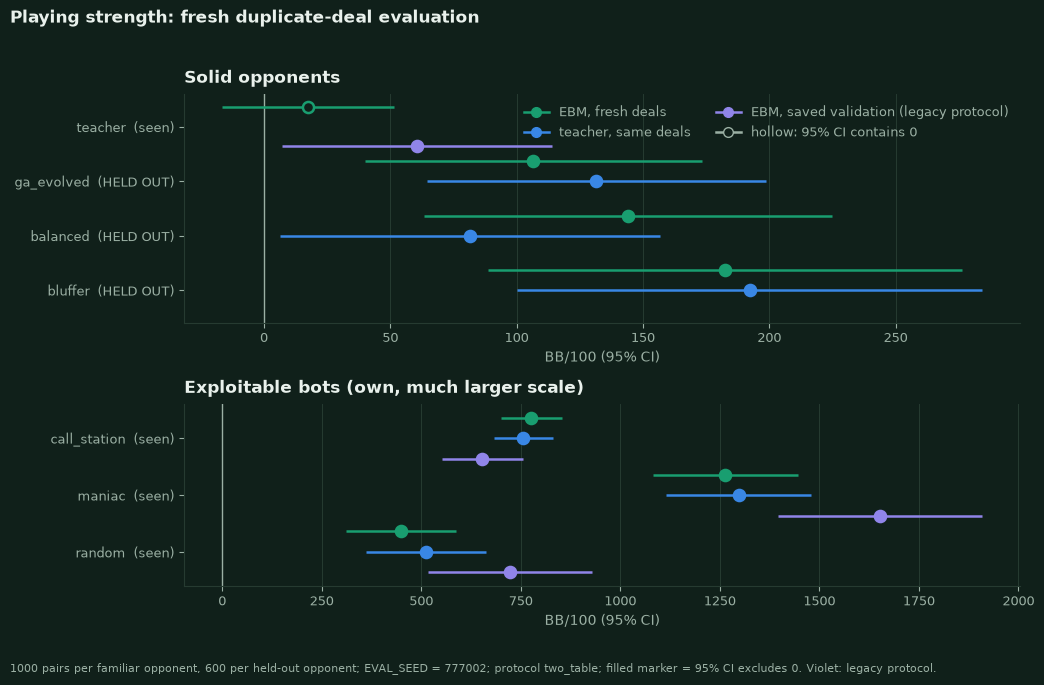

**Replication against the official tournament `[saved]`.** The tournament run `20261011-204425_official` (protocol `two_table`, session-level 95% intervals) measured the same matchups on other deals and seeds with far more pairs. z = difference / sqrt(SE_fresh^2 + SE_official^2); 4 of 5 opponents agree within |z| < 2 (about 1 in 20 is expected to exceed 2 by chance):

| opponent | this notebook (fresh) | official tournament, 20,000 pairs | z of the difference |
|---|---|---|---|
| `teacher` | +17 [-17, +51] | +37 [+27, +47] | -1.1 |
| `random` | +449 [+312, +587] | +599 [+567, +631] | -2.1 |
| `call_station` | +776 [+700, +853] | +722 [+706, +739] | +1.4 |
| `maniac` | +1263 [+1082, +1445] | +1335 [+1292, +1377] | -0.7 |
| `ga_evolved` | +106 [+40, +173] | +74 [+62, +86] | +0.9 |

The saved validation numbers of `metadata.json` come from the legacy single-table protocol and from other deals, and the kept DAgger round was picked on them; they are listed in the table above for completeness and are **not** compared quantitatively with the two-table numbers.

In [21]:
rows = []
for opponent in EVAL_OPPONENTS:
    r = fresh["EBM", opponent]
    t = fresh.get(("teacher", opponent))
    diff_summary = summarize("EBM minus teacher", opponent, raw_pairs["EBM", opponent] - raw_pairs["teacher", opponent]) if t is not None else None
    saved_r = meta["policy_validation"]["results"].get(opponent)
    rows.append(
        {
            "opponent": f"`{opponent}`",
            "seen in training?": "no (held out)" if opponent in HELD_OUT else ("yes (label source)" if opponent == "teacher" else "yes (opponent mix)"),
            "pairs": r.n_pairs,
            "EBM BB/100 [95% CI]": ci_text(r.bb_per_100, r.ci_low, r.ci_high),
            "result": verdict(r.ci_low, r.ci_high),
            "match-level CI": "-" if np.isnan(r.match_ci_low) else f"[{r.match_ci_low:+.0f}, {r.match_ci_high:+.0f}]",
            "teacher plays the same deals": "-" if t is None else ci_text(t.bb_per_100, t.ci_low, t.ci_high),
            "EBM minus teacher": "-" if diff_summary is None else f"{ci_text(diff_summary.bb_per_100, diff_summary.ci_low, diff_summary.ci_high)} ({verdict(diff_summary.ci_low, diff_summary.ci_high)})",
            "saved validation (legacy protocol)": "-" if saved_r is None else ci_text(saved_r["bb_per_100"], *saved_r["ci95_pairs"]),
        }
    )
display(Markdown("**[fresh] [saved]** BB/100 [95% CI over duplicate pairs] of the EBM against each opponent on fresh deals, the same for the teacher on identical deals, their paired difference, and the saved validation result (different deals, **legacy single-table protocol - informational, see `evaluation_protocol_note`**):"))
display(md_table(pd.DataFrame(rows)))

fig, axes = plt.subplots(2, 1, figsize=(10.5, 6.6), gridspec_kw={"height_ratios": [len(SOLID) + 0.9, len(BOTS) + 0.9]})
for ax, (title, members) in zip(axes, (("Solid opponents", SOLID), ("Exploitable bots (own, much larger scale)", BOTS))):
    labels = [f"{o}  ({'HELD OUT' if o in HELD_OUT else 'seen'})" for o in members]
    series = {"EBM, fresh deals": tuple(zip(*[(fresh["EBM", o].bb_per_100, fresh["EBM", o].ci_low, fresh["EBM", o].ci_high) for o in members]))}
    series["teacher, same deals"] = tuple(zip(*[(fresh["teacher", o].bb_per_100, fresh["teacher", o].ci_low, fresh["teacher", o].ci_high) if ("teacher", o) in fresh else (np.nan,) * 3 for o in members]))
    series["EBM, saved validation (legacy protocol)"] = tuple(zip(*[(meta["policy_validation"]["results"][o]["bb_per_100"], *meta["policy_validation"]["results"][o]["ci95_pairs"]) if o in meta["policy_validation"]["results"] else (np.nan,) * 3 for o in members]))
    nbp.forest_plot(ax, labels, series, colors={"EBM, fresh deals": nbp.ACCENT, "teacher, same deals": nbp.SERIES[1], "EBM, saved validation (legacy protocol)": nbp.SERIES[3]}, x_label="BB/100 (95% CI)", legend=ax is axes[0])
    nbp.title(ax, title)
fig.suptitle("Playing strength: fresh duplicate-deal evaluation", x=0.01, ha="left", fontsize=12, fontweight="bold", color=nbp.TEXT)
nbp.footnote(fig, f"{EVAL_PAIRS} pairs per familiar opponent, {EVAL_PAIRS_HELDOUT} per held-out opponent; EVAL_SEED = {EVAL_SEED}; protocol {EVAL_PROTOCOL}; filled marker = 95% CI excludes 0. Violet: legacy protocol.")
fig.tight_layout(rect=(0, 0.02, 1, 0.96))
nbp.savefig("nb01_policy_evaluation", fig)
plt.show()

# replication: the same quantity (EBM vs X) from the OFFICIAL tournament (same two-table protocol, 20,000 pairs per matchup, other deals and seeds)
OFFICIAL = load_results()
official = OFFICIAL.pairwise_table()
OFFICIAL_NAME = {"teacher": "Teacher", "random": "Random", "call_station": "CallStation", "maniac": "Maniac", "ga_evolved": "GA"}  # the tournament's GA is the same evolved artifact
off_rows, off_z = [], {}
for opponent, name in OFFICIAL_NAME.items():
    row = official[(official["agent"] == "EBM") & (official["opponent"] == name)].iloc[0]
    new = fresh["EBM", opponent]
    off_z[opponent] = float((new.bb_per_100 - row["bb_per_100"]) / np.hypot(new.std_error, row["se"]))
    off_rows.append({"opponent": f"`{opponent}`", "this notebook (fresh)": ci_text(new.bb_per_100, new.ci_low, new.ci_high), f"official tournament, {int(row['units']):,} {row['unit']}s": ci_text(row["bb_per_100"], row["ci_low"], row["ci_high"]), "z of the difference": f"{off_z[opponent]:+.1f}"})
diffs_vs_teacher = {o: summarize("EBM minus teacher", o, raw_pairs["EBM", o] - raw_pairs["teacher", o]) for o in EVAL_OPPONENTS if ("teacher", o) in fresh}
display(Markdown(
    f"**Replication against the official tournament `[saved]`.** The tournament run `{OFFICIAL.run_id}` (protocol `{OFFICIAL.protocol}`, session-level 95% intervals) measured the same matchups on other deals and seeds with far more pairs. "
    f"z = difference / sqrt(SE_fresh^2 + SE_official^2); {sum(abs(z) < 2 for z in off_z.values())} of {len(off_z)} opponents agree within |z| < 2 (about 1 in 20 is expected to exceed 2 by chance):"
))
display(md_table(pd.DataFrame(off_rows)))
display(Markdown(
    "The saved validation numbers of `metadata.json` come from the legacy single-table protocol and from other deals, and the kept DAgger round was picked on them; they are listed in the table above for completeness and are **not** compared quantitatively with the two-table numbers."
))

**Reading the policy results.** (Written after inspecting the table above; the numbers in the sentences are generated.)

In [22]:
ebm_vs = {o: fresh["EBM", o] for o in EVAL_OPPONENTS}
bots_won = [o for o in BOTS if ebm_vs[o].ci_low > 0]
held_words = {o: verdict(ebm_vs[o].ci_low, ebm_vs[o].ci_high) for o in HELD_OUT}
teacher_row = ebm_vs["teacher"]
off_teacher = official[(official["agent"] == "EBM") & (official["opponent"] == "Teacher")].iloc[0]
official_word = "ahead of the teacher" if off_teacher["ci_low"] > 0 else ("behind the teacher" if off_teacher["ci_high"] < 0 else "not distinguishable from the teacher")
official_text = f"{ci_text(off_teacher['bb_per_100'], off_teacher['ci_low'], off_teacher['ci_high'])} BB/100 from {int(off_teacher['units']):,} {off_teacher['unit']}s ({official_word})"
compatible = "compatible with" if abs(off_z["teacher"]) < 2 else "different from"
teacher_word = {"wins": "**beats** the teacher", "loses": "**loses** to the teacher", "no significant difference": "is **not distinguishable** from the teacher"}[verdict(teacher_row.ci_low, teacher_row.ci_high)]
equal_or_better = [o for o, d in diffs_vs_teacher.items() if d.ci_low <= 0 <= d.ci_high]
better = [o for o, d in diffs_vs_teacher.items() if d.ci_low > 0]
worse = [o for o, d in diffs_vs_teacher.items() if d.ci_high < 0]
display(Markdown(
    f"* Against the three exploitable bots the EBM wins clearly in {len(bots_won)} of 3 matchups (`{'`, `'.join(bots_won)}`; "
    + ", ".join(f"`{o}` {ci_text(ebm_vs[o].bb_per_100, ebm_vs[o].ci_low, ebm_vs[o].ci_high)}" for o in BOTS)
    + ") - BB/100 against such bots mostly measures how strongly a weakness is punished, not the quality of the strategy.\n"
    f"* Against the teacher it {teacher_word} on {teacher_row.n_pairs} fresh duplicate pairs: {ci_text(teacher_row.bb_per_100, teacher_row.ci_low, teacher_row.ci_high)} BB/100 (conservative match-level interval [{teacher_row.match_ci_low:+.0f}, {teacher_row.match_ci_high:+.0f}]); "
    f"the official tournament (same two-table protocol, far more pairs, run `{OFFICIAL.run_id}`) puts EBM vs Teacher at {official_text}, so the fresh estimate is {compatible} it (z = {off_z['teacher']:+.1f}). "
    f"The saved validation estimate (legacy single-table protocol, informational) was {ci_text(meta['policy_validation']['results']['teacher']['bb_per_100'], *meta['policy_validation']['results']['teacher']['ci95_pairs'])}.\n"
    f"* Against the three opponents it never met in training: " + ", ".join(f"`{o}` {ci_text(ebm_vs[o].bb_per_100, ebm_vs[o].ci_low, ebm_vs[o].ci_high)} ({held_words[o]})" for o in HELD_OUT) + ".\n"
    f"* **Imitation vs skill, paired on identical deals** (EBM minus teacher): significantly better than the teacher against {len(better)} opponent(s)" + (f" ({', '.join(better)})" if better else "")
    + f", not distinguishable against {len(equal_or_better)} ({', '.join(equal_or_better) or '-'})" + f", significantly worse against {len(worse)}" + (f" ({', '.join(worse)})" if worse else "") + ". "
    + f" Point estimates of the difference: {sum(d.bb_per_100 > 0 for d in diffs_vs_teacher.values())} positive, {sum(d.bb_per_100 < 0 for d in diffs_vs_teacher.values())} negative. "
    f"A {pct(metrics['masked_accuracy'], 1)} copy therefore {'loses nothing *measurable* here' if not worse else 'loses measurably against ' + ', '.join(worse)} - but the paired intervals against the solid opponents are about +-{np.median([(d.ci_high - d.ci_low) / 2 for o, d in diffs_vs_teacher.items() if o in SOLID]):.0f} BB/100 wide, so a loss of that size cannot be excluded in this sample; "
    f"the official tournament, which resolves a few BB/100, finds the EBM {official_word}."
))

* Against the three exploitable bots the EBM wins clearly in 3 of 3 matchups (`call_station`, `maniac`, `random`; `call_station` +776 [+700, +853], `maniac` +1263 [+1082, +1445], `random` +449 [+312, +587]) - BB/100 against such bots mostly measures how strongly a weakness is punished, not the quality of the strategy.
* Against the teacher it is **not distinguishable** from the teacher on 1000 fresh duplicate pairs: +17 [-17, +51] BB/100 (conservative match-level interval [-20, +55]); the official tournament (same two-table protocol, far more pairs, run `20261011-204425_official`) puts EBM vs Teacher at +37 [+27, +47] BB/100 from 20,000 pairs (ahead of the teacher), so the fresh estimate is compatible with it (z = -1.1). The saved validation estimate (legacy single-table protocol, informational) was +61 [+7, +114].
* Against the three opponents it never met in training: `ga_evolved` +106 [+40, +173] (wins), `balanced` +144 [+63, +225] (wins), `bluffer` +182 [+89, +276] (wins).
* **Imitation vs skill, paired on identical deals** (EBM minus teacher): significantly better than the teacher against 1 opponent(s) (call_station), not distinguishable against 5 (ga_evolved, balanced, bluffer, maniac, random), significantly worse against 0.  Point estimates of the difference: 2 positive, 4 negative. A 97.9% copy therefore loses nothing *measurable* here - but the paired intervals against the solid opponents are about +-64 BB/100 wide, so a loss of that size cannot be excluded in this sample; the official tournament, which resolves a few BB/100, finds the EBM ahead of the teacher.

## 6. Global feature effects and interactions

### 6.1 The additive identity, and InterpretML's own global view `[data]`

Before reading any curve, check the property that makes an EBM a *glass box*: the five logits are exactly `intercept + sum of the term scores`, and the softmax of the logits is the model's probability.
`MODEL.eval_terms(X)` returns the score of every term for every row and action; summing them reproduces `predict_proba`.

In [23]:
fid_rng = np.random.default_rng(DEMO_SEED)
FID_IDX = fid_rng.choice(len(VAL.y), size=min(FIDELITY_ROWS, len(VAL.y)), replace=False)  # validation rows of the explanation studies (seeded)
XF, LF, YF, RF = VAL.X[FID_IDX], VAL.legal[FID_IDX], VAL.y[FID_IDX], RULES[FID_IDX]
TERMS = MODEL.eval_terms(XF)  # (rows, terms, actions): score of every term for every action
INTERCEPT = np.asarray(MODEL.intercept_, dtype=float)
LOGITS = INTERCEPT[None, :] + TERMS.sum(axis=1)
softmax = lambda z: np.exp(z - z.max(axis=1, keepdims=True)) / np.exp(z - z.max(axis=1, keepdims=True)).sum(axis=1, keepdims=True)  # noqa: E731
identity_error = float(np.abs(softmax(LOGITS) - MODEL.predict_proba(XF)).max())
TERM_FEATURES = [tuple(FEATURE_NAMES[i] for i in f) for f in MODEL.term_features_]
TERM_NAMES = [" x ".join(f) for f in TERM_FEATURES]
n_main_terms = sum(len(f) == 1 for f in TERM_FEATURES)
display(Markdown(
    f"**[data]** On {len(XF):,} validation states: `max |softmax(intercept + sum of terms) - predict_proba| = {identity_error:.1e}` - the decomposition is exact, not an approximation. "
    f"The model has {len(TERM_NAMES)} terms ({n_main_terms} one-feature, {len(TERM_NAMES) - n_main_terms} two-feature); the intercepts of the five actions are "
    + ", ".join(f"`{a}` {b:+.1f}" for a, b in zip(ACTIONS, INTERCEPT))
    + ". (They are large and negative because every term is *centred* on the training distribution: the intercept is the logit of the average state, and states in which a rare action is chosen collect tens of log-odds units from their terms.)"
))
if SHOW_INTERPRET_WIDGETS:
    display(Markdown("**InterpretML's interactive global explanation** (`show(MODEL.explain_global())`; pick a feature in the dropdown; works in a live Jupyter kernel only - GitHub shows nothing here, the static figures below show the same curves). "
                     "For a multi-class model InterpretML drops the pairwise terms from this view - section 6.4 draws them with `poker_arena.explain.ebm`."))
    show(MODEL.explain_global(name="EBM poker agent"))

**[data]** On 20,000 validation states: `max |softmax(intercept + sum of terms) - predict_proba| = 9.0e-15` - the decomposition is exact, not an approximation. The model has 85 terms (45 one-feature, 40 two-feature); the intercepts of the five actions are `fold` -30.0, `check_call` +0.0, `raise_small` -4.1, `raise_pot` -37.8, `all_in` -25.4. (They are large and negative because every term is *centred* on the training distribution: the intercept is the logit of the average state, and states in which a rare action is chosen collect tens of log-odds units from their terms.)

**InterpretML's interactive global explanation** (`show(MODEL.explain_global())`; pick a feature in the dropdown; works in a live Jupyter kernel only - GitHub shows nothing here, the static figures below show the same curves). For a multi-class model InterpretML drops the pairwise terms from this view - section 6.4 draws them with `poker_arena.explain.ebm`.

<!-- http://127.0.0.1:7001/2446799853888/ -->

### 6.2 Which terms matter? Importance by term, group and action `[saved]` `[data]`

The importance of a term is the mean absolute value of its score over the validation states (averaged over the five actions) - "how far does this term typically move the logits where the game actually goes".
The saved ranking (in `metadata.json`) was computed on 20,000 random validation states; we recompute it from the model to verify it, then group the terms.

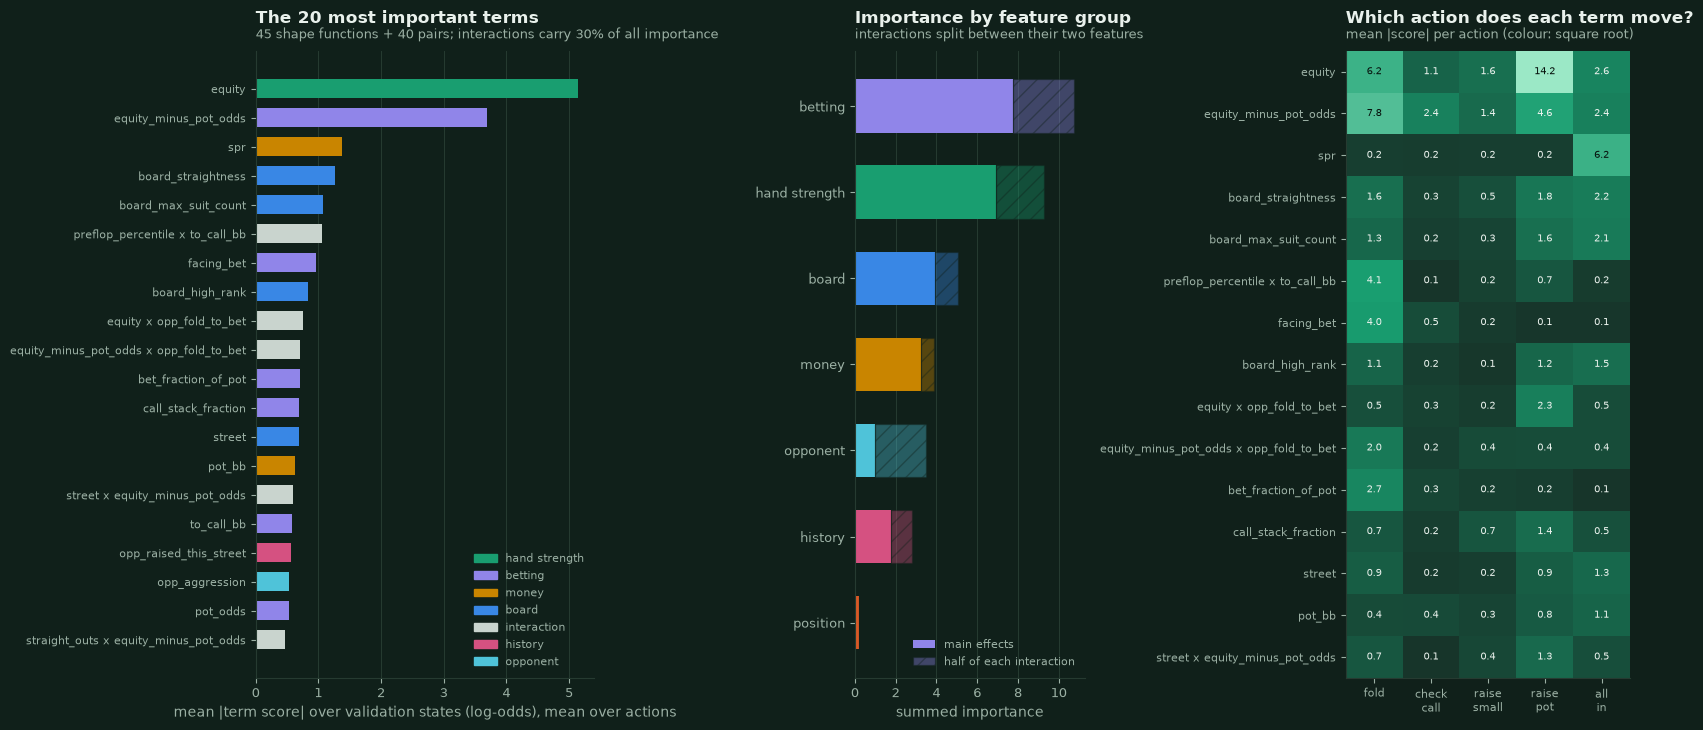

**[data]** Recomputing the ranking on the same 20,000 states reproduces the saved importances to within 0.0e+00. The five most important terms are `equity` (5.14), `equity_minus_pot_odds` (3.70), `spr` (1.38), `board_straightness` (1.27), `board_max_suit_count` (1.08). Interactions (the 40 pair terms) carry 30% of the total importance; 13 of them involve `equity` or `equity_minus_pot_odds` and 27 involve an opponent statistic. By feature group (interactions attributed half-half) the ranking is betting (10.7) > hand strength (9.3) > board (5.0) > money (3.9) > opponent (3.5) > history (2.8) > position (0.2). Per action the picture is sharply different: **fold** is driven by `equity_minus_pot_odds` (7.8, next `equity` 6.2); **check_call** is driven by `equity_minus_pot_odds` (2.4, next `equity` 1.1); **raise_small** is driven by `equity` (1.6, next `opp_raised_this_street` 1.5); **raise_pot** is driven by `equity` (14.2, next `equity_minus_pot_odds` 4.6); **all_in** is driven by `spr` (6.2, next `equity` 2.6).

In [24]:
IMPORTANCE_TAG = 2_001  # same constant as poker_arena.training.ebm
imp_rows = np.random.default_rng([cfg_run["RANDOM_SEED"], IMPORTANCE_TAG]).choice(len(VAL.y), size=min(cfg_run["IMPORTANCE_SAMPLE_ROWS"], len(VAL.y)), replace=False)
imp = ebm_explain.term_importance(MODEL, VAL.X[imp_rows])
imp_saved = ebm_explain.importance_frame(meta)
imp_check = float(np.abs(imp.set_index("term")["importance"] - imp_saved.set_index("term")["importance"]).max())
total_imp = float(imp["importance"].sum())
share_inter = float(imp.loc[imp["kind"] == "interaction", "importance"].sum() / total_imp)
imp_by_action = imp.set_index("term")[ACTIONS]

# attribute every interaction half to each of its two features' groups
group_main = imp[imp["kind"] == "main"].groupby("group")["importance"].sum()
attributed = {g: 0.0 for g in FEATURE_GROUPS}
for row in imp[imp["kind"] == "interaction"].itertuples():
    for f in row.features:
        attributed[FEATURE_GROUP_OF[f]] += row.importance / 2
group_frame = pd.DataFrame({"main effects": [group_main.get(g, 0.0) for g in FEATURE_GROUPS], "share of interactions": [attributed[g] for g in FEATURE_GROUPS]}, index=list(FEATURE_GROUPS))
group_frame["total"] = group_frame.sum(axis=1)
group_frame = group_frame.sort_values("total", ascending=False)
n_pairs_with_opp = sum(any(FEATURE_GROUP_OF[f] == "opponent" for f in feats) for feats in TERM_FEATURES if len(feats) == 2)
n_pairs_with_equity = sum(any(f in ("equity", "equity_minus_pot_odds") for f in feats) for feats in TERM_FEATURES if len(feats) == 2)

fig = plt.figure(figsize=(16.5, 7.4))
grid = fig.add_gridspec(1, 3, width_ratios=[1.25, 0.85, 1.05])
ax = fig.add_subplot(grid[0])
top = imp.head(20)
ax.barh(range(len(top)), top["importance"], color=[ebm_explain.GROUP_COLORS[g] for g in top["group"]], height=0.66)
ax.set_yticks(range(len(top)), top["term"], fontsize=8)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("mean |term score| over validation states (log-odds), mean over actions")
handles = [plt.Rectangle((0, 0), 1, 1, color=ebm_explain.GROUP_COLORS[g]) for g in dict.fromkeys(top["group"])]
ax.legend(handles, [g.replace("_", " ") for g in dict.fromkeys(top["group"])], loc="lower right", fontsize=8)
nbp.title(ax, "The 20 most important terms", f"{n_main_terms} shape functions + {len(TERM_NAMES) - n_main_terms} pairs; interactions carry {pct(share_inter, 0)} of all importance")
ax = fig.add_subplot(grid[1])
y = np.arange(len(group_frame))
ax.barh(y, group_frame["main effects"], color=[ebm_explain.GROUP_COLORS[g] for g in group_frame.index], height=0.62, label="main effects")
ax.barh(y, group_frame["share of interactions"], left=group_frame["main effects"], color=[ebm_explain.GROUP_COLORS[g] for g in group_frame.index], alpha=0.38, height=0.62, hatch="//", edgecolor=nbp.SURFACE, label="half of each interaction")
ax.set_yticks(y, [g.replace("_", " ") for g in group_frame.index])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("summed importance")
ax.legend(loc="lower right", fontsize=8)
nbp.title(ax, "Importance by feature group", "interactions split between their two features")
ax = fig.add_subplot(grid[2])
heat = imp_by_action.head(15)
mesh = ax.imshow(np.sqrt(heat.to_numpy()), cmap=nbp.SEQUENTIAL, aspect="auto")
ax.set_xticks(range(5), [a.replace("_", "\n") for a in ACTIONS], fontsize=8)
ax.set_yticks(range(len(heat)), heat.index, fontsize=8)
ax.grid(False)
for i in range(len(heat)):
    for j in range(5):
        ax.text(j, i, f"{heat.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7, color=nbp.TEXT if np.sqrt(heat.iloc[i, j]) < 0.65 * np.sqrt(heat.to_numpy().max()) else "#06110c")
nbp.title(ax, "Which action does each term move?", "mean |score| per action (colour: square root)")
fig.tight_layout()
nbp.savefig("nb01_importance", fig)
plt.show()
top5 = imp.head(5)
display(Markdown(
    f"**[data]** Recomputing the ranking on the same 20,000 states reproduces the saved importances to within {imp_check:.1e}. The five most important terms are "
    + ", ".join(f"`{r.term}` ({r.importance:.2f})" for r in top5.itertuples())
    + f". Interactions (the {len(TERM_NAMES) - n_main_terms} pair terms) carry {pct(share_inter, 0)} of the total importance; {n_pairs_with_equity} of them involve `equity` or `equity_minus_pot_odds` and {n_pairs_with_opp} involve an opponent statistic. "
    f"By feature group (interactions attributed half-half) the ranking is " + " > ".join(f"{g.replace('_', ' ')} ({v:.1f})" for g, v in group_frame["total"].items()) + ". "
    f"Per action the picture is sharply different: " + "; ".join(
        f"**{a}** is driven by `{imp_by_action[a].idxmax()}` ({imp_by_action[a].max():.1f}, next `{imp_by_action[a].sort_values(ascending=False).index[1]}` {imp_by_action[a].sort_values(ascending=False).iloc[1]:.1f})" for a in ACTIONS) + "."
))

### 6.3 Shape functions of the most important features `[data]`

Each panel is the **shape function** of one feature: the log-odds contribution of each value of the feature to each action (all other terms held out - this is exactly one additive term). Reading guide:
a *step* is a place where the model changes its mind; curves are **centred** (average training state = 0); the grey strip underneath shows where the validation data live (a wiggle in an empty region is noise, not a finding); the band is
+-1 standard deviation of the score over the 10 bagged sub-models. Because the teacher's rules are threshold rules, the curves are step-like with large amplitudes. And because equity, `equity_minus_pot_odds`, price features and percentile are
interchangeable encodings of the same ideas, **their curves must be read together** (large opposite-signed values are normal; only their *sum* is identified).

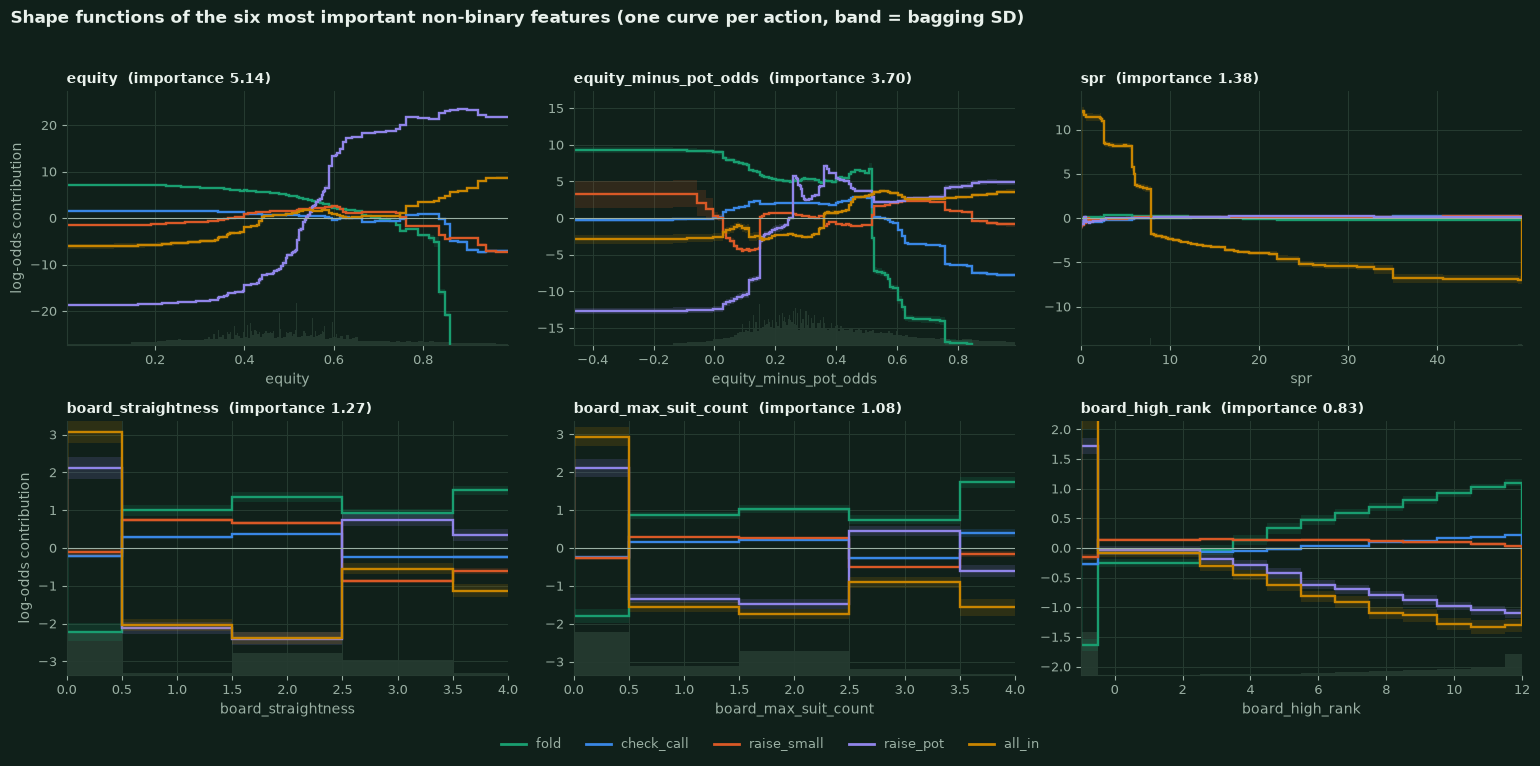

**Reading.** The six features are `equity`, `equity_minus_pot_odds`, `spr`, `board_straightness`, `board_max_suit_count`, `board_high_rank`. In the `equity` panel the `raise_pot` curve climbs from -19 (equity near 0) to +23 at its maximum, `fold` falls from +7 to -37: a pure strong-hand/weak-hand axis - the amplitudes (tens of log-odds) are the signature of fitting noise-free threshold labels for 300 rounds. `spr` matters almost only for `all_in` (the push-or-fold and monster-shove rules), and the board-texture counts (`board_straightness`, `board_max_suit_count`) are in the top six although they are not hand strength: the teacher has an explicit *wet board* rule, and their bins at 0 also identify preflop states (no board yet), which separates the preflop rules from the post-flop ones. The bagging band is thin (median SD 0.15 against a median |score| of 2.03 in the `equity` panel): the ten bags agree with each other - which measures the stability of the *fitting procedure*, not the uncertainty of the model about new data.

In [25]:
binary = {n for n in FEATURE_NAMES if VAL_FRAME[n].nunique() <= 2}
shape_features = [t for t in imp[imp["kind"] == "main"]["term"] if t not in binary][:6]


def draw_shape(ax, feature: str, *, xlim=None, legend: bool = False, clip: float = 0.98) -> pd.DataFrame:
    """Step plot of one feature's shape function for all five actions with a data-density strip underneath."""
    frame = ebm_explain.shape_frame(AGENT, feature, VAL.X)
    edges = np.append(frame["low"].to_numpy(), frame["high"].to_numpy()[-1])
    scores = frame[ACTIONS].to_numpy()
    spread = frame[[f"{a}_std" for a in ACTIONS]].to_numpy()
    twin = ax.twinx()
    density = frame["share"] / (frame["high"] - frame["low"]).clip(lower=1e-9)
    twin.bar((frame["low"] + frame["high"]) / 2, density / density.max(), width=(frame["high"] - frame["low"]), color=nbp.GRID, alpha=0.9)
    twin.set_ylim(0, 6)
    twin.set_yticks([])
    twin.grid(False)
    twin.spines[:].set_visible(False)
    ax.set_zorder(twin.get_zorder() + 1)
    ax.patch.set_visible(False)
    for i, a in enumerate(ACTIONS):
        ax.stairs(scores[:, i], edges, color=ACTION_COLORS[a], label=a, linewidth=1.7)
        ax.stairs(scores[:, i] + spread[:, i], edges, baseline=scores[:, i] - spread[:, i], fill=True, color=ACTION_COLORS[a], alpha=0.16, linewidth=0)
    limit = float(np.quantile(np.abs(scores), clip)) * 1.25 or 1.0
    ax.set_ylim(-limit, limit)
    ax.axhline(0, color=nbp.MUTED, linewidth=0.8)
    if xlim is None:
        values = VAL_FRAME[feature].to_numpy()
        xlim = (float(values.min()), float(np.quantile(values, 0.997)))
    ax.set_xlim(*xlim)
    ax.set_xlabel(feature)
    if legend:
        ax.legend(ncols=5, loc="upper center", bbox_to_anchor=(0.5, 1.0), fontsize=8)
    return frame


fig, axes = plt.subplots(2, 3, figsize=(15.5, 7.6))
for k, (ax, feature) in enumerate(zip(axes.ravel(), shape_features)):
    draw_shape(ax, feature)
    ax.set_title(f"{feature}  (importance {imp.set_index('term').loc[feature, 'importance']:.2f})", loc="left", fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("log-odds contribution")
handles = [plt.Line2D([0], [0], color=ACTION_COLORS[a], linewidth=2) for a in ACTIONS]
fig.legend(handles, ACTIONS, loc="lower center", ncols=5, fontsize=9, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Shape functions of the six most important non-binary features (one curve per action, band = bagging SD)", x=0.01, ha="left", fontsize=12, fontweight="bold", color=nbp.TEXT)
fig.tight_layout(rect=(0, 0.03, 1, 0.96))
nbp.savefig("nb01_shape_functions", fig)
plt.show()
equity_shape = ebm_explain.shape_frame(AGENT, "equity", VAL.X)
bag_sd = float(np.median(equity_shape[[f"{a}_std" for a in ACTIONS]].to_numpy()))
amplitude = float(np.median(np.abs(equity_shape[ACTIONS].to_numpy())))
display(Markdown(
    f"**Reading.** The six features are {', '.join(f'`{f}`' for f in shape_features)}. In the `equity` panel the `raise_pot` curve climbs from {equity_shape['raise_pot'].iloc[0]:+.0f} (equity near 0) to {equity_shape['raise_pot'].max():+.0f} at its maximum, "
    f"`fold` falls from {equity_shape['fold'].iloc[0]:+.0f} to {equity_shape['fold'].min():+.0f}: a pure strong-hand/weak-hand axis - the amplitudes (tens of log-odds) are the signature of fitting noise-free threshold labels for 300 rounds. "
    f"`spr` matters almost only for `all_in` (the push-or-fold and monster-shove rules), and the board-texture counts (`board_straightness`, `board_max_suit_count`) are in the top six although they are not hand strength: the teacher has an explicit *wet board* rule, and their bins at 0 also identify preflop states (no board yet), which separates the preflop rules from the post-flop ones. "
    f"The bagging band is thin (median SD {bag_sd:.2f} against a median |score| of {amplitude:.2f} in the `equity` panel): the ten bags agree with each other - which measures the stability of the *fitting procedure*, not the uncertainty of the model about new data."
))

### 6.4 Pairwise interactions `[data]`

A pair term is a table over two features' bins: it adds a score that a sum of the two shape functions cannot express - "equity matters *differently* against a station than against a nit". Below, the six most important pairs, each drawn for the action it moves most
(blue pushes the action up, red down, grey no effect; the axes are the bins of the two features). InterpretML's own `show` cannot draw them for multi-class models; `poker_arena.explain.ebm.interaction_surface` can.

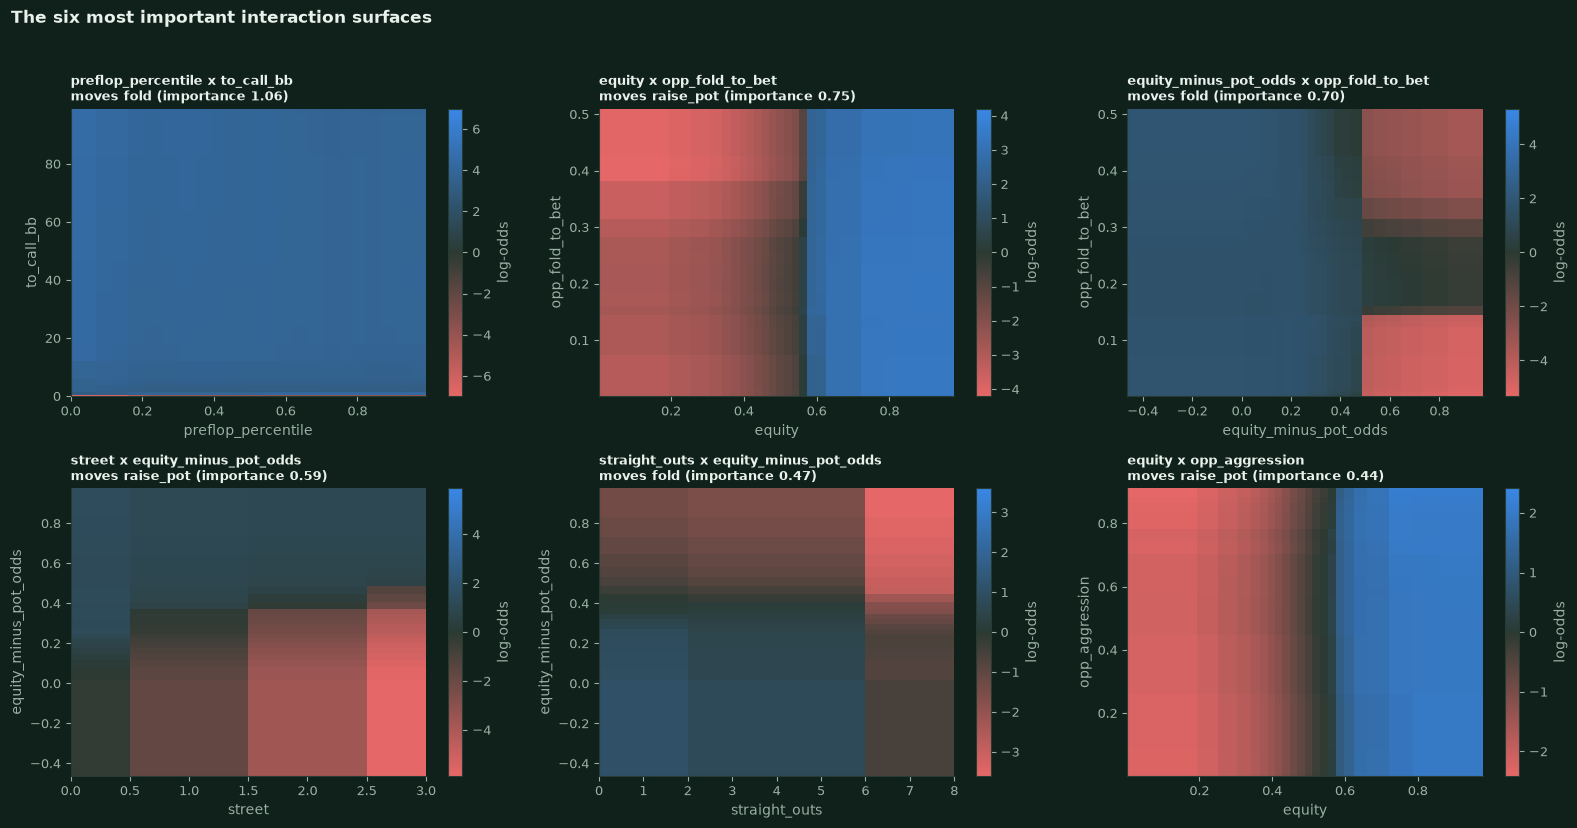

**What the pairs add `[data]`.** Deleting the 40 pair terms from the committed model *without refitting* lowers the legal-masked agreement from 97.86% to 80.08% (macro-F1 0.9721 -> 0.5694, log-loss 0.060 -> 1.165). That is an *ablation* of a fitted model, not a retrained additive model. The retrained comparison at full scale is the saved tuning record of section 4.4 (about 96.7% without pairs against 97.3-98.3% with them) and the toy refits of section 4.3 (95.30% -> 95.96% with 15 pairs).

**Adding the pairs back** (same 20,000 validation states as section 6.1, no refit; the main effects are always kept):

| pair terms kept (most important first) | masked agreement | macro-F1 | log-loss |
|---|---|---|---|
| 0 | 80.62% | 0.5735 | 1.134 |
| 5 | 88.83% | 0.8105 | 0.307 |
| 10 | 93.95% | 0.8962 | 0.150 |
| 20 | 96.91% | 0.9642 | 0.080 |
| 40 | 98.04% | 0.9759 | 0.057 |

The committed model's main effects are *not* a standalone additive model: with all pair terms deleted the model is a much poorer classifier than a purely additive model that is refitted (section 4.4: about 96.7%). The 40 pairs are therefore not a small correction in this model. Why the main-effect part alone is so much weaker than a refitted additive model was not investigated (a hypothesis: the pair stage and InterpretML's post-processing of the terms move information between main and pair terms). Either way, read the shape functions of section 6.3 as the model's *main-effect part*, and the pair surfaces as an integral part of the explanation.

In [26]:
pair_terms = imp[imp["kind"] == "interaction"].reset_index(drop=True)
fig, axes = plt.subplots(2, 3, figsize=(16.0, 8.4))
for ax, row in zip(axes.ravel(), pair_terms.head(6).itertuples()):
    strongest = imp_by_action.loc[row.term].astype(float).idxmax()
    surface = ebm_explain.interaction_surface(AGENT, row.term, strongest)
    limit = float(np.abs(surface.to_numpy()).max()) or 1.0
    mesh = ax.pcolormesh(surface.attrs["x_edges"], surface.attrs["y_edges"], surface.to_numpy(), cmap=nbp.DIVERGING, vmin=-limit, vmax=limit, shading="flat")
    ax.grid(False)
    ax.set_xlabel(surface.attrs["features"][0])
    ax.set_ylabel(surface.attrs["features"][1])
    for axis_setter, name in ((ax.set_xlim, surface.attrs["features"][0]), (ax.set_ylim, surface.attrs["features"][1])):
        column = VAL_FRAME[name].to_numpy()
        axis_setter(float(column.min()), float(np.quantile(column, 0.995)))  # where the data live
    ax.set_title(f"{row.term}\nmoves {strongest} (importance {row.importance:.2f})", loc="left", fontsize=9)
    fig.colorbar(mesh, ax=ax, label="log-odds")
fig.suptitle("The six most important interaction surfaces", x=0.01, ha="left", fontsize=12, fontweight="bold", color=nbp.TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.96))
nbp.savefig("nb01_interactions", fig)
plt.show()

# what do the pair terms add? delete them from the committed model (no refit) and score the remainder
main_idx = [i for i, f in enumerate(TERM_FEATURES) if len(f) == 1]
logit_main, logit_all, chunks = [], [], np.array_split(np.arange(len(VAL.y)), 8)
for chunk in chunks:
    scores = MODEL.eval_terms(VAL.X[chunk])
    logit_all.append(INTERCEPT[None, :] + scores.sum(axis=1))
    logit_main.append(INTERCEPT[None, :] + scores[:, main_idx].sum(axis=1))
ablation = {name: evaluate_classifier(softmax(np.vstack(parts)), VAL.y, VAL.legal, VAL.street) for name, parts in (("all 85 terms (committed model)", logit_all), ("main effects only (the 40 pairs deleted, no refit)", logit_main))}
acc_all, acc_main = ablation["all 85 terms (committed model)"]["masked_accuracy"], ablation["main effects only (the 40 pairs deleted, no refit)"]["masked_accuracy"]
display(Markdown(
    f"**What the pairs add `[data]`.** Deleting the {len(TERM_NAMES) - n_main_terms} pair terms from the committed model *without refitting* lowers the legal-masked agreement from {pct(acc_all, 2)} to {pct(acc_main, 2)} "
    f"(macro-F1 {ablation['all 85 terms (committed model)']['masked_macro_f1']:.4f} -> {ablation['main effects only (the 40 pairs deleted, no refit)']['masked_macro_f1']:.4f}, log-loss {ablation['all 85 terms (committed model)']['log_loss']:.3f} -> {ablation['main effects only (the 40 pairs deleted, no refit)']['log_loss']:.3f}). "
    f"That is an *ablation* of a fitted model, not a retrained additive model. "
    f"The retrained comparison at full scale is the saved tuning record of section 4.4 (about 96.7% without pairs against 97.3-98.3% with them) and the toy refits of section 4.3 ({pct(toy[toy_main_name]['metrics']['masked_accuracy'], 2)} -> {pct(toy[toy_inter_name]['metrics']['masked_accuracy'], 2)} with {TOY_INTERACTIONS} pairs)."
))

pair_index = [TERM_NAMES.index(t) for t in pair_terms["term"]]  # pair terms, most important first
curve_rows = []
for k in (0, 5, 10, 20, len(pair_index)):
    used = main_idx + pair_index[:k]
    m = evaluate_classifier(softmax(INTERCEPT[None, :] + TERMS[:, used, :].sum(axis=1)), YF, LF, VAL.street[FID_IDX])
    curve_rows.append({"pair terms kept (most important first)": k, "masked agreement": pct(m["masked_accuracy"], 2), "macro-F1": f"{m['masked_macro_f1']:.4f}", "log-loss": f"{m['log_loss']:.3f}"})
display(Markdown(f"**Adding the pairs back** (same {len(XF):,} validation states as section 6.1, no refit; the main effects are always kept):"))
display(md_table(pd.DataFrame(curve_rows)))
display(Markdown(
    "The committed model's main effects are *not* a standalone additive model: with all pair terms deleted the model is a much poorer classifier than a purely additive model that is refitted (section 4.4: about 96.7%). "
    f"The {len(TERM_NAMES) - n_main_terms} pairs are therefore not a small correction in this model. Why the main-effect part alone is so much weaker than a refitted additive model was not investigated "
    "(a hypothesis: the pair stage and InterpretML's post-processing of the terms move information between main and pair terms). Either way, read the shape functions of section 6.3 as the model's *main-effect part*, and the pair surfaces as an integral part of the explanation."
))

## 7. Local explanations of concrete poker decisions

### 7.1 How to read a local explanation

For one state `x` the EBM evaluates every term at `x` and adds the scores: `logit_k(x) = b_k + sum_t score_t,k(x)`. The **contribution of a term to the chosen action** is `score_t,chosen(x)`: positive pushes the model towards that action, negative away from it.
That is what `EBMAgent.explain` reports (`top_features`). Because the logit of an action is only meaningful *relative to the other actions*, we add a second view: the **contrast** between the chosen action and its closest rival
(`score_t,chosen - score_t,rival`: "why this action rather than that one?"). The rival is the teacher's action when the EBM disagrees with the teacher, else the model's second choice among the legal actions.

### 7.2 The example cases

`poker_arena.explain.notebook_cases.select_example_cases` draws a small, diverse, *reproducible* set of real **validation** decisions (one per situation type, seeded with `CASE_SEED`) - the XGBoost notebook explains exactly the same states.
The dataset stores features, not cards, so each situation is described by what the player observes. For each case we show the teacher's rule trace (the ground truth), the EBM's probabilities and its term contributions.

#### Case 1: Strong value bet

*Turn, on the button, in position. I hold 84 suited (pairing the board); my best five-card hand is two pair, equity against a random hand 90%. Board: highest card 9, dry (no flush or straight pressure). Pot 12.0 bb, effective stack 94 bb (SPR 7.8). Nobody has bet: I can check or bet. Observed over 628 earlier hands, the opponent (a 'call_station' policy) plays VPIP 90%, PFR 0%, postflop aggression 0%, folds to a bet 0% of the time. Legal actions: check_call, raise_small, raise_pot, all_in.*

* **Teacher (ground truth):** raise_pot - *Strong hand (90% equity) on a dry board: bet pot size for value and protection.* Rule trace `postflop > no_bet_to_face > value_bet_big`, margin 0.064.
* **EBM:** probabilities check_call 0.0%, raise_small 0.7%, raise_pot 99.3%, all_in 0.0% -> plays **raise_pot** (agrees with the teacher).
* **EBM's explanation:** the three largest contributions to `raise_pot` are `equity` (+23.2), `equity_minus_pot_odds` (+5.0), `equity x opp_fold_to_bet` (+3.4); the term that separates it most from `raise_small` is `equity` (+27.4). The deciding rule reads `board_max_suit_count`, `board_straightness`, `equity`, `facing_bet`, `flush_draw`, `i_have_initiative`, `is_button`, `opp_fold_to_bet`, `spr`, `straight_outs`, `street`: the top term is **read by the rule**, the top contrast term is **read by the rule**.

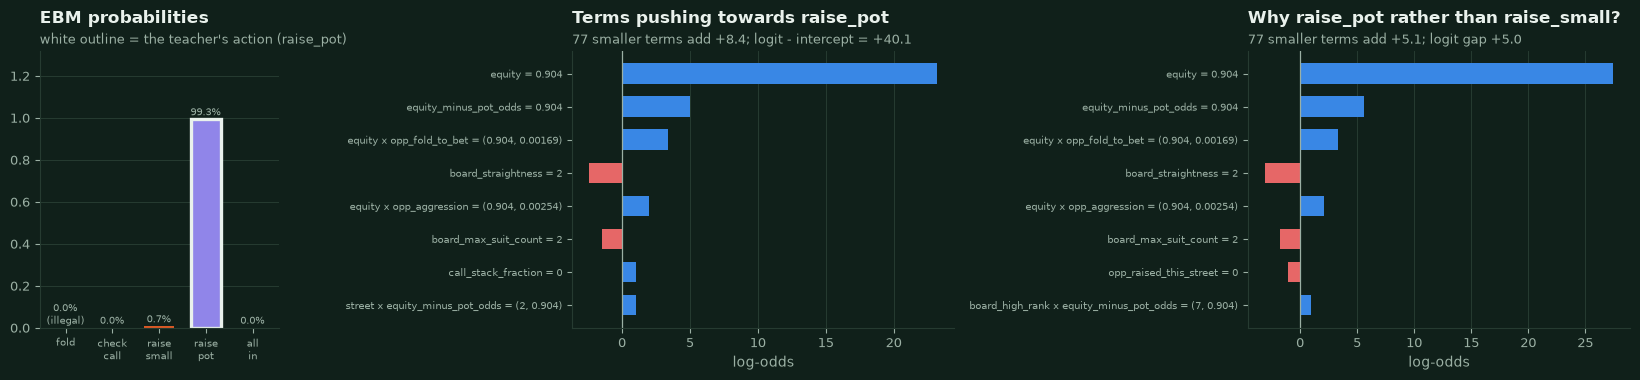

#### Case 2: Thin value bet

*Flop, in the big blind, out of position. I hold 82 suited (pairing the board); my best five-card hand is one pair, equity against a random hand 52%. Board: highest card T, dry (no flush or straight pressure). Pot 6.0 bb, effective stack 97 bb (SPR 16.2). Nobody has bet: I can check or bet. Observed over 11 earlier hands, the opponent (a 'maniac' policy) plays VPIP 78%, PFR 66%, postflop aggression 75%, folds to a bet 14% of the time. Legal actions: check_call, raise_small, raise_pot, all_in.*

* **Teacher (ground truth):** raise_small - *Value bet: equity 52% clears the 52% value line (opponent folds 14% to bets).* Rule trace `postflop > no_bet_to_face > value_bet`, margin 0.004.
* **EBM:** probabilities check_call 7.7%, raise_small 92.3%, raise_pot 0.0%, all_in 0.0% -> plays **raise_small** (agrees with the teacher).
* **EBM's explanation:** the three largest contributions to `raise_small` are `equity` (+1.9), `equity_minus_pot_odds` (+1.6), `opp_raised_this_street` (+1.3); the term that separates it most from `check_call` is `opp_raised_this_street` (+1.7). The deciding rule reads `board_max_suit_count`, `board_straightness`, `equity`, `facing_bet`, `flush_draw`, `i_have_initiative`, `is_button`, `opp_fold_to_bet`, `spr`, `straight_outs`, `street`: the top term is **read by the rule**, the top contrast term is **partial proxy**.

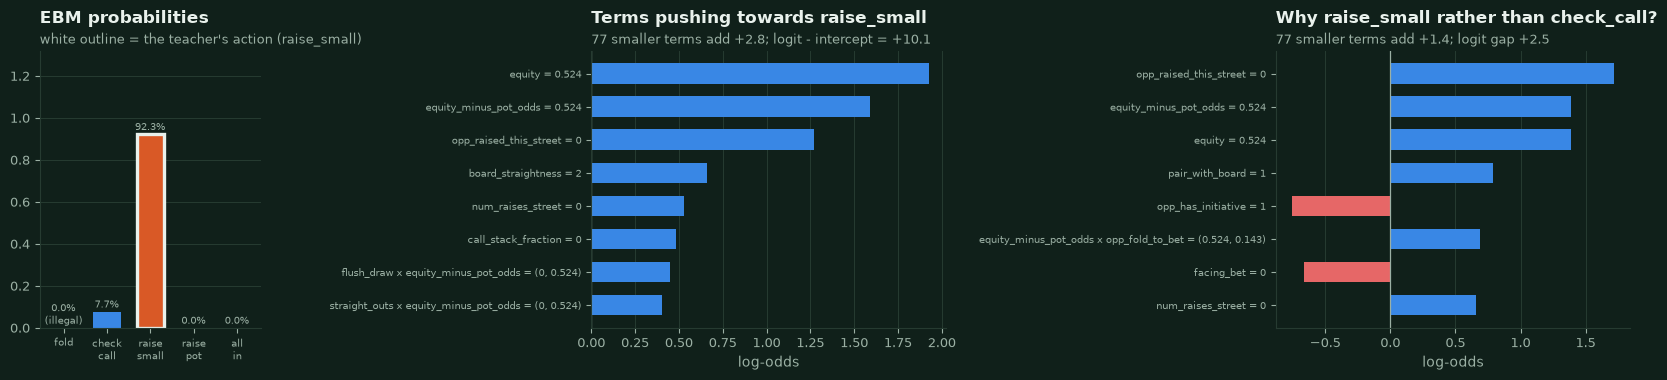

#### Case 3: Semi-bluff with a draw

*Flop, in the big blind, out of position. I hold 86 offsuit; my best five-card hand is high card, plus a flush draw and a gutshot straight draw (4 outs), 2 overcards to the board, equity against a random hand 46%. Board: highest card 5, 3 cards of one suit, connected (straight possible). Pot 3.0 bb, effective stack 98 bb (SPR 24.5). I face a bet of 1.0 bb (0.50 x pot, pot odds 25%). Observed over 25 earlier hands, the opponent (a 'random' policy) plays VPIP 72%, PFR 55%, postflop aggression 57%, folds to a bet 30% of the time. Legal actions: fold, check_call, raise_small, raise_pot, all_in.*

* **Teacher (ground truth):** raise_small - *Semi-bluff raise: strong draw (46% equity) and the opponent folds 30% of the time.* Rule trace `postflop > facing_bet > raise_semi_bluff`, margin 0.154.
* **EBM:** probabilities fold 4.4%, check_call 64.4%, raise_small 31.2%, raise_pot 0.0%, all_in 0.0% -> plays **check_call** (**disagrees**: the teacher plays raise_small).
* **EBM's explanation:** the three largest contributions to `check_call` are `equity_minus_pot_odds` (+2.0), `flush_draw` (-1.5), `opp_raised_this_street` (+0.8); the term that separates it most from `raise_small` is `flush_draw` (-3.3). The deciding rule reads `bet_fraction_of_pot`, `board_max_suit_count`, `board_straightness`, `equity`, `facing_bet`, `flush_draw`, `is_button`, `num_raises_street`, `opp_aggression`, `opp_fold_to_bet`, `pot_odds`, `spr`, `straight_outs`, `street`: the top term is **exact re-encoding**, the top contrast term is **read by the rule**.

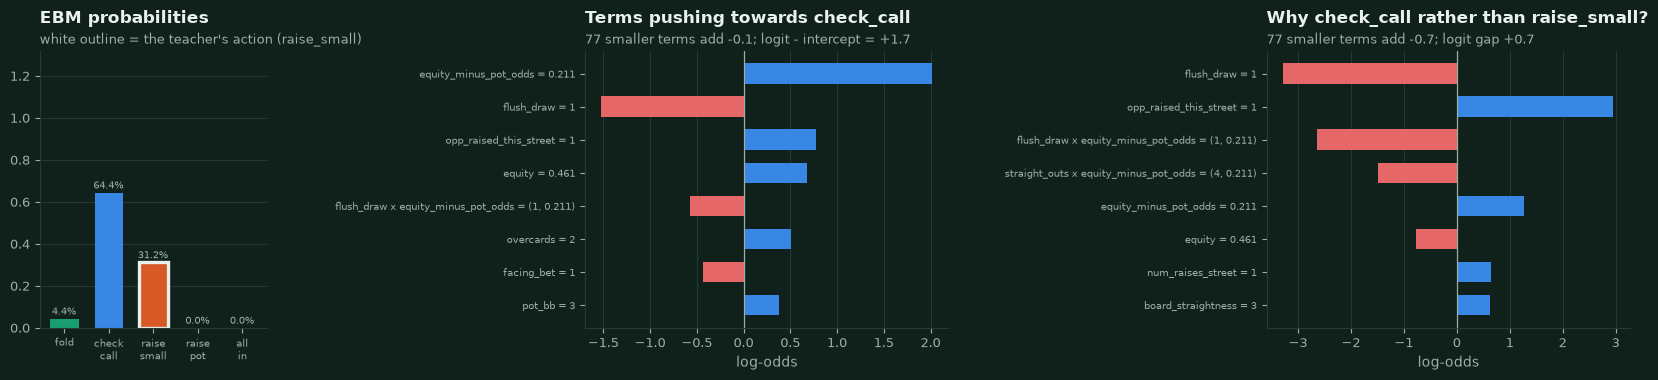

#### Case 4: Fold facing a big bet

*Turn, in the big blind, out of position. I hold a pocket pair of 4s; my best five-card hand is two pair, equity against a random hand 19%. Board: highest card J, paired. Pot 24.0 bb, effective stack 82 bb (SPR 2.3). I face a bet of 12.0 bb (1.00 x pot, pot odds 33%). Observed over 35 earlier hands, the opponent (a 'teacher' policy) plays VPIP 84%, PFR 46%, postflop aggression 89%, folds to a bet 47% of the time. Legal actions: fold, check_call, raise_small, raise_pot, all_in.*

* **Teacher (ground truth):** fold - *Fold: equity 19% less 9% for the bettor's range is 10%, below the 38% price (pot odds 33%).* Rule trace `postflop > facing_bet > fold_odds`, margin 0.281.
* **EBM:** probabilities fold 100.0%, check_call 0.0%, raise_small 0.0%, raise_pot 0.0%, all_in 0.0% -> plays **fold** (agrees with the teacher).
* **EBM's explanation:** the three largest contributions to `fold` are `equity_minus_pot_odds` (+9.4), `equity` (+7.1), `preflop_percentile x to_call_bb` (+3.7); the term that separates it most from `check_call` is `equity_minus_pot_odds` (+9.6). The deciding rule reads `bet_fraction_of_pot`, `board_max_suit_count`, `board_straightness`, `equity`, `facing_bet`, `flush_draw`, `is_button`, `num_raises_street`, `opp_aggression`, `opp_fold_to_bet`, `pot_odds`, `spr`, `straight_outs`, `street`: the top term is **exact re-encoding**, the top contrast term is **exact re-encoding**.

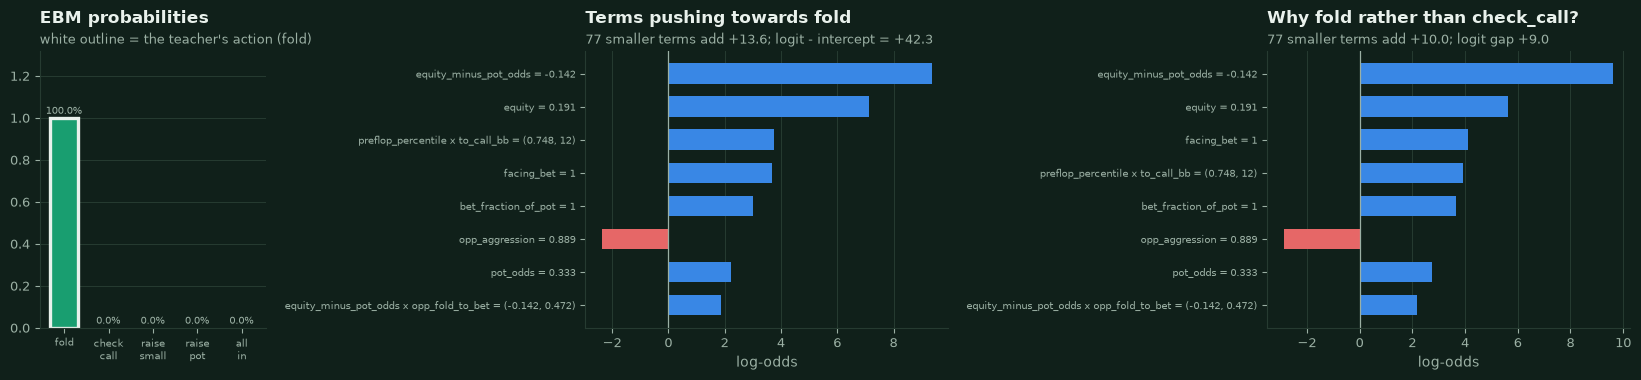

#### Case 5: Call with marginal equity

*Flop, in the big blind, out of position. I hold K3 offsuit; my best five-card hand is high card, plus a gutshot straight draw (4 outs), 1 overcard to the board, equity against a random hand 44%. Board: highest card Q, connected (straight possible). Pot 6.0 bb, effective stack 96 bb (SPR 12.0). I face a bet of 2.0 bb (0.50 x pot, pot odds 25%). Observed over 115 earlier hands, the opponent (a 'tight' policy) plays VPIP 80%, PFR 32%, postflop aggression 75%, folds to a bet 45% of the time. Legal actions: fold, check_call, raise_small, raise_pot, all_in.*

* **Teacher (ground truth):** check_call - *Call: equity 44% less 12% for the bettor's range is 31%, above the 30% price (pot odds 25%).* Rule trace `postflop > facing_bet > call_odds`, margin 0.015.
* **EBM:** probabilities fold 78.8%, check_call 21.2%, raise_small 0.0%, raise_pot 0.0%, all_in 0.0% -> plays **fold** (**disagrees**: the teacher plays check_call).
* **EBM's explanation:** the three largest contributions to `fold` are `equity` (+5.6), `equity_minus_pot_odds` (+5.4), `facing_bet` (+3.7); the term that separates it most from `check_call` is `equity` (+4.9). The deciding rule reads `bet_fraction_of_pot`, `board_max_suit_count`, `board_straightness`, `equity`, `facing_bet`, `flush_draw`, `is_button`, `num_raises_street`, `opp_aggression`, `opp_fold_to_bet`, `pot_odds`, `spr`, `straight_outs`, `street`: the top term is **read by the rule**, the top contrast term is **read by the rule**.

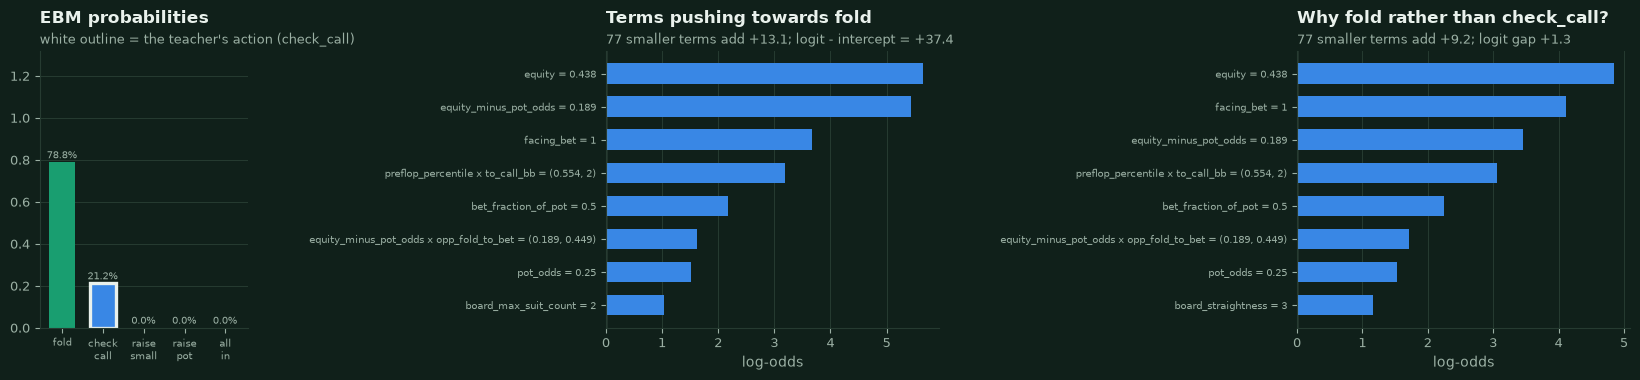

#### Case 6: Preflop open from the button

*Preflop, on the button (small blind, first to act). I hold K9 offsuit, better than 78% of all starting hands (equity against a random hand 58%). Pot 1.5 bb, effective stack 99 bb (SPR 49.5). I am first to act: fold, complete the small blind (0.5 bb more) or raise. Observed over 620 earlier hands, the opponent (a 'maniac' policy) plays VPIP 96%, PFR 83%, postflop aggression 87%, folds to a bet 0% of the time. Legal actions: fold, check_call, raise_small, raise_pot, all_in.*

* **Teacher (ground truth):** raise_small - *Button: hand strength 78% clears the 18% opening line, so raise.* Rule trace `preflop > pre_open`, margin 0.603.
* **EBM:** probabilities fold 0.0%, check_call 0.0%, raise_small 100.0%, raise_pot 0.0%, all_in 0.0% -> plays **raise_small** (agrees with the teacher).
* **EBM's explanation:** the three largest contributions to `raise_small` are `equity` (+2.3), `opp_raised_this_street` (+1.3), `pot_bb` (+0.8); the term that separates it most from `check_call` is `equity_minus_pot_odds` (-2.0). The deciding rule reads `effective_stack_bb`, `is_button`, `num_raises_street`, `preflop_percentile`, `street`, `to_call_bb`: the top term is **exact re-encoding**, the top contrast term is **exact re-encoding**.

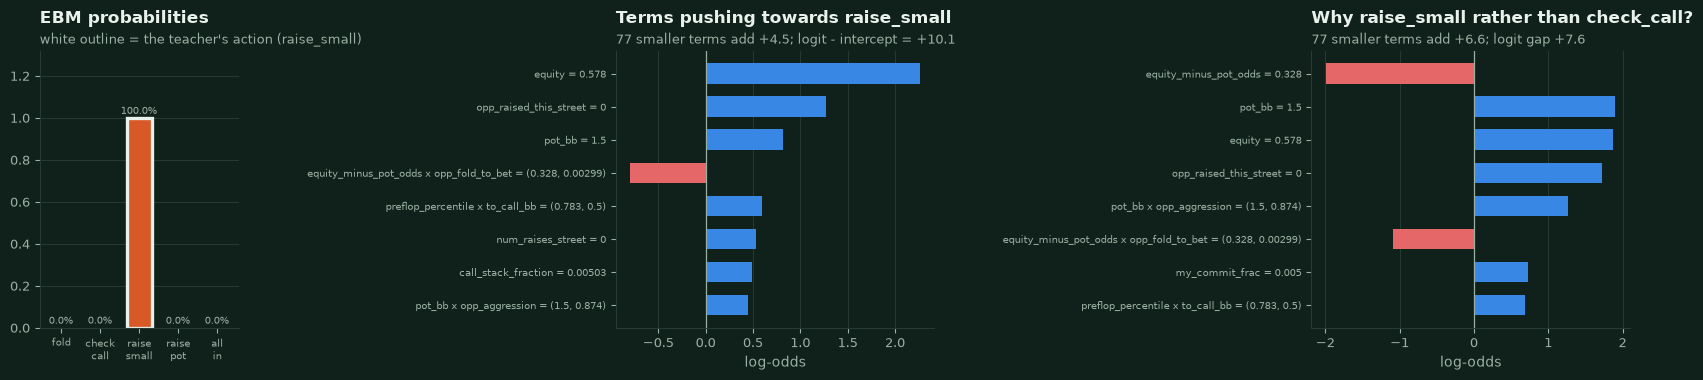

#### Case 7: Short-stack push / fold

*Preflop, on the button (small blind, first to act). I hold A5 offsuit, better than 77% of all starting hands (equity against a random hand 58%). Pot 1.5 bb, effective stack 11 bb (SPR 5.7). I am first to act: fold, complete the small blind (0.5 bb more) or raise. Observed over 212 earlier hands, the opponent (a 'call_station' policy) plays VPIP 88%, PFR 1%, postflop aggression 1%, folds to a bet 1% of the time. Legal actions: fold, check_call, raise_small, raise_pot, all_in.*

* **Teacher (ground truth):** all_in - *Short stack (12 bb): shove, hand strength 77% is above the 30% push line.* Rule trace `preflop > pre_push`, margin 0.468.
* **EBM:** probabilities fold 0.0%, check_call 0.0%, raise_small 2.0%, raise_pot 0.0%, all_in 98.0% -> plays **all_in** (agrees with the teacher).
* **EBM's explanation:** the three largest contributions to `all_in` are `spr` (+8.1), `board_straightness` (+3.1), `board_max_suit_count` (+2.9); the term that separates it most from `raise_small` is `spr` (+8.1). The deciding rule reads `effective_stack_bb`, `is_button`, `num_raises_street`, `preflop_percentile`, `street`, `to_call_bb`: the top term is **exact re-encoding**, the top contrast term is **exact re-encoding**.

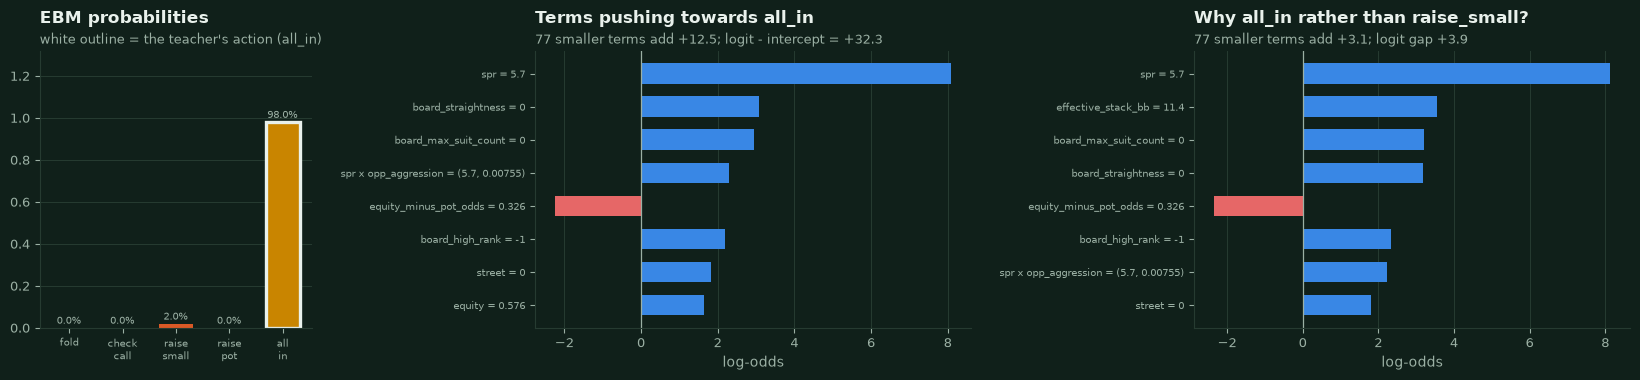

#### Case 8: River decision facing a bet

*River, in the big blind, out of position. I hold J9 offsuit; my best five-card hand is one pair, equity against a random hand 29%. Board: highest card A, paired. Pot 6.0 bb, effective stack 96 bb (SPR 12.0). I face a bet of 2.0 bb (0.50 x pot, pot odds 25%). Observed over 443 earlier hands, the opponent (a 'tight' policy) plays VPIP 81%, PFR 36%, postflop aggression 83%, folds to a bet 42% of the time. Legal actions: fold, check_call, raise_small, raise_pot, all_in.*

* **Teacher (ground truth):** fold - *Fold: equity 29% less 5% for the bettor's range is 23%, below the 30% price (pot odds 25%).* Rule trace `postflop > facing_bet > fold_odds`, margin 0.067.
* **EBM:** probabilities fold 98.2%, check_call 1.8%, raise_small 0.0%, raise_pot 0.0%, all_in 0.0% -> plays **fold** (agrees with the teacher).
* **EBM's explanation:** the three largest contributions to `fold` are `equity_minus_pot_odds` (+8.2), `equity` (+6.7), `facing_bet` (+3.7); the term that separates it most from `check_call` is `equity_minus_pot_odds` (+7.4). The deciding rule reads `bet_fraction_of_pot`, `board_max_suit_count`, `board_straightness`, `equity`, `facing_bet`, `flush_draw`, `is_button`, `num_raises_street`, `opp_aggression`, `opp_fold_to_bet`, `pot_odds`, `spr`, `straight_outs`, `street`: the top term is **exact re-encoding**, the top contrast term is **exact re-encoding**.

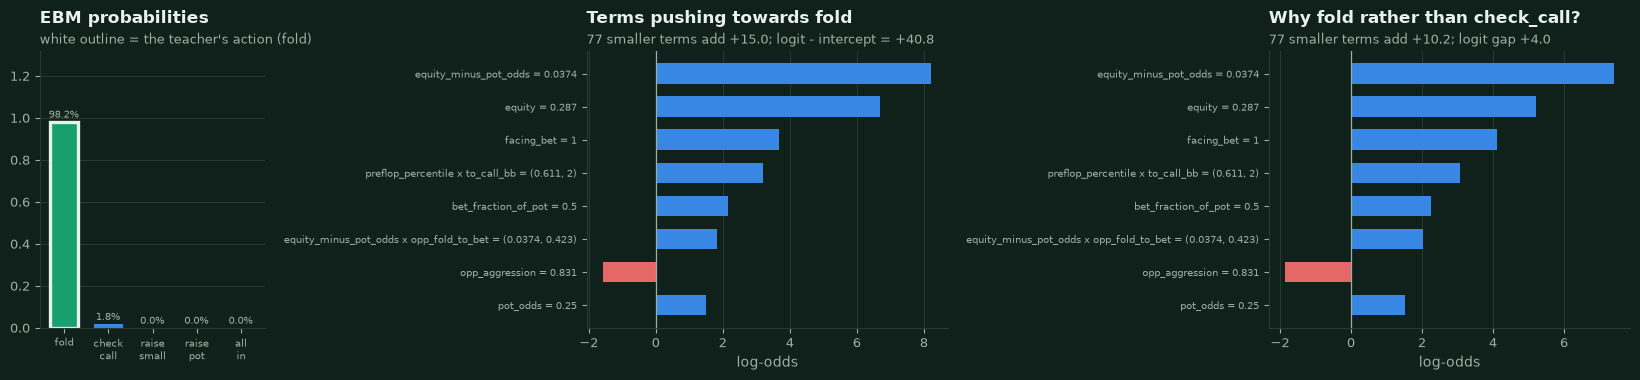

In [27]:
CASES = select_example_cases(VAL_FRAME, n=N_CASES, seed=CASE_SEED)
assert all(c.hand_id in set(VAL_FRAME["hand_id"]) for c in CASES)  # validation hands only

# ---- the teacher's ground truth: which features does the deciding rule read? (derived from the cascade in agents/teacher.py) ----
PRE_UNOPENED = {"street", "num_raises_street", "is_button", "preflop_percentile", "effective_stack_bb", "to_call_bb"}
PRE_FACING = PRE_UNOPENED | {"bet_fraction_of_pot", "opp_pfr", "equity", "pot_odds"}
POST_FREE = {"street", "facing_bet", "equity", "opp_fold_to_bet", "board_max_suit_count", "board_straightness", "spr", "is_button", "i_have_initiative", "flush_draw", "straight_outs"}
POST_FACING = {"street", "facing_bet", "equity", "bet_fraction_of_pot", "num_raises_street", "opp_aggression", "flush_draw", "straight_outs", "pot_odds", "is_button", "spr",
               "board_max_suit_count", "board_straightness", "opp_fold_to_bet"}  # fmt: skip
FAMILIES = {
    "preflop, unopened pot": (PRE_UNOPENED, ["pre_push", "pre_fold_short", "pre_open_pot", "pre_open", "pre_limp", "pre_fold_trash", "pre_iso_pot", "pre_iso", "pre_check_option"]),
    "preflop, facing a raise": (PRE_FACING, ["pre_shove_premium", "pre_3bet", "pre_4bet", "pre_call", "pre_fold"]),
    "postflop, checked to": (POST_FREE, ["monster_shove", "monster_bet", "value_bet_big", "value_bet", "semi_bluff_bet", "cbet_bluff", "check_weak"]),
    "postflop, facing a bet": (POST_FACING, ["raise_value", "raise_semi_bluff", "call_odds", "fold_odds"]),
}
FAMILY_OF_RULE = {rule: family for family, (_, rules) in FAMILIES.items() for rule in rules}
READ = {family: reads for family, (reads, _) in FAMILIES.items()}
# exact re-encodings: features that are deterministic functions of read features (identities of section 3.4)
PREFLOP_CONSTANTS = {"board_paired", "board_max_suit_count", "board_straightness", "board_high_rank", "overcards", "pair_with_board", "flush_draw", "straight_outs"}  # no board yet: constants that merely say "preflop"
EXACT = {
    "preflop, unopened pot": {"equity", "equity_minus_pot_odds", "spr"} | PREFLOP_CONSTANTS,  # equity and percentile rank the same 169 hands; spr = effective stack / 2 bb here; board descriptors = street
    "preflop, facing a raise": {"equity_minus_pot_odds"} | PREFLOP_CONSTANTS,
    "postflop, checked to": {"equity_minus_pot_odds"},  # nobody bet: pot_odds = 0, so equity_minus_pot_odds IS equity
    "postflop, facing a bet": {"equity_minus_pot_odds"},  # = equity - pot_odds, both read
}
# partial proxies: features that feed the computation of a read feature, or share its information, without being an exact copy
NEIGHBOUR_GROUPS = {
    "hand": {"hole_high_rank", "hole_low_rank", "is_pair", "is_suited", "hole_gap", "made_hand_category", "overcards", "pair_with_board", "board_high_rank", "board_paired", "preflop_percentile", "equity"},
    "price": {"to_call_bb", "call_stack_fraction", "pot_bb", "pot_odds", "bet_fraction_of_pot", "equity_minus_pot_odds"},
    "stacks": {"my_stack_bb", "opp_stack_bb", "effective_stack_bb", "spr", "my_commit_frac", "opp_commit_frac", "call_stack_fraction"},
    "action history": {"opp_raised_this_street", "i_raised_this_street", "num_raises_street", "num_raises_hand", "opp_has_initiative", "i_have_initiative", "can_raise", "facing_all_in", "facing_bet"},
}  # fmt: skip
NEIGHBOURS = {family: set().union(*(group for group in NEIGHBOUR_GROUPS.values() if group & reads)) - reads - EXACT[family] for family, reads in READ.items()}
TIERS = ("read by the rule", "exact re-encoding", "partial proxy", "unrelated")


def tier_of(term: int, family: str) -> int:
    """0 = a feature of the term is read by the deciding rule; 1 = exact re-encoding of a read feature; 2 = partial proxy; 3 = unrelated."""
    names = TERM_FEATURES[term]
    for tier, reference in enumerate((READ[family], EXACT[family], NEIGHBOURS[family])):
        if any(n in reference for n in names):
            return tier
    return 3


def explain_state(x: np.ndarray, legal: np.ndarray, rival: int | None = None) -> dict:
    """Everything the local explanation of one state needs (all from the model's own term scores)."""
    scores = MODEL.eval_terms(x.reshape(1, -1))[0]  # (terms, actions)
    logits = INTERCEPT + scores.sum(axis=0)
    raw = softmax(logits.reshape(1, -1))[0]
    masked = np.where(legal, raw, 0.0)
    masked = masked / masked.sum()
    chosen = int(np.argmax(masked))
    if rival is None or rival == chosen:
        order = np.argsort(-np.where(legal, logits, -np.inf))
        rival = int(order[1]) if order[0] == chosen else int(order[0])
    return {"scores": scores, "logits": logits, "raw": raw, "masked": masked, "chosen": chosen, "rival": rival}


def short_value(value) -> str:
    return "(" + ", ".join(f"{v:.3g}" for v in value) + ")" if isinstance(value, (list, tuple)) else f"{value:.3g}"


def case_figure(case, info: dict) -> plt.Figure:
    """Probabilities, term contributions to the chosen action, and contrast with the rival action."""
    x = case.features
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 3.9), gridspec_kw={"width_ratios": [0.75, 1.2, 1.2]})
    ax = axes[0]
    bars = ax.bar(range(5), info["raw"], color=[ACTION_COLORS[a] if case.legal_mask[i] else nbp.GRID for i, a in enumerate(ACTIONS)], width=0.64)
    for i, bar in enumerate(bars):
        ax.annotate(f"{100 * info['raw'][i]:.1f}%" + ("" if case.legal_mask[i] else "\n(illegal)"), (i, info["raw"][i]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7.5, color=nbp.MUTED)
    bars[case.teacher_action].set_edgecolor(nbp.TEXT)
    bars[case.teacher_action].set_linewidth(2.4)
    ax.set_xticks(range(5), [a.replace("_", "\n") for a in ACTIONS], fontsize=7.5)
    ax.set_ylim(0, 1.32)
    ax.grid(axis="x", visible=False)
    nbp.title(ax, "EBM probabilities", f"white outline = the teacher's action ({case.teacher_action_name})")
    for ax, action, other, title in ((axes[1], info["chosen"], None, f"Terms pushing towards {ACTIONS[info['chosen']]}"), (axes[2], info["chosen"], info["rival"], f"Why {ACTIONS[info['chosen']]} rather than {ACTIONS[info['rival']]}?")):
        contribution = info["scores"][:, action] - (0.0 if other is None else info["scores"][:, other])
        order = np.argsort(-np.abs(contribution))[:8]
        labels = []
        for t in order:
            values = [x[FEATURE_INDEX[n]] for n in TERM_FEATURES[t]]
            labels.append(f"{TERM_NAMES[t]} = {short_value(values if len(values) > 1 else values[0])}")
        ax.barh(range(len(order)), contribution[order], color=[nbp.COOL if c > 0 else nbp.WARM for c in contribution[order]], height=0.62)
        ax.set_yticks(range(len(order)), labels, fontsize=7.5)
        ax.invert_yaxis()
        rest = float(np.delete(contribution, order).sum())
        ax.axvline(0, color=nbp.MUTED, linewidth=0.9)
        ax.grid(axis="y", visible=False)
        ax.set_xlabel("log-odds")
        total = float(contribution.sum()) + (INTERCEPT[action] - (0.0 if other is None else INTERCEPT[other]))
        sub = f"{len(contribution) - 8} smaller terms add {rest:+.1f}; " + (f"logit - intercept = {contribution.sum():+.1f}" if other is None else f"logit gap {total:+.1f}")
        nbp.title(ax, title, sub)
    fig.tight_layout()
    return fig


case_infos, case_rows = [], []
for number, case in enumerate(CASES, start=1):
    info = explain_state(case.features, case.legal_mask, rival=case.teacher_action)
    case_infos.append(info)
    package_top = AGENT.top_features(case.features, AbstractAction(info["chosen"]))[0]  # the package's own explanation must agree with ours
    assert package_top["feature"] == TERM_NAMES[int(np.argmax(np.abs(info["scores"][:, info["chosen"]])))]
    family = FAMILY_OF_RULE[case.teacher_rule]
    top_terms = np.argsort(-np.abs(info["scores"][:, info["chosen"]]))[:3]
    contrast = info["scores"][:, info["chosen"]] - info["scores"][:, info["rival"]]
    top_contrast = int(np.argmax(np.abs(contrast)))
    case_rows.append({"case": number, "key": case.key, "family": family, "teacher": case.teacher_action_name, "rule": case.teacher_rule, "ebm": ACTIONS[info["chosen"]], "p": info["masked"][info["chosen"]],
                      "top terms": [TERM_NAMES[t] for t in top_terms], "tiers": [TIERS[tier_of(t, family)] for t in top_terms], "top contrast": TERM_NAMES[top_contrast], "contrast tier": TIERS[tier_of(top_contrast, family)]})
    reads = sorted(READ[family] & set(FEATURE_NAMES))
    display(Markdown(
        f"#### Case {number}: {case.title}\n\n"
        f"*{case.description}*\n\n"
        f"* **Teacher (ground truth):** {case.teacher_action_name} - *{case.teacher_summary}* Rule trace `{' > '.join(case.teacher_rules)}`, margin {case.teacher_margin:.3f}.\n"
        f"* **EBM:** probabilities " + ", ".join(f"{a} {100 * info['raw'][i]:.1f}%" for i, a in enumerate(ACTIONS) if case.legal_mask[i]) + f" -> plays **{ACTIONS[info['chosen']]}**"
        + (" (agrees with the teacher)." if info["chosen"] == case.teacher_action else f" (**disagrees**: the teacher plays {case.teacher_action_name}).") + "\n"
        f"* **EBM's explanation:** the three largest contributions to `{ACTIONS[info['chosen']]}` are " + ", ".join(f"`{TERM_NAMES[t]}` ({info['scores'][t, info['chosen']]:+.1f})" for t in top_terms)
        + f"; the term that separates it most from `{ACTIONS[info['rival']]}` is `{TERM_NAMES[top_contrast]}` ({contrast[top_contrast]:+.1f}). "
        f"The deciding rule reads {', '.join('`' + r + '`' for r in reads[:14])}{' ...' if len(reads) > 14 else ''}: the top term is **{TIERS[tier_of(int(top_terms[0]), family)]}**, the top contrast term is **{TIERS[tier_of(top_contrast, family)]}**."
    ))
    fig = case_figure(case, info)
    nbp.savefig(f"nb01_case_{number}_{case.key}", fig)
    plt.show()

In [28]:
if SHOW_INTERPRET_WIDGETS:
    display(Markdown("**InterpretML's interactive local explanation** of the same cases (`show(MODEL.explain_local(X, y))`; choose a case in the dropdown; needs a live kernel - GitHub shows nothing, the figures above show the same contributions)."))
    cases_frame = pd.DataFrame(np.vstack([c.features for c in CASES]), columns=list(FEATURE_NAMES))
    show(MODEL.explain_local(cases_frame, [c.teacher_action for c in CASES], name="example cases (y = the teacher's action)"))
case_table = pd.DataFrame(case_rows)
case_table["top 3 terms (tier)"] = [", ".join(f"`{t}` ({tier})" for t, tier in zip(r["top terms"], r["tiers"])) for r in case_rows]
display(md_table(pd.DataFrame({
    "case": case_table["case"], "situation": [f"`{k}`" for k in case_table["key"]], "teacher -> rule": [f"{t} (`{r}`)" for t, r in zip(case_table["teacher"], case_table["rule"])],
    "EBM": [f"{e} ({100 * p:.0f}%)" for e, p in zip(case_table["ebm"], case_table["p"])], "top-3 terms (tier w.r.t. the rule)": case_table["top 3 terms (tier)"],
    "top contrast term (tier)": [f"`{t}` ({tier})" for t, tier in zip(case_table["top contrast"], case_table["contrast tier"])],
})))
cases_agree = sum(r["ebm"] == r["teacher"] for r in case_rows)
cases_top_read = sum(r["tiers"][0] in TIERS[:2] for r in case_rows)
cases_contrast_read = sum(r["contrast tier"] in TIERS[:2] for r in case_rows)
display(Markdown(
    f"**Summary of the {len(CASES)} cases.** The EBM plays the teacher's action in {cases_agree} of {len(CASES)}; the term with the largest contribution to the chosen action is a feature the deciding rule reads (or an exact re-encoding of one) in {cases_top_read} of {len(CASES)}, "
    f"the term that best separates it from the rival action in {cases_contrast_read} of {len(CASES)}. Eight hand-picked-by-category cases are an illustration; section 7.3 measures the same thing on {len(XF):,} validation states."
))

**InterpretML's interactive local explanation** of the same cases (`show(MODEL.explain_local(X, y))`; choose a case in the dropdown; needs a live kernel - GitHub shows nothing, the figures above show the same contributions).

<!-- http://127.0.0.1:7001/2447042105488/ -->

| case | situation | teacher -> rule | EBM | top-3 terms (tier w.r.t. the rule) | top contrast term (tier) |
|---|---|---|---|---|---|
| 1 | `strong_value_bet` | raise_pot (`value_bet_big`) | raise_pot (99%) | `equity` (read by the rule), `equity_minus_pot_odds` (exact re-encoding), `equity x opp_fold_to_bet` (read by the rule) | `equity` (read by the rule) |
| 2 | `thin_value_bet` | raise_small (`value_bet`) | raise_small (92%) | `equity` (read by the rule), `equity_minus_pot_odds` (exact re-encoding), `opp_raised_this_street` (partial proxy) | `opp_raised_this_street` (partial proxy) |
| 3 | `semi_bluff` | raise_small (`raise_semi_bluff`) | check_call (64%) | `equity_minus_pot_odds` (exact re-encoding), `flush_draw` (read by the rule), `opp_raised_this_street` (partial proxy) | `flush_draw` (read by the rule) |
| 4 | `fold_big_bet` | fold (`fold_odds`) | fold (100%) | `equity_minus_pot_odds` (exact re-encoding), `equity` (read by the rule), `preflop_percentile x to_call_bb` (partial proxy) | `equity_minus_pot_odds` (exact re-encoding) |
| 5 | `marginal_call` | check_call (`call_odds`) | fold (79%) | `equity` (read by the rule), `equity_minus_pot_odds` (exact re-encoding), `facing_bet` (read by the rule) | `equity` (read by the rule) |
| 6 | `preflop_open` | raise_small (`pre_open`) | raise_small (100%) | `equity` (exact re-encoding), `opp_raised_this_street` (partial proxy), `pot_bb` (partial proxy) | `equity_minus_pot_odds` (exact re-encoding) |
| 7 | `push_fold` | all_in (`pre_push`) | all_in (98%) | `spr` (exact re-encoding), `board_straightness` (exact re-encoding), `board_max_suit_count` (exact re-encoding) | `spr` (exact re-encoding) |
| 8 | `river_decision` | fold (`fold_odds`) | fold (98%) | `equity_minus_pot_odds` (exact re-encoding), `equity` (read by the rule), `facing_bet` (read by the rule) | `equity_minus_pot_odds` (exact re-encoding) |

**Summary of the 8 cases.** The EBM plays the teacher's action in 6 of 8; the term with the largest contribution to the chosen action is a feature the deciding rule reads (or an exact re-encoding of one) in 8 of 8, the term that best separates it from the rival action in 7 of 8. Eight hand-picked-by-category cases are an illustration; section 7.3 measures the same thing on 20,000 validation states.

### 7.3 Explanation fidelity study: do the EBM's explanations point at what the teacher reads? `[data]`

Because the labels come from a known rule set we can test an explanation against the *truth*. For every state of a seeded sample of validation decisions (`FIDELITY_ROWS`), we take the term with the **largest absolute contribution** to the teacher's action
and ask which of four classes it falls into, relative to the **deciding rule's own cascade** (`READ`: the features that rule reads, written down from `agents/teacher.py`; the sets are validated below):

1. **read by the rule** - the term involves a feature the deciding rule reads;
2. **exact re-encoding** - a deterministic copy of a read feature (e.g. `equity_minus_pot_odds` = `equity - pot_odds`, which *is* `equity` whenever nobody has bet);
3. **partial proxy** - a feature that feeds the computation of a read feature or shares its information (hole-card ranks and made-hand category for equity; stack and commit features for the stack depth; ...);
4. **unrelated** - none of the above.

Two caveats shape the interpretation. (i) These classes were fixed *before* looking at the results but are a judgement; `equity`, `equity_minus_pot_odds`, `preflop_percentile` and price features are near-duplicates, so *credit assignment among them is arbitrary* - class 2 exists to
avoid punishing the model for that. (ii) A hit is weak evidence by construction when a feature is read by almost every rule (equity is): so every number is shown next to a **wrong-row null** - the same classification, but with the explanation of a *random other state* attached to the row's rule.
We also report the **contrastive** version (term with the largest contribution to the teacher's action *minus* the best rival's), which is the sharper "why this and not that".

In [29]:
# 1. validate the READ sets: shuffling a feature the rule does NOT read must never change the teacher's decision
vrng = np.random.default_rng(DEMO_SEED + 1)
violations = {}
sample = np.arange(0, len(XF), 3)  # a third of the sample is enough for a pure consistency check
for f, name in enumerate(FEATURE_NAMES):
    shuffled = XF[sample].copy()
    shuffled[:, f] = shuffled[vrng.permutation(len(sample)), f]
    new = np.array([int(TEACHER.decide_features(shuffled[i], LF[sample][i]).action) for i in range(len(sample))])
    changed = new != YF[sample]
    for rule in np.unique(RF[sample][changed]):
        if name not in READ[FAMILY_OF_RULE[rule]]:
            violations[rule, name] = int(((RF[sample] == rule) & changed).sum())

# 2. explanations of the teacher's action, and the contrast with the strongest rival
fam_idx = np.array([list(FAMILIES).index(FAMILY_OF_RULE[r]) for r in RF])
fam_names = list(FAMILIES)
chosen_scores = TERMS[np.arange(len(YF)), :, YF]  # (rows, terms)
top1 = np.argmax(np.abs(chosen_scores), axis=1)
rival_logits = np.where(LF, LOGITS, -np.inf)
rival_logits[np.arange(len(YF)), YF] = -np.inf
rival_of = rival_logits.argmax(axis=1)
contrast_scores = chosen_scores - TERMS[np.arange(len(YF)), :, rival_of]
top1_contrast = np.argmax(np.abs(contrast_scores), axis=1)
TIER_TABLE = np.array([[tier_of(t, fam) for t in range(len(TERM_NAMES))] for fam in fam_names])  # (families, terms)
tiers_actual = TIER_TABLE[fam_idx, top1]
tiers_contrast = TIER_TABLE[fam_idx, top1_contrast]
null_perm = np.random.default_rng(DEMO_SEED + 2).permutation(len(YF))
tiers_null = TIER_TABLE[fam_idx, top1[null_perm]]
tiers_null_contrast = TIER_TABLE[fam_idx, top1_contrast[null_perm]]
uniform_null = np.array([[np.mean(TIER_TABLE[f] == k) for k in range(4)] for f in range(len(fam_names))])  # share of terms per tier if one term were drawn at random
agree = masked_argmax(softmax(LOGITS), LF) == YF


def tier_shares(tiers: np.ndarray, mask: np.ndarray | None = None) -> np.ndarray:
    sel = np.ones(len(tiers), bool) if mask is None else mask
    return np.array([np.mean(tiers[sel] == k) for k in range(4)])


rows = []
for f, fam in enumerate(fam_names):
    sel = fam_idx == f
    rows.append({"situation (rule family)": fam, "states": int(sel.sum()), "EBM agrees": pct(agree[sel].mean()),
                 **{f"top term: {TIERS[k]}": pct(tier_shares(tiers_actual, sel)[k], 0) for k in range(4)},
                 "read or exact (explanation)": pct(tier_shares(tiers_actual, sel)[:2].sum(), 0), "same, wrong-row null": pct(tier_shares(tiers_null, sel)[:2].sum(), 0),
                 "contrast: read or exact": pct(tier_shares(tiers_contrast, sel)[:2].sum(), 0), "contrast null": pct(tier_shares(tiers_null_contrast, sel)[:2].sum(), 0)})
rows.append({"situation (rule family)": "**all**", "states": len(YF), "EBM agrees": pct(agree.mean()), **{f"top term: {TIERS[k]}": pct(tier_shares(tiers_actual)[k], 0) for k in range(4)},
             "read or exact (explanation)": pct(tier_shares(tiers_actual)[:2].sum(), 0), "same, wrong-row null": pct(tier_shares(tiers_null)[:2].sum(), 0),
             "contrast: read or exact": pct(tier_shares(tiers_contrast)[:2].sum(), 0), "contrast null": pct(tier_shares(tiers_null_contrast)[:2].sum(), 0)})
fidelity = pd.DataFrame(rows)

# is the top term decisive for the EBM itself? delete it (set its scores to 0) and see whether the EBM's own decision flips
flip_top, flip_random = [], []
base_choice = masked_argmax(softmax(LOGITS), LF)
frng = np.random.default_rng(DEMO_SEED + 3)
for i in range(len(YF)):
    t = top1_contrast[i]
    flip_top.append(masked_argmax(softmax((LOGITS[i] - TERMS[i, t]).reshape(1, -1)), LF[i].reshape(1, -1))[0] != base_choice[i])
    r = frng.integers(len(TERM_NAMES))
    flip_random.append(masked_argmax(softmax((LOGITS[i] - TERMS[i, r]).reshape(1, -1)), LF[i].reshape(1, -1))[0] != base_choice[i])
display(Markdown(
    f"**[data]** *Validity of the ground-truth sets.* Shuffling any feature **outside** a rule family's `READ` set (one permutation per feature, a third of the sample, {len(sample):,} states) changed the teacher's decision in **{len(violations)}** (rule, feature) combinations"
    + (f": {violations}" if violations else " - the sets are complete: nothing outside them ever matters")
    + f". Share of the {len(TERM_NAMES)} terms per class for a random draw (uniform null): "
    + "; ".join(f"{fam}: " + ", ".join(f"{TIERS[k]} {pct(uniform_null[f][k], 0)}" for k in range(2)) for f, fam in enumerate(fam_names)) + "."
))
display(md_table(fidelity))

**[data]** *Validity of the ground-truth sets.* Shuffling any feature **outside** a rule family's `READ` set (one permutation per feature, a third of the sample, 6,667 states) changed the teacher's decision in **0** (rule, feature) combinations - the sets are complete: nothing outside them ever matters. Share of the 85 terms per class for a random draw (uniform null): preflop, unopened pot: read by the rule 18%, exact re-encoding 35%; preflop, facing a raise: read by the rule 25%, exact re-encoding 29%; postflop, checked to: read by the rule 33%, exact re-encoding 6%; postflop, facing a bet: read by the rule 53%, exact re-encoding 7%.

| situation (rule family) | states | EBM agrees | top term: read by the rule | top term: exact re-encoding | top term: partial proxy | top term: unrelated | read or exact (explanation) | same, wrong-row null | contrast: read or exact | contrast null |
|---|---|---|---|---|---|---|---|---|---|---|
| preflop, unopened pot | 4332 | 99.7% | 0% | 92% | 8% | 0% | 92% | 98% | 56% | 79% |
| preflop, facing a raise | 2751 | 98.4% | 18% | 81% | 1% | 0% | 99% | 97% | 60% | 77% |
| postflop, checked to | 9866 | 97.9% | 32% | 67% | 2% | 0% | 98% | 97% | 93% | 80% |
| postflop, facing a bet | 3051 | 95.8% | 12% | 87% | 1% | 0% | 99% | 97% | 91% | 83% |
| **all** | 20000 | 98.0% | 20% | 77% | 3% | 0% | 97% | 97% | 80% | 80% |

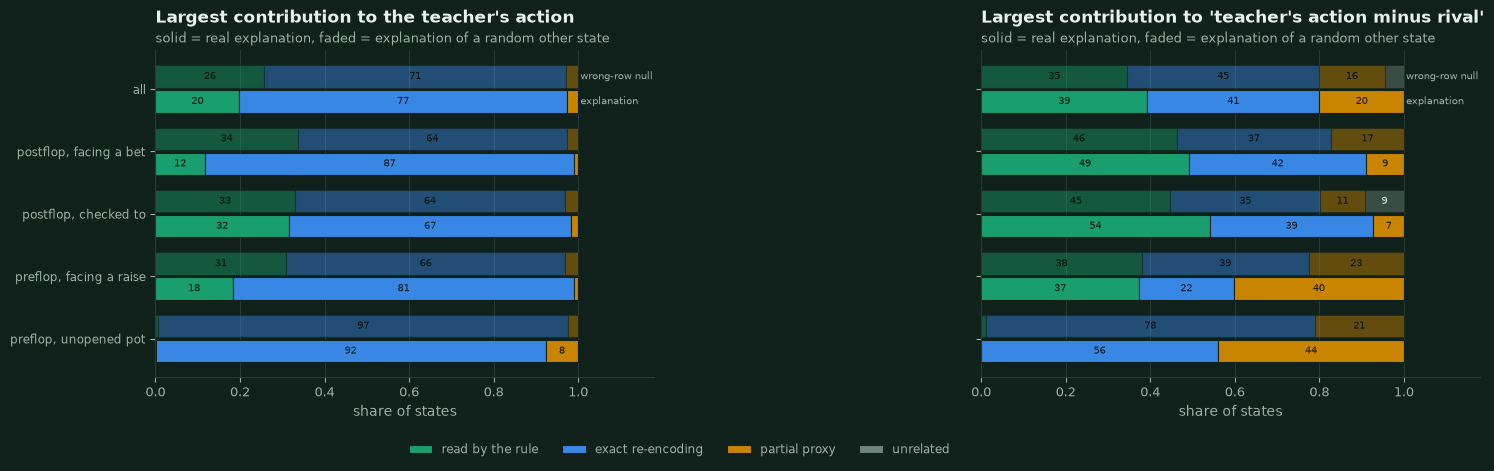

**Reading.** Over 20,000 validation states the largest-contribution term of the teacher's action involves a feature the deciding rule reads in 20% and an exact re-encoding of one in a further 77% (97% together); 3% fall on a partial proxy and 0% on a feature unrelated to the rule. **But the wrong-row null scores 97%**: the number cannot tell a genuine explanation from the explanation of an unrelated state, because the strongest term is almost always the hand-strength term (`equity` or its exact copy `equity_minus_pot_odds`) and nearly every rule reads equity. The test therefore shows that the explanations are *not wrong* - they rarely point at an irrelevant feature (0.0% unrelated) - but not that they are *specific*. The contrastive version is somewhat sharper (80% read-or-exact against a null of 80%), and deleting the top contrast term changes the EBM's own decision in 21% of the states against 1% for a random term, so the explanation does point at what the *model* uses. Because 'is the top term one of the rule's features?' is too easy to pass, the next test asks for the **decisive** features.

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15.0, 4.9), sharey=True)
colors = [nbp.ACCENT, nbp.SERIES[1], nbp.SERIES[4], "#6f847a"]
for ax, (title, actual, null) in zip(axes, (("Largest contribution to the teacher's action", tiers_actual, tiers_null), ("Largest contribution to 'teacher's action minus rival'", tiers_contrast, tiers_null_contrast))):
    labels = [*fam_names, "all"]
    ypos = np.arange(len(labels))
    for offset, data, name in ((-0.2, actual, "explanation"), (0.2, null, "wrong-row null")):
        left = np.zeros(len(labels))
        for k in range(4):
            share = np.array([tier_shares(data, fam_idx == f)[k] for f in range(len(fam_names))] + [tier_shares(data)[k]])
            ax.barh(ypos + offset, share, left=left, height=0.36, color=colors[k], alpha=1.0 if name == "explanation" else 0.45, edgecolor=nbp.SURFACE, linewidth=0.8, label=TIERS[k] if offset < 0 else None)
            for yi, (l, s) in enumerate(zip(left, share)):
                if s > 0.07:
                    ax.text(l + s / 2, yi + offset, f"{100 * s:.0f}", ha="center", va="center", fontsize=7, color="#06110c" if k < 3 else nbp.TEXT)
            left += share
        ax.text(1.005, ypos[-1] + offset, name, fontsize=7.5, color=nbp.MUTED, va="center")
    ax.set_yticks(ypos, labels, fontsize=8.5)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.18)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("share of states")
    nbp.title(ax, title, "solid = real explanation, faded = explanation of a random other state")
axes[0].legend(loc="upper center", bbox_to_anchor=(1.05, -0.17), ncols=4, fontsize=8.5)
fig.tight_layout()
nbp.savefig("nb01_explanation_fidelity", fig)
plt.show()
overall = fidelity.iloc[-1]
display(Markdown(
    f"**Reading.** Over {len(YF):,} validation states the largest-contribution term of the teacher's action involves a feature the deciding rule reads in {pct(tier_shares(tiers_actual)[0], 0)} and an exact re-encoding of one in a further {pct(tier_shares(tiers_actual)[1], 0)} "
    f"({pct(tier_shares(tiers_actual)[:2].sum(), 0)} together); {pct(tier_shares(tiers_actual)[2], 0)} fall on a partial proxy and {pct(tier_shares(tiers_actual)[3], 0)} on a feature unrelated to the rule. "
    f"**But the wrong-row null scores {pct(tier_shares(tiers_null)[:2].sum(), 0)}**: the number cannot tell a genuine explanation from the explanation of an unrelated state, because the strongest term is almost always the hand-strength term (`equity` or its exact copy `equity_minus_pot_odds`) "
    f"and nearly every rule reads equity. The test therefore shows that the explanations are *not wrong* - they rarely point at an irrelevant feature ({pct(tier_shares(tiers_actual)[3], 1)} unrelated) - but not that they are *specific*. "
    f"The contrastive version is somewhat sharper ({pct(tier_shares(tiers_contrast)[:2].sum(), 0)} read-or-exact against a null of {pct(tier_shares(tiers_null_contrast)[:2].sum(), 0)}), and deleting the top contrast term changes the EBM's own decision in {pct(float(np.mean(flip_top)), 0)} of the states against {pct(float(np.mean(flip_random)), 0)} for a random term, "
    f"so the explanation does point at what the *model* uses. Because 'is the top term one of the rule's features?' is too easy to pass, the next test asks for the **decisive** features."
))

**A harder test: are the *decisive* features recovered?** For every state we measure which features really decide the teacher's action: a feature is **decisive** in a state if moving it to a typical extreme (its 10th or 90th validation percentile; a binary flag is toggled), with the other 44 features unchanged,
changes the teacher's decision. This is a counterfactual, causal ground truth that the teacher's code makes exactly computable. Then we ask whether the EBM's explanation names those features among its `k` largest terms (a term counts as naming a feature through
the exact identities of section 3.4: `equity_minus_pot_odds` names `equity` and `pot_odds`, `pot_odds` and `bet_fraction_of_pot` name each other, and before the flop `equity` and `preflop_percentile` rank the same hands).
We report **precision@k** (share of the `k` terms that name a decisive feature), **recall** (share of the decisive features that some top-`k` term names), and the recall restricted to the **rule-specific** decisive features (everything except the backbone `equity`, `pot_odds`, `street`, `facing_bet`, `is_button`, `num_raises_street`),
each against a wrong-row null and against `k` uniformly random terms. Caveat: a contribution is *evidence relative to the average state*, whereas decisiveness is *sensitivity at the margin*; a feature that sits right on its threshold can be decisive with a small contribution, so perfect recall is not expected of any additive explanation.

In [31]:
def teacher_actions(X: np.ndarray, legal: np.ndarray) -> np.ndarray:
    return np.array([int(TEACHER.decide_features(X[i], legal[i]).action) for i in range(len(X))])


def ebm_actions(X: np.ndarray, legal: np.ndarray) -> np.ndarray:
    return masked_argmax(model_probabilities(MODEL, X), legal)


BACKBONE = {"equity", "equity_minus_pot_odds", "preflop_percentile", "pot_odds", "street", "facing_bet", "is_button", "num_raises_street"}
quantiles = {name: np.quantile(VAL.X[:, j], [0.10, 0.90]) for j, name in enumerate(FEATURE_NAMES)}
decisive_teacher = np.zeros((len(YF), NUM_FEATURES), bool)
decisive_ebm = np.zeros((len(YF), NUM_FEATURES), bool)  # plain: only the named column changes
decisive_ebm_coherent = np.zeros((len(YF), NUM_FEATURES), bool)  # equity / pot_odds moves also recompute equity_minus_pot_odds (an exact identity)
base_ebm_choice = ebm_actions(XF, LF)
EMP_COLUMN = FEATURE_INDEX["equity_minus_pot_odds"]
t0 = time.perf_counter()
for j, name in enumerate(FEATURE_NAMES):
    is_binary = set(np.unique(VAL.X[:, j])) <= {0.0, 1.0}
    for value in ([None] if is_binary else list(quantiles[name])):
        moved = XF.copy()
        moved[:, j] = 1.0 - XF[:, j] if value is None else value
        decisive_teacher[:, j] |= teacher_actions(moved, LF) != YF
        decisive_ebm[:, j] |= ebm_actions(moved, LF) != base_ebm_choice
        if name in ("equity", "pot_odds"):
            moved[:, EMP_COLUMN] = moved[:, FEATURE_INDEX["equity"]] - moved[:, FEATURE_INDEX["pot_odds"]]
        decisive_ebm_coherent[:, j] |= ebm_actions(moved, LF) != base_ebm_choice
cf_seconds = time.perf_counter() - t0
streets = XF[:, FEATURE_INDEX["street"]]


def names_of(term: int, street: float) -> set[str]:
    """Features a term 'names': its own plus exact re-encodings (section 3.4)."""
    out = set(TERM_FEATURES[term])
    if "equity_minus_pot_odds" in out:
        out |= {"equity", "pot_odds"}
    if out & {"pot_odds", "bet_fraction_of_pot"}:
        out |= {"pot_odds", "bet_fraction_of_pot"}
    if street == 0:
        if out & PREFLOP_CONSTANTS:
            out |= {"street"}
        if out & {"equity", "preflop_percentile"}:
            out |= {"equity", "preflop_percentile"}
        if out & {"spr", "effective_stack_bb"}:
            out |= {"spr", "effective_stack_bb"}
    return out


def recovery(top_terms: np.ndarray) -> dict[str, float]:
    precision, recall, spec_recall = [], [], []
    for i in range(len(YF)):
        decisive = {FEATURE_NAMES[j] for j in np.flatnonzero(decisive_teacher[i])}
        if not decisive:
            continue
        named = [names_of(t, streets[i]) for t in top_terms[i]]
        precision.append(np.mean([len(n & decisive) > 0 for n in named]))
        recall.append(len(set().union(*named) & decisive) / len(decisive))
        specific = decisive - BACKBONE
        if specific:
            spec_recall.append(len(set().union(*named) & specific) / len(specific))
    return {"precision@k": float(np.mean(precision)), "recall": float(np.mean(recall)), "rule-specific recall": float(np.mean(spec_recall)), "states with a rule-specific decisive feature": len(spec_recall)}


rank_actual = np.argsort(-np.abs(chosen_scores), axis=1)
rank_contrast = np.argsort(-np.abs(contrast_scores), axis=1)
uniform_rng = np.random.default_rng(DEMO_SEED + 6)
uniform_terms = np.stack([uniform_rng.permutation(len(TERM_NAMES)) for _ in range(len(YF))])
LABELS = {"act": "contributions to the teacher's action", "act_null": "same, wrong-row null", "con": "contrast with the best rival", "con_null": "same, wrong-row null (contrast)", "rand": "k random terms"}
recovery_rows = []
for k in (1, 3, 5):
    for key, ranking in (("act", rank_actual), ("act_null", rank_actual[null_perm]), ("con", rank_contrast), ("con_null", rank_contrast[null_perm]), ("rand", uniform_terms)):
        recovery_rows.append({"k": k, "explanation": LABELS[key], **recovery(ranking[:, :k])})
recovery_frame = pd.DataFrame(recovery_rows)
n_decisive_states = int(decisive_teacher.any(axis=1).sum())
flip_recall = float((decisive_teacher & decisive_ebm).sum() / decisive_teacher.sum())
flip_recall_coherent = float((decisive_teacher & decisive_ebm_coherent).sum() / decisive_teacher.sum())
flip_precision = float((decisive_teacher & decisive_ebm_coherent).sum() / decisive_ebm_coherent.sum())
sens = pd.DataFrame({"feature": [f"`{n}`" for n in FEATURE_NAMES], "teacher: decision changes": decisive_teacher.mean(axis=0), "EBM, plain move": decisive_ebm.mean(axis=0), "EBM, coherent move": decisive_ebm_coherent.mean(axis=0),
                     "EBM changes where the teacher changes (coherent)": [float((decisive_teacher[:, j] & decisive_ebm_coherent[:, j]).sum() / max(decisive_teacher[:, j].sum(), 1)) for j in range(NUM_FEATURES)]})
sens = sens[sens["teacher: decision changes"] >= 0.02].sort_values("teacher: decision changes", ascending=False)
display(Markdown(
    f"**[data]** Counterfactuals ({cf_seconds:.0f} s): {n_decisive_states:,} of {len(YF):,} states have at least one decisive feature for the teacher; on average {decisive_teacher.sum(axis=1).mean():.2f} of the 45 features are decisive per state (equity in {pct(decisive_teacher[:, FEATURE_INDEX['equity']].mean(), 0)} of the states, street {pct(decisive_teacher[:, FEATURE_INDEX['street']].mean(), 0)}, "
    f"opponent fold-to-bet {pct(decisive_teacher[:, FEATURE_INDEX['opp_fold_to_bet']].mean(), 0)}, flush draw {pct(decisive_teacher[:, FEATURE_INDEX['flush_draw']].mean(), 0)}). "
    f"**Behavioural check.** Of all (state, feature) counterfactuals that change the teacher's decision, the EBM's decision changes too in {pct(flip_recall, 0)} when only the named column is moved and in {pct(flip_recall_coherent, 0)} when `equity` and `pot_odds` moves also update their exact derivative `equity_minus_pot_odds`; "
    f"of the counterfactuals that change the EBM's decision (coherent), {pct(flip_precision, 0)} also change the teacher's. The gap between the two variants is redundancy at work: the EBM takes `equity_minus_pot_odds` (and, before the flop, `preflop_percentile`) as seriously as `equity`, "
    f"so moving one copy of an idea alone leaves it largely unmoved. The same holds for `street`, `facing_bet`, `num_raises_street`, `is_button` and `preflop_percentile` (table): the teacher reads them directly, the EBM presumably reads the same information from other columns "
    f"(board descriptors, the price of the call, commit fractions). A single-column edit is therefore an off-manifold probe on which the EBM and the teacher legitimately differ. Per feature (those that decide at least 2% of the teacher's decisions):"
))
display(md_table(sens, "{:.3f}"))
display(Markdown(
    "The question below is whether the EBM's *explanations* single out the features that decide - with the caveat that, for the same reason, a perfectly faithful explanation of the EBM may name a copy (`equity_minus_pot_odds`) where the teacher reads the original (`equity`); the matching of section 3.4's identities handles the two exact cases."
))
display(md_table(recovery_frame, "{:.3f}"))

**[data]** Counterfactuals (17 s): 19,941 of 20,000 states have at least one decisive feature for the teacher; on average 2.81 of the 45 features are decisive per state (equity in 76% of the states, street 56%, opponent fold-to-bet 6%, flush draw 8%). **Behavioural check.** Of all (state, feature) counterfactuals that change the teacher's decision, the EBM's decision changes too in 21% when only the named column is moved and in 42% when `equity` and `pot_odds` moves also update their exact derivative `equity_minus_pot_odds`; of the counterfactuals that change the EBM's decision (coherent), 31% also change the teacher's. The gap between the two variants is redundancy at work: the EBM takes `equity_minus_pot_odds` (and, before the flop, `preflop_percentile`) as seriously as `equity`, so moving one copy of an idea alone leaves it largely unmoved. The same holds for `street`, `facing_bet`, `num_raises_street`, `is_button` and `preflop_percentile` (table): the teacher reads them directly, the EBM presumably reads the same information from other columns (board descriptors, the price of the call, commit fractions). A single-column edit is therefore an off-manifold probe on which the EBM and the teacher legitimately differ. Per feature (those that decide at least 2% of the teacher's decisions):

| feature | teacher: decision changes | EBM, plain move | EBM, coherent move | EBM changes where the teacher changes (coherent) |
|---|---|---|---|---|
| `equity` | 0.756 | 0.422 | 0.988 | 0.995 |
| `street` | 0.558 | 0.052 | 0.052 | 0.069 |
| `preflop_percentile` | 0.310 | 0.025 | 0.025 | 0.052 |
| `facing_bet` | 0.300 | 0.076 | 0.076 | 0.155 |
| `num_raises_street` | 0.210 | 0.020 | 0.020 | 0.027 |
| `is_button` | 0.117 | 0.009 | 0.009 | 0.009 |
| `opp_pfr` | 0.087 | 0.008 | 0.008 | 0.017 |
| `pot_odds` | 0.087 | 0.040 | 0.366 | 0.949 |
| `opp_aggression` | 0.083 | 0.081 | 0.081 | 0.743 |
| `flush_draw` | 0.081 | 0.126 | 0.126 | 0.612 |
| `opp_fold_to_bet` | 0.064 | 0.037 | 0.037 | 0.377 |
| `bet_fraction_of_pot` | 0.046 | 0.056 | 0.056 | 0.695 |
| `board_straightness` | 0.038 | 0.068 | 0.068 | 0.551 |
| `board_max_suit_count` | 0.028 | 0.056 | 0.056 | 0.668 |
| `spr` | 0.021 | 0.134 | 0.134 | 0.456 |

The question below is whether the EBM's *explanations* single out the features that decide - with the caveat that, for the same reason, a perfectly faithful explanation of the EBM may name a copy (`equity_minus_pot_odds`) where the teacher reads the original (`equity`); the matching of section 3.4's identities handles the two exact cases.

| k | explanation | precision@k | recall | rule-specific recall | states with a rule-specific decisive feature |
|---|---|---|---|---|---|
| 1 | contributions to the teacher's action | 0.959 | 0.479 | 0.087 | 7156 |
| 1 | same, wrong-row null | 0.945 | 0.460 | 0.043 | 7156 |
| 1 | contrast with the best rival | 0.750 | 0.385 | 0.040 | 7156 |
| 1 | same, wrong-row null (contrast) | 0.745 | 0.357 | 0.028 | 7156 |
| 1 | k random terms | 0.286 | 0.132 | 0.074 | 7156 |
| 3 | contributions to the teacher's action | 0.660 | 0.513 | 0.105 | 7156 |
| 3 | same, wrong-row null | 0.670 | 0.520 | 0.090 | 7156 |
| 3 | contrast with the best rival | 0.659 | 0.537 | 0.140 | 7156 |
| 3 | same, wrong-row null (contrast) | 0.638 | 0.512 | 0.104 | 7156 |
| 3 | k random terms | 0.289 | 0.332 | 0.202 | 7156 |
| 5 | contributions to the teacher's action | 0.530 | 0.571 | 0.184 | 7156 |
| 5 | same, wrong-row null | 0.516 | 0.587 | 0.158 | 7156 |
| 5 | contrast with the best rival | 0.602 | 0.604 | 0.292 | 7156 |
| 5 | same, wrong-row null (contrast) | 0.572 | 0.590 | 0.198 | 7156 |
| 5 | k random terms | 0.289 | 0.462 | 0.289 | 7156 |

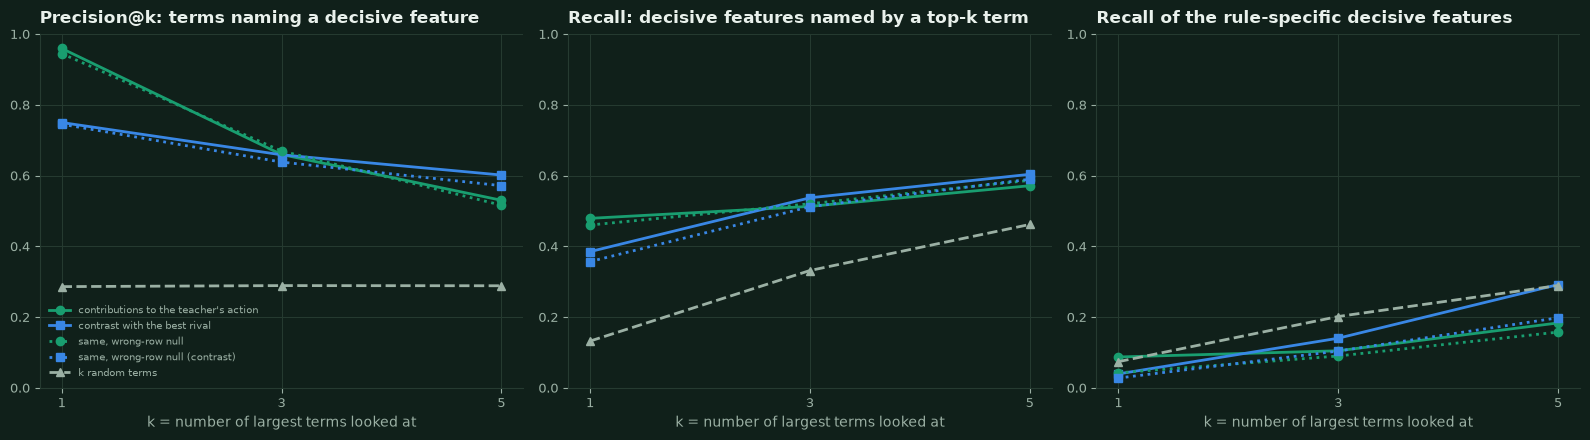

**Reading.** With the three largest contributions, 66% of the terms name a decisive feature (wrong-row null 67%, random terms 29%): far better than random terms, but equal to the explanation of an *unrelated* state - hand strength is decisive almost everywhere and dominates every explanation. For the **rule-specific** decisive features (opponent folds, draws, board texture, bet-size penalty, ...; 7,156 states) the top-5 contributions recover 18% of them (wrong-row null 16%; worse than 29% for five random terms) and the top-5 *contrast* terms 29% (null 20%; no better than random terms). So the EBM's contribution explanations are exact descriptions of the *model*, but a window onto the *teacher's* reasons only for the dominant ingredient: they say 'hand strength and situation' reliably and rarely single out the secondary, rule-specific feature that tips the decision - there, a counterfactual (sensitivity) analysis such as the one just run is the better tool than reading the largest contributions. The contrastive view is the more informative of the two.

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.5))
styles = {LABELS["act"]: (nbp.ACCENT, "-", "o"), LABELS["con"]: (nbp.SERIES[1], "-", "s"), LABELS["act_null"]: (nbp.ACCENT, ":", "o"), LABELS["con_null"]: (nbp.SERIES[1], ":", "s"), LABELS["rand"]: (nbp.MUTED, "--", "^")}
for ax, column, title in zip(axes, ("precision@k", "recall", "rule-specific recall"), ("Precision@k: terms naming a decisive feature", "Recall: decisive features named by a top-k term", "Recall of the rule-specific decisive features")):
    for label, (color, line, marker) in styles.items():
        part = recovery_frame[recovery_frame["explanation"] == label]
        ax.plot(part["k"], part[column], line, marker=marker, color=color, label=label)
    ax.set_xticks([1, 3, 5])
    ax.set_xlabel("k = number of largest terms looked at")
    ax.set_ylim(0, 1.0)
    nbp.title(ax, title)
axes[0].legend(loc="lower left", fontsize=7.5)
fig.tight_layout()
nbp.savefig("nb01_explanation_recovery", fig)
plt.show()
rec = lambda k, key, col: float(recovery_frame[(recovery_frame["k"] == k) & (recovery_frame["explanation"] == LABELS[key])][col].iloc[0])  # noqa: E731
spec_act, spec_con, spec_rand = rec(5, "act", "rule-specific recall"), rec(5, "con", "rule-specific recall"), rec(5, "rand", "rule-specific recall")
better_than_random = lambda value: "better than" if value > spec_rand + 0.02 else ("no better than" if value > spec_rand - 0.02 else "worse than")  # noqa: E731
display(Markdown(
    f"**Reading.** With the three largest contributions, {pct(rec(3, 'act', 'precision@k'), 0)} of the terms name a decisive feature (wrong-row null {pct(rec(3, 'act_null', 'precision@k'), 0)}, random terms {pct(rec(3, 'rand', 'precision@k'), 0)}): "
    f"far better than random terms, but equal to the explanation of an *unrelated* state - hand strength is decisive almost everywhere and dominates every explanation. "
    f"For the **rule-specific** decisive features (opponent folds, draws, board texture, bet-size penalty, ...; {int(recovery_frame['states with a rule-specific decisive feature'].iloc[0]):,} states) the top-5 contributions recover {pct(spec_act, 0)} of them (wrong-row null {pct(rec(5, 'act_null', 'rule-specific recall'), 0)}; "
    f"{better_than_random(spec_act)} {pct(spec_rand, 0)} for five random terms) and the top-5 *contrast* terms {pct(spec_con, 0)} (null {pct(rec(5, 'con_null', 'rule-specific recall'), 0)}; {better_than_random(spec_con)} random terms). "
    f"So the EBM's contribution explanations are exact descriptions of the *model*, but a window onto the *teacher's* reasons only for the dominant ingredient: they say 'hand strength and situation' reliably and rarely single out the secondary, rule-specific feature that tips the decision "
    f"- there, a counterfactual (sensitivity) analysis such as the one just run is the better tool than reading the largest contributions. The contrastive view is the more informative of the two."
))

## 8. What the EBM actually learned

Section 7 asked whether single explanations are faithful. Here we compare the *whole learned function* with the teacher's parameters: where are its decision boundaries, does it adapt to the opponent the way the teacher does,
and which features that the teacher never consults does it use anyway?

### 8.1 Learned decision boundaries against the teacher's thresholds `[data]`

The teacher's thresholds are known numbers (`TeacherParams`), so a learned boundary can be *measured*: in a family of real validation states we find, for each model, the value of the deciding quantity at which the share of "action X" crosses one half
(a local window average, so no model of the boundary is assumed). We compare three things: the teacher's exact boundary (its function evaluated on a template state), the teacher's *empirical* boundary on the same data (what a perfect copy would show), and the EBM's.
Sections: (a) the value-bet line against the opponent's fold-to-bet rate, (b) the call/fold line against the opponent's aggression, (c) the preflop percentile ladder, (d) jumps of the shape functions against the thresholds.

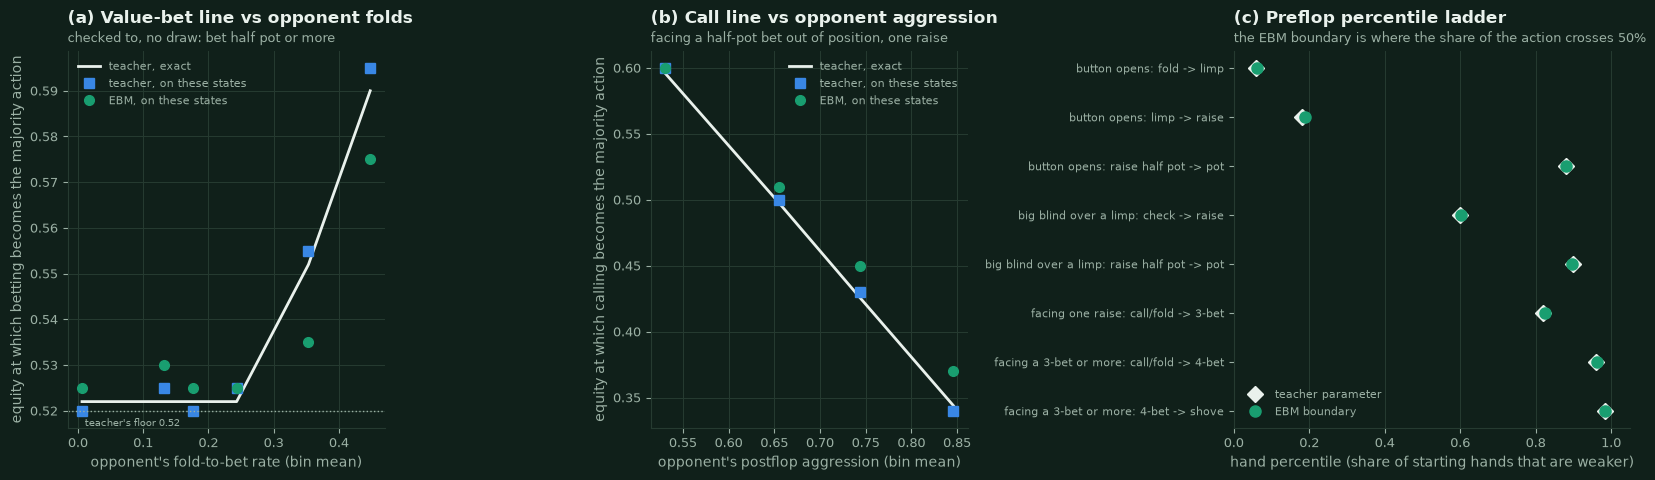

**(a)** Value-bet line against the opponent's fold-to-bet rate (equity at which half of the states get a bet; the teacher clips its line at the floor; 'exact' evaluates the teacher's function on one template state):

| fold-to-bet bin | states | mean fold-to-bet | teacher (exact function) | teacher (empirical) | EBM (empirical) |
|---|---|---|---|---|---|
| 0.00-0.05 | 6206 | 0.006 | 0.522 | 0.520 | 0.525 |
| 0.10-0.15 | 986 | 0.133 | 0.522 | 0.525 | 0.530 |
| 0.15-0.20 | 796 | 0.177 | 0.522 | 0.520 | 0.525 |
| 0.20-0.30 | 2297 | 0.243 | 0.522 | 0.525 | 0.525 |
| 0.30-0.40 | 1576 | 0.353 | 0.552 | 0.555 | 0.535 |
| 0.40-0.60 | 2629 | 0.448 | 0.590 | 0.595 | 0.575 |

**(b)** Call/fold line against the opponent's aggression (equity at which half of the states get called):

| aggression bin | states | mean aggression | teacher (exact function) | teacher (empirical) | EBM (empirical) |
|---|---|---|---|---|---|
| 0.4-0.6 | 345 | 0.531 | 0.596 | 0.600 | 0.600 |
| 0.6-0.7 | 219 | 0.655 | 0.498 | 0.500 | 0.510 |
| 0.7-0.8 | 339 | 0.743 | 0.426 | 0.430 | 0.450 |
| 0.8-0.9 | 537 | 0.846 | 0.344 | 0.340 | 0.370 |

**(c)** Preflop ladder (percentile at which the share of the named action crosses 50%):

| threshold | parameter | teacher value | states | teacher (empirical) | EBM (empirical) | EBM minus teacher value |
|---|---|---|---|---|---|---|
| button opens: fold -> limp | `limp_pct` | 0.060 | 11438 | 0.062 | 0.062 | 0.003 |
| button opens: limp -> raise | `open_pct` | 0.180 | 11438 | 0.188 | 0.188 | 0.008 |
| button opens: raise half pot -> pot | `open_pot_pct` | 0.880 | 11438 | 0.880 | 0.880 | 0.000 |
| big blind over a limp: check -> raise | `iso_pct` | 0.600 | 4326 | 0.603 | 0.603 | 0.003 |
| big blind over a limp: raise half pot -> pot | `iso_pot_pct` | 0.900 | 4326 | 0.897 | 0.895 | -0.005 |
| facing one raise: call/fold -> 3-bet | `threebet_pct` | 0.820 | 7013 | 0.825 | 0.825 | 0.005 |
| facing a 3-bet or more: call/fold -> 4-bet | `fourbet_pct` | 0.960 | 3092 | 0.960 | 0.963 | 0.003 |
| facing a 3-bet or more: 4-bet -> shove | `shove_pct` | 0.985 | 3092 | 0.985 | 0.985 | 0.000 |

**Reading.** (a) With calm opponents the teacher's value line sits at its floor (0.52) and the EBM's boundary at 0.525; for opponents that fold more than about 30% of the time the line rises, with a slope of 0.40 equity per unit of fold rate for the teacher (its parameter `value_fold_slope` = 0.4) and 0.42 for the EBM on the same states. Against the teacher's boundary on the same states the EBM is between -0.020 and +0.005 equity points (largest absolute gap 0.020): it reproduces the floor and the direction and size of the slide; in the two highest-fold bins its line is on average 0.020 equity points below the teacher's (it adapts slightly less than the teacher). (b) The teacher's call line falls by 0.80 equity per unit of opponent aggression (`aggression_slope` = 0.8: an aggressive opponent bets with weaker hands, so the call line is lowered); the EBM's slope is -0.72, largest gap 0.030. (c) Of the 8 preflop thresholds the EBM boundary lies within 0.003 percentile points of the teacher's parameter on average (largest 0.008; the grid step is 0.0025). Short-stack push-or-fold states are too rare in the validation data (77 states, 0.10%) to place a boundary; the EBM agrees with the teacher on 86% of them.

In [33]:
def local_crossing(x: np.ndarray, indicator: np.ndarray, low: float, high: float, step: float, half_window: float, min_n: int = 8) -> float:
    """Smallest grid value at which the local share of ``indicator`` (window average) reaches one half; NaN if it never does."""
    for g in np.arange(low, high + 1e-9, step):
        inside = np.abs(x - g) < half_window
        if inside.sum() >= min_n and indicator[inside].mean() >= 0.5:
            return float(g)
    return float("nan")


def teacher_boundary(template: np.ndarray, mask: np.ndarray, updates: dict, grid: np.ndarray, predicate) -> float:
    """Smallest equity of ``grid`` at which the teacher's decision satisfies ``predicate`` with the other features of ``template`` fixed."""
    for g in grid:
        x = template.copy()
        x[FEATURE_INDEX["equity"]] = g
        for name, value in updates.items():
            x[FEATURE_INDEX[name]] = value
        if predicate(int(TEACHER.decide_features(x, mask).action)):
            return float(g)
    return float("nan")


F = VAL_FRAME
TEACHER_ACTION = VAL.y
EBM_ACTION = VAL_PRED
equity_grid = np.arange(0.30, 0.97, 0.002)

# (a) value-bet line vs opponent fold-to-bet: checked-to postflop states, no draw, no initiative (so no semi-bluff / c-bet rule can fire)
sel_a = ((F.street > 0) & (F.facing_bet == 0) & (F.can_raise == 1) & (F.flush_draw == 0) & (F.straight_outs < 8) & (F.i_have_initiative == 0)).to_numpy()
template_a = VAL.X[sel_a][0]
mask_a = VAL.legal[sel_a][0]
fold_edges = [0.0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.60]
rows_a = []
for lo_f, hi_f in zip(fold_edges[:-1], fold_edges[1:]):
    m = sel_a & (F.opp_fold_to_bet >= lo_f).to_numpy() & (F.opp_fold_to_bet < hi_f).to_numpy()
    if m.sum() < 300:
        continue
    mean_fold = float(F.opp_fold_to_bet[m].mean())
    rows_a.append({
        "fold-to-bet bin": f"{lo_f:.2f}-{hi_f:.2f}", "states": int(m.sum()), "mean fold-to-bet": mean_fold,
        "teacher (exact function)": teacher_boundary(template_a, mask_a, {"opp_fold_to_bet": mean_fold}, equity_grid, lambda a: a >= 2),
        "teacher (empirical)": local_crossing(F.equity.to_numpy()[m], TEACHER_ACTION[m] >= 2, 0.40, 0.95, 0.005, 0.015),
        "EBM (empirical)": local_crossing(F.equity.to_numpy()[m], EBM_ACTION[m] >= 2, 0.40, 0.95, 0.005, 0.015),
    })
value_table = pd.DataFrame(rows_a)
clamped = value_table["teacher (exact function)"] <= MIN_VALUE_THRESHOLD + 0.004
above = ~clamped
slope = lambda col: float(np.polyfit(value_table.loc[above, "mean fold-to-bet"], value_table.loc[above, col], 1)[0]) if above.sum() >= 2 else float("nan")  # noqa: E731

# (b) call/fold line vs opponent aggression: facing a half-pot bet out of position, no draw, one raise so far
sel_b = ((F.street > 0) & (F.facing_bet == 1) & (F.flush_draw == 0) & (F.straight_outs < 8) & (F.num_raises_street == 1) & (F.effective_stack_bb > 20)
         & (F.is_button == 0) & F.bet_fraction_of_pot.between(0.4, 0.6)).to_numpy()
template_b = VAL.X[sel_b][0]
mask_b = VAL.legal[sel_b][0]
agg_edges = [0.4, 0.6, 0.7, 0.8, 0.9, 1.0]
rows_b = []
for lo_a, hi_a in zip(agg_edges[:-1], agg_edges[1:]):
    m = sel_b & (F.opp_aggression >= lo_a).to_numpy() & (F.opp_aggression < hi_a).to_numpy()
    if m.sum() < 100:
        continue
    mean_agg = float(F.opp_aggression[m].mean())
    rows_b.append({
        "aggression bin": f"{lo_a:.1f}-{hi_a:.1f}", "states": int(m.sum()), "mean aggression": mean_agg,
        "teacher (exact function)": teacher_boundary(template_b, mask_b, {"opp_aggression": mean_agg}, np.arange(0.10, 0.97, 0.002), lambda a: a != 0),
        "teacher (empirical)": local_crossing(F.equity.to_numpy()[m], TEACHER_ACTION[m] != 0, 0.10, 0.95, 0.005, 0.02),
        "EBM (empirical)": local_crossing(F.equity.to_numpy()[m], EBM_ACTION[m] != 0, 0.10, 0.95, 0.005, 0.02),
    })
call_table = pd.DataFrame(rows_b)
call_slope = lambda col: float(np.polyfit(call_table["mean aggression"], call_table[col], 1)[0])  # noqa: E731

# (c) preflop percentile ladder
P = CANONICAL_PARAMS
pre = F.street == 0
stack = (F.effective_stack_bb + F.to_call_bb)
ladder_defs = [
    ("button opens: fold -> limp", "limp_pct", P.limp_pct, pre & (F.is_button == 1) & (F.num_raises_street == 0) & (stack > P.push_fold_bb), lambda a: a != 0),
    ("button opens: limp -> raise", "open_pct", P.open_pct, pre & (F.is_button == 1) & (F.num_raises_street == 0) & (stack > P.push_fold_bb), lambda a: a >= 2),
    ("button opens: raise half pot -> pot", "open_pot_pct", P.open_pot_pct, pre & (F.is_button == 1) & (F.num_raises_street == 0) & (stack > P.push_fold_bb), lambda a: a == 3),
    ("big blind over a limp: check -> raise", "iso_pct", P.iso_pct, pre & (F.is_button == 0) & (F.num_raises_street == 0) & (stack > P.push_fold_bb), lambda a: a >= 2),
    ("big blind over a limp: raise half pot -> pot", "iso_pot_pct", P.iso_pot_pct, pre & (F.is_button == 0) & (F.num_raises_street == 0) & (stack > P.push_fold_bb), lambda a: a == 3),
    ("facing one raise: call/fold -> 3-bet", "threebet_pct", P.threebet_pct, pre & (F.num_raises_street == 1), lambda a: a >= 2),
    ("facing a 3-bet or more: call/fold -> 4-bet", "fourbet_pct", P.fourbet_pct, pre & (F.num_raises_street >= 2), lambda a: a >= 3),
    ("facing a 3-bet or more: 4-bet -> shove", "shove_pct", P.shove_pct, pre & (F.num_raises_street >= 2), lambda a: a == 4),
]
ladder_rows = []
for label, param, value, selector, predicate in ladder_defs:
    m = selector.to_numpy()
    pc = F.preflop_percentile.to_numpy()[m]
    t_ind = np.array([predicate(a) for a in TEACHER_ACTION[m]])
    e_ind = np.array([predicate(a) for a in EBM_ACTION[m]])
    ladder_rows.append({"threshold": label, "parameter": f"`{param}`", "teacher value": value, "states": int(m.sum()),
                        "teacher (empirical)": local_crossing(pc, t_ind, 0.0, 1.0, 0.0025, 0.0075, min_n=4), "EBM (empirical)": local_crossing(pc, e_ind, 0.0, 1.0, 0.0025, 0.0075, min_n=4)})
ladder = pd.DataFrame(ladder_rows)
ladder["EBM minus teacher value"] = ladder["EBM (empirical)"] - ladder["teacher value"]

# short-stack push/fold states are rare: report the agreement instead of a boundary
push_mask = np.isin(RULES, ["pre_push", "pre_fold_short"])
push_agree = float((EBM_ACTION[push_mask] == TEACHER_ACTION[push_mask]).mean())

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.9), gridspec_kw={"width_ratios": [1.0, 1.0, 1.25]})
ax = axes[0]
ax.plot(value_table["mean fold-to-bet"], value_table["teacher (exact function)"], "-", color=nbp.TEXT, linewidth=2, label="teacher, exact")
ax.plot(value_table["mean fold-to-bet"], value_table["teacher (empirical)"], "s", color=nbp.SERIES[1], markersize=7, label="teacher, on these states")
ax.plot(value_table["mean fold-to-bet"], value_table["EBM (empirical)"], "o", color=nbp.ACCENT, markersize=7, label="EBM, on these states")
ax.axhline(MIN_VALUE_THRESHOLD, color=nbp.MUTED, linestyle=":", linewidth=1)
ax.annotate(f"teacher's floor {MIN_VALUE_THRESHOLD}", (value_table["mean fold-to-bet"].min(), MIN_VALUE_THRESHOLD), xytext=(2, -11), textcoords="offset points", fontsize=7.5, color=nbp.MUTED)
ax.set_xlabel("opponent's fold-to-bet rate (bin mean)")
ax.set_ylabel("equity at which betting becomes the majority action")
ax.legend(loc="upper left", fontsize=8)
nbp.title(ax, "(a) Value-bet line vs opponent folds", "checked to, no draw: bet half pot or more")
ax = axes[1]
ax.plot(call_table["mean aggression"], call_table["teacher (exact function)"], "-", color=nbp.TEXT, linewidth=2, label="teacher, exact")
ax.plot(call_table["mean aggression"], call_table["teacher (empirical)"], "s", color=nbp.SERIES[1], markersize=7, label="teacher, on these states")
ax.plot(call_table["mean aggression"], call_table["EBM (empirical)"], "o", color=nbp.ACCENT, markersize=7, label="EBM, on these states")
ax.set_xlabel("opponent's postflop aggression (bin mean)")
ax.set_ylabel("equity at which calling becomes the majority action")
ax.legend(loc="upper right", fontsize=8)
nbp.title(ax, "(b) Call line vs opponent aggression", "facing a half-pot bet out of position, one raise")
ax = axes[2]
ypos = np.arange(len(ladder))[::-1]
ax.hlines(ypos, ladder["teacher value"], ladder["EBM (empirical)"], color=nbp.MUTED, linewidth=1.2)
ax.plot(ladder["teacher value"], ypos, "D", color=nbp.TEXT, markersize=8, label="teacher parameter")
ax.plot(ladder["EBM (empirical)"], ypos, "o", color=nbp.ACCENT, markersize=8, label="EBM boundary")
ax.set_yticks(ypos, ladder["threshold"], fontsize=8)
ax.set_xlabel("hand percentile (share of starting hands that are weaker)")
ax.set_xlim(0, 1.05)
ax.legend(loc="lower left", fontsize=8)
ax.grid(axis="y", visible=False)
nbp.title(ax, "(c) Preflop percentile ladder", "the EBM boundary is where the share of the action crosses 50%")
fig.tight_layout()
nbp.savefig("nb01_learned_thresholds", fig)
plt.show()
display(Markdown("**(a)** Value-bet line against the opponent's fold-to-bet rate (equity at which half of the states get a bet; the teacher clips its line at the floor; 'exact' evaluates the teacher's function on one template state):"))
display(md_table(value_table, "{:.3f}"))
display(Markdown("**(b)** Call/fold line against the opponent's aggression (equity at which half of the states get called):"))
display(md_table(call_table, "{:.3f}"))
display(Markdown("**(c)** Preflop ladder (percentile at which the share of the named action crosses 50%):"))
display(md_table(ladder, "{:.3f}"))
max_ladder_gap = float(ladder["EBM minus teacher value"].abs().max())
mean_ladder_gap = float(ladder["EBM minus teacher value"].abs().mean())
value_gap = float((value_table["EBM (empirical)"] - value_table["teacher (empirical)"]).abs().max())
call_gap = float((call_table["EBM (empirical)"] - call_table["teacher (empirical)"]).abs().max())
gap_high = float((value_table["EBM (empirical)"] - value_table["teacher (empirical)"]).iloc[-2:].mean())
display(Markdown(
    f"**Reading.** (a) With calm opponents the teacher's value line sits at its floor ({MIN_VALUE_THRESHOLD}) and the EBM's boundary at {value_table['EBM (empirical)'].iloc[0]:.3f}; for opponents that fold more than about 30% of the time the line rises, "
    f"with a slope of {slope('teacher (exact function)'):.2f} equity per unit of fold rate for the teacher (its parameter `value_fold_slope` = {P.value_fold_slope}) and {slope('EBM (empirical)'):.2f} for the EBM on the same states. "
    f"Against the teacher's boundary on the same states the EBM is between {(value_table['EBM (empirical)'] - value_table['teacher (empirical)']).min():+.3f} and {(value_table['EBM (empirical)'] - value_table['teacher (empirical)']).max():+.3f} equity points "
    f"(largest absolute gap {value_gap:.3f}): it reproduces the floor and the direction and size of the slide; in the two highest-fold bins its line is on average {abs(gap_high):.3f} equity points {'below' if gap_high < 0 else 'above'} the teacher's "
    f"(it adapts {'slightly less' if gap_high < 0 else 'slightly more'} than the teacher). "
    f"(b) The teacher's call line falls by {abs(call_slope('teacher (exact function)')):.2f} equity per unit of opponent aggression (`aggression_slope` = {P.aggression_slope}: an aggressive opponent bets with weaker hands, so the call line is lowered); the EBM's slope is {call_slope('EBM (empirical)'):.2f}, largest gap {call_gap:.3f}. "
    f"(c) Of the {len(ladder)} preflop thresholds the EBM boundary lies within {mean_ladder_gap:.3f} percentile points of the teacher's parameter on average (largest {max_ladder_gap:.3f}; the grid step is 0.0025). "
    f"Short-stack push-or-fold states are too rare in the validation data ({int(push_mask.sum())} states, {pct(push_mask.mean(), 2)}) to place a boundary; the EBM agrees with the teacher on {pct(push_agree, 0)} of them."
))

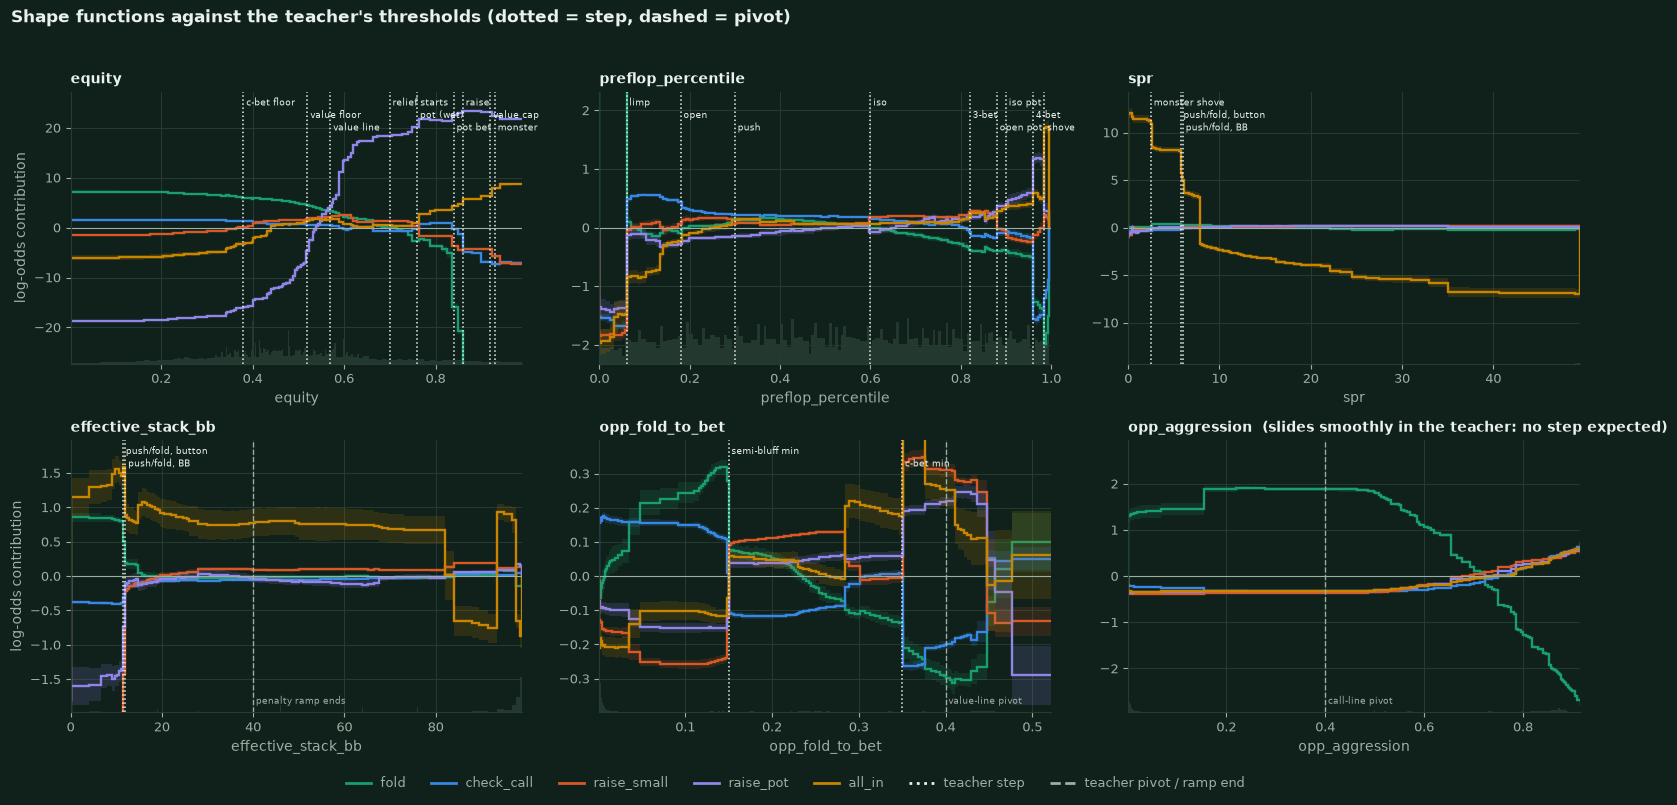

**(d)** The five largest steps of each shape function (largest change of any action's score between neighbouring bins) and the nearest teacher threshold of that feature (`within one bin` = closer than the width of the bin it jumps into):

| feature | jump at | size (log-odds) | action | nearest teacher threshold | distance | within one bin |
|---|---|---|---|---|---|---|
| `equity` | 0.836 | 10.844 | fold | pot bet (0.84) | 0.004 | True |
| `equity` | 0.861 | 7.074 | fold | raise (0.86) | 0.001 | True |
| `equity` | 0.849 | 4.888 | fold | pot bet (0.84) | 0.009 | True |
| `equity` | 0.589 | 4.591 | raise_pot | value line (0.57) | 0.019 | False |
| `equity` | 0.923 | 3.852 | fold | value cap (0.92) | 0.003 | True |
| `preflop_percentile` | 0.062 | 3.183 | fold | limp (0.06) | 0.002 | True |
| `preflop_percentile` | 0.960 | 1.380 | check_call | 4-bet (0.96) | 0.000 | True |
| `preflop_percentile` | 0.984 | 1.202 | all_in | shove (0.985) | 0.001 | True |
| `preflop_percentile` | 0.032 | 0.336 | all_in | limp (0.06) | 0.028 | False |
| `preflop_percentile` | 0.993 | 0.280 | fold | shove (0.985) | 0.008 | False |
| `spr` | 7.842 | 4.982 | all_in | push/fold, BB (6) | 1.842 | False |
| `spr` | 2.621 | 2.480 | all_in | monster shove (2.5) | 0.121 | False |
| `spr` | 5.754 | 1.875 | all_in | push/fold, button (5.75) | 0.004 | True |
| `spr` | 6.131 | 1.268 | all_in | push/fold, BB (6) | 0.131 | True |
| `spr` | 35.025 | 0.986 | all_in | push/fold, BB (6) | 29.025 | False |
| `effective_stack_bb` | 93.400 | 1.695 | all_in | push/fold, BB (12) | 81.400 | False |
| `effective_stack_bb` | 97.500 | 1.468 | all_in | push/fold, BB (12) | 85.500 | False |
| `effective_stack_bb` | 11.950 | 1.211 | raise_small | push/fold, BB (12) | 0.050 | True |
| `effective_stack_bb` | 11.450 | 0.683 | raise_small | push/fold, button (11.5) | 0.050 | True |
| `effective_stack_bb` | 82.050 | 0.657 | all_in | push/fold, BB (12) | 70.050 | False |
| `opp_fold_to_bet` | 0.448 | 0.356 | raise_small | c-bet min (0.35) | 0.098 | False |
| `opp_fold_to_bet` | 0.351 | 0.342 | all_in | c-bet min (0.35) | 0.001 | True |
| `opp_fold_to_bet` | 0.476 | 0.244 | raise_pot | c-bet min (0.35) | 0.126 | True |
| `opp_fold_to_bet` | 0.284 | 0.214 | all_in | c-bet min (0.35) | 0.066 | False |
| `opp_fold_to_bet` | 0.377 | 0.212 | all_in | c-bet min (0.35) | 0.027 | False |

**Reading.** 52% of the 25 largest steps lie within one bin of a teacher threshold of their own feature (`effective_stack_bb` 40%, `equity` 80%, `opp_fold_to_bet` 40%, `preflop_percentile` 60%, `spr` 40%). For the steps that do not match this analysis offers no explanation; plausible reasons (not tested) are that a shape function is one additive term among several that carry the same information (redundant copies and pair terms), or fine structure in sparsely populated tails. `opp_aggression` has no steps to match: the teacher slides smoothly with it. SPR and stack-depth steps are matched against the push/fold line converted into those features (footnote in the code).

In [34]:
# STEPS are genuine thresholds of the teacher (a decision changes there); PIVOTS are points around which it slides smoothly or a ramp ends (no step is expected).
# The unopened-pot push/fold line is expressed in the features: stack_bb = effective_stack_bb + to_call_bb <= push_fold_bb, with to_call = 0.5 bb for the button
# (effective <= 11.5) and 0 for the big blind (effective <= 12); spr = effective / (pot + to_call) = effective / 2 bb in an unopened pot (spr <= 5.75 / 6.0).
STEPS = {
    "equity": {"c-bet floor": P.cbet_min_equity, "value floor": MIN_VALUE_THRESHOLD, "value line": P.value_equity, "relief starts": P.penalty_relief_equity, "pot (wet)": P.wet_pot_equity,
               "pot bet": P.pot_bet_equity, "raise": P.raise_equity, "value cap": MAX_VALUE_THRESHOLD, "monster": P.monster_equity},
    "preflop_percentile": {"limp": P.limp_pct, "open": P.open_pct, "push": P.push_pct, "iso": P.iso_pct, "3-bet": P.threebet_pct, "open pot": P.open_pot_pct, "iso pot": P.iso_pot_pct, "4-bet": P.fourbet_pct, "shove": P.shove_pct},
    "spr": {"monster shove": P.shove_spr, "push/fold, button": (P.push_fold_bb - 0.5) / 2, "push/fold, BB": P.push_fold_bb / 2},
    "effective_stack_bb": {"push/fold, button": P.push_fold_bb - 0.5, "push/fold, BB": P.push_fold_bb},
    "opp_fold_to_bet": {"semi-bluff min": P.semi_bluff_min_fold, "c-bet min": P.cbet_min_fold},
    "opp_aggression": {},
}
PIVOTS = {"effective_stack_bb": {"penalty ramp ends": P.deep_stack_bb}, "opp_fold_to_bet": {"value-line pivot": FOLD_TO_BET_NEUTRAL}, "opp_aggression": {"call-line pivot": AGGRESSION_NEUTRAL}}
fig, axes = plt.subplots(2, 3, figsize=(16.0, 8.0))
jump_rows = []
for ax, (feature, thresholds) in zip(axes.ravel(), STEPS.items()):
    values = F[feature].to_numpy()
    xlim = (float(values.min()), min(float(np.quantile(values, 0.997)), 100.0)) if feature != "preflop_percentile" else (0.0, 1.0)
    frame = draw_shape(ax, feature, xlim=xlim)
    for k, (name, value) in enumerate(thresholds.items()):
        ax.axvline(value, color=nbp.TEXT, linestyle=":", linewidth=1.1)
        ax.annotate(name, (value, ax.get_ylim()[1]), xytext=(2, -10 - 9 * (k % 3)), textcoords="offset points", fontsize=6.8, color=nbp.TEXT)
    for k, (name, value) in enumerate(PIVOTS.get(feature, {}).items()):
        ax.axvline(value, color=nbp.MUTED, linestyle="--", linewidth=1.0)
        ax.annotate(name, (value, ax.get_ylim()[0]), xytext=(2, 6 + 9 * k), textcoords="offset points", fontsize=6.8, color=nbp.MUTED)
    ax.set_title(feature + ("  (slides smoothly in the teacher: no step expected)" if not thresholds else ""), loc="left", fontsize=10)
    if not thresholds:
        continue
    scores = frame[ACTIONS].to_numpy()
    delta = np.abs(np.diff(scores, axis=0)).max(axis=1)  # largest change across actions between neighbouring bins
    for rank_idx in np.argsort(-delta)[:5]:
        edge = float(frame["high"].iloc[rank_idx])
        width = float(frame["high"].iloc[rank_idx + 1] - frame["low"].iloc[rank_idx + 1])
        nearest_name, nearest_value = min(thresholds.items(), key=lambda kv: abs(kv[1] - edge))
        jump_rows.append({"feature": f"`{feature}`", "jump at": edge, "size (log-odds)": float(delta[rank_idx]), "action": ACTIONS[int(np.abs(scores[rank_idx + 1] - scores[rank_idx]).argmax())],
                          "nearest teacher threshold": f"{nearest_name} ({nearest_value:g})", "distance": abs(nearest_value - edge), "within one bin": abs(nearest_value - edge) <= width + 1e-9})
for ax in axes[:, 0]:
    ax.set_ylabel("log-odds contribution")
handles = [plt.Line2D([0], [0], color=ACTION_COLORS[a], linewidth=2) for a in ACTIONS] + [plt.Line2D([0], [0], color=nbp.TEXT, linestyle=":"), plt.Line2D([0], [0], color=nbp.MUTED, linestyle="--")]
fig.legend(handles, [*ACTIONS, "teacher step", "teacher pivot / ramp end"], loc="lower center", ncols=7, fontsize=9, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Shape functions against the teacher's thresholds (dotted = step, dashed = pivot)", x=0.01, ha="left", fontsize=12, fontweight="bold", color=nbp.TEXT)
fig.tight_layout(rect=(0, 0.03, 1, 0.96))
nbp.savefig("nb01_shapes_vs_teacher", fig)
plt.show()
jumps = pd.DataFrame(jump_rows)
display(Markdown("**(d)** The five largest steps of each shape function (largest change of any action's score between neighbouring bins) and the nearest teacher threshold of that feature (`within one bin` = closer than the width of the bin it jumps into):"))
display(md_table(jumps, "{:.3f}"))
close_share = float(jumps["within one bin"].mean())
by_feature_close = jumps.groupby("feature")["within one bin"].mean()
display(Markdown(
    f"**Reading.** {pct(close_share, 0)} of the {len(jumps)} largest steps lie within one bin of a teacher threshold of their own feature ("
    + ", ".join(f"{f} {pct(v, 0)}" for f, v in by_feature_close.items())
    + "). For the steps that do not match this analysis offers no explanation; plausible reasons (not tested) are that a shape function is one additive term among several that carry the same information (redundant copies and pair terms), or fine structure in sparsely populated tails. "
    "`opp_aggression` has no steps to match: the teacher slides smoothly with it. SPR and stack-depth steps are matched against the push/fold line converted into those features (footnote in the code)."
))

### 8.2 Opponent modelling: does the EBM adapt the way the teacher does? `[data]`

The teacher uses exactly three opponent statistics - `opp_fold_to_bet` (slides the value-bet line), `opp_aggression` (slides the call line) and `opp_pfr` (slides the preflop call price) - and ignores `opp_vpip`, `opp_showdown_rate` and `opp_log_hands`.
Two checks: (1) the **counterfactual flip rate**: move one statistic from the 10th to the 90th percentile of its validation distribution, leave the other 44 features unchanged, and count how often the decision changes (teacher: by calling the rule set; EBM: by re-predicting);
(2) **dose-response curves** in the states where the adaptation matters (near the teacher's thresholds). Caveat: opponent statistics are correlated with each other in real data (section 3.4), so moving one alone creates states that are slightly unusual - for both models alike.

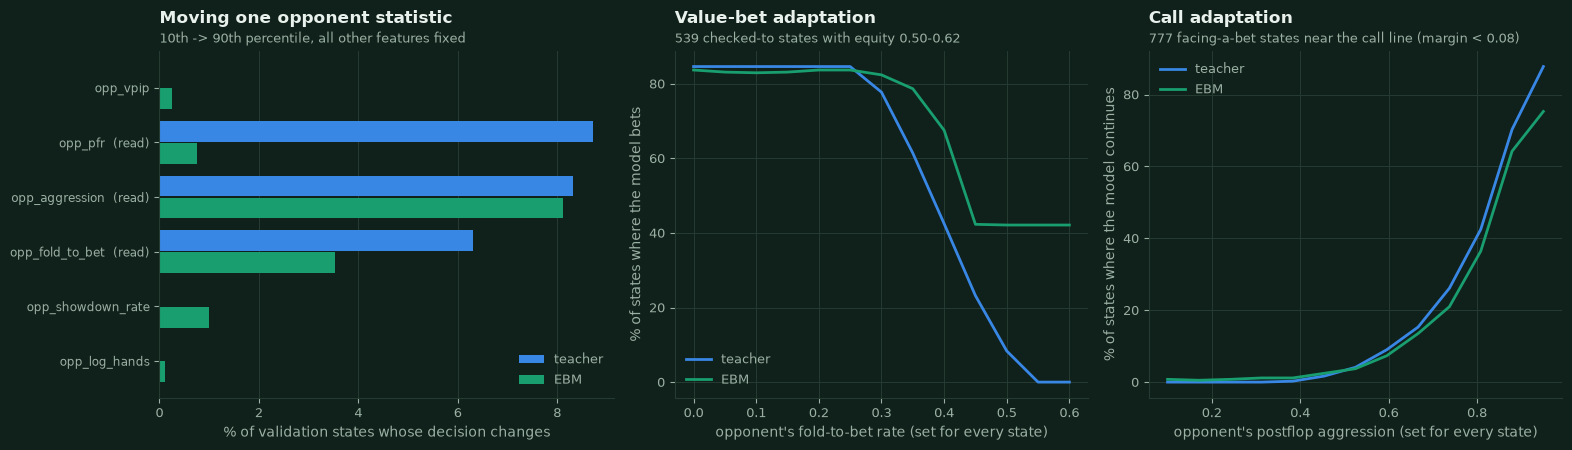

| statistic | teacher reads it | 10th -> 90th percentile | teacher flips (all states) | EBM flips (all states) | teacher flips (margin < 0.05) | EBM flips (margin < 0.05) | EBM importance | of which in pairs |
|---|---|---|---|---|---|---|---|---|
| `opp_vpip` | no | 0.75 -> 0.95 | 0.000 | 0.003 | 0.000 | 0.009 | 0.035 | 0.000 |
| `opp_pfr` | yes | 0.00 -> 0.83 | 0.087 | 0.008 | 0.078 | 0.030 | 0.130 | 0.000 |
| `opp_aggression` | yes | 0.00 -> 0.88 | 0.083 | 0.081 | 0.094 | 0.119 | 3.354 | 0.840 |
| `opp_fold_to_bet` | yes | 0.00 -> 0.43 | 0.063 | 0.035 | 0.163 | 0.095 | 2.074 | 0.937 |
| `opp_showdown_rate` | no | 0.23 -> 0.95 | 0.000 | 0.010 | 0.000 | 0.032 | 0.433 | 0.731 |
| `opp_log_hands` | no | 3.71 -> 6.76 | 0.000 | 0.001 | 0.000 | 0.004 | 0.024 | 0.000 |

**Reading.** *Statistics the teacher uses.* Moving one from its 10th to its 90th percentile changes the teacher's decision in 8.3% (`opp_aggression`), 6.3% (`opp_fold_to_bet`), 8.7% (`opp_pfr`) of all states; the EBM's decision changes in 8.1%, 3.5%, 0.8% - i.e. the EBM reproduces 98% of the teacher's sensitivity to `opp_aggression`, 56% to `opp_fold_to_bet` and 9% to `opp_pfr`. *Statistics the teacher ignores.* The teacher flips 0 states by construction; the EBM flips 0.3% (`opp_vpip`), 1.0% (`opp_showdown_rate`) and 0.1% (`opp_log_hands`). `opp_showdown_rate` is the one it uses most; it is almost a mirror image of `opp_fold_to_bet` in the data (Spearman -0.87), so it can serve as a proxy for the statistic the teacher *does* read. *Where it matters.* Within 0.05 of a teacher threshold the EBM flips 8% of the states on average for the three statistics the teacher uses (teacher 11%) and 1.5% for the three it ignores. *Dose-response.* As the opponent's fold-to-bet rate goes from 0.0 to 0.6 the share of bets moves from 84% to 42% for the EBM and from 85% to 0% for the teacher; as the opponent's aggression goes from 0.10 to 0.95 the share of states that continue against a bet moves from 1% to 75% (teacher 0% to 88%): the same direction, with the EBM's response weaker than the teacher's at the extremes (the data contain few opponents beyond fold-to-bet 0.5, so the right edge of the curves is extrapolation). The opponent statistics enter the EBM mostly through pair terms: the share of each statistic's importance that sits in interactions is `opp_vpip` 0%, `opp_pfr` 0%, `opp_aggression` 84%, `opp_fold_to_bet` 94%, `opp_showdown_rate` 73%, `opp_log_hands` 0%.

In [35]:
OPP_STATS = [n for n in FEATURE_NAMES if FEATURE_GROUP_OF[n] == "opponent"]
TEACHER_USES = {"opp_fold_to_bet", "opp_aggression", "opp_pfr"}
prng = np.random.default_rng(DEMO_SEED + 4)
PERM_IDX = prng.choice(len(VAL.y), size=min(PERMUTATION_ROWS, len(VAL.y)), replace=False)
XP, LP, YP, RP, MP = VAL.X[PERM_IDX], VAL.legal[PERM_IDX], VAL.y[PERM_IDX], RULES[PERM_IDX], MARGIN[PERM_IDX]

boundary_rows = MP < 0.05
flip_rows = []
for name in OPP_STATS:
    j = FEATURE_INDEX[name]
    low_q, high_q = np.quantile(VAL.X[:, j], [0.10, 0.90])
    lo_x, hi_x = XP.copy(), XP.copy()
    lo_x[:, j], hi_x[:, j] = low_q, high_q
    t_flip = teacher_actions(lo_x, LP) != teacher_actions(hi_x, LP)
    e_flip = ebm_actions(lo_x, LP) != ebm_actions(hi_x, LP)
    involves = imp["features"].map(lambda feats: name in feats)
    inter_share = float(imp.loc[involves & (imp["kind"] == "interaction"), "importance"].sum() / max(imp.loc[involves, "importance"].sum(), 1e-12))
    flip_rows.append({"statistic": name, "teacher reads it": name in TEACHER_USES, "10th -> 90th percentile": f"{low_q:.2f} -> {high_q:.2f}", "teacher flips (all states)": t_flip.mean(), "EBM flips (all states)": e_flip.mean(),
                      "teacher flips (margin < 0.05)": t_flip[boundary_rows].mean(), "EBM flips (margin < 0.05)": e_flip[boundary_rows].mean(),
                      "EBM importance": float(imp.loc[involves, "importance"].sum()), "of which in pairs": inter_share})
flips = pd.DataFrame(flip_rows)

# dose-response: P(bet) vs fold-to-bet near the value line; P(call) vs aggression near the call line
dose_a = np.flatnonzero(sel_a[PERM_IDX] & (XP[:, FEATURE_INDEX["equity"]] > 0.50) & (XP[:, FEATURE_INDEX["equity"]] < 0.62))
dose_b = np.flatnonzero((VAL_FRAME["street"].to_numpy()[PERM_IDX] > 0) & (XP[:, FEATURE_INDEX["facing_bet"]] == 1) & np.isin(RP, ["call_odds", "fold_odds"]) & (MP < 0.08))
fold_grid, agg_grid = np.linspace(0.0, 0.6, 13), np.linspace(0.1, 0.95, 13)


def dose(rows: np.ndarray, feature: str, grid: np.ndarray, predicate) -> tuple[np.ndarray, np.ndarray]:
    j = FEATURE_INDEX[feature]
    t_curve, e_curve = [], []
    for g in grid:
        X = XP[rows].copy()
        X[:, j] = g
        t_curve.append(np.mean([predicate(a) for a in teacher_actions(X, LP[rows])]))
        e_curve.append(np.mean([predicate(a) for a in ebm_actions(X, LP[rows])]))
    return np.array(t_curve), np.array(e_curve)


t_fold, e_fold = dose(dose_a, "opp_fold_to_bet", fold_grid, lambda a: a >= 2)
t_agg, e_agg = dose(dose_b, "opp_aggression", agg_grid, lambda a: a != 0)

fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.6), gridspec_kw={"width_ratios": [1.1, 1.0, 1.0]})
ax = axes[0]
ypos = np.arange(len(flips))
ax.barh(ypos - 0.2, 100 * flips["teacher flips (all states)"], height=0.38, color=nbp.SERIES[1], label="teacher")
ax.barh(ypos + 0.2, 100 * flips["EBM flips (all states)"], height=0.38, color=nbp.ACCENT, label="EBM")
ax.set_yticks(ypos, [f"{n}{'  (read)' if r else ''}" for n, r in zip(flips["statistic"], flips["teacher reads it"])], fontsize=8.5)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("% of validation states whose decision changes")
ax.legend(loc="lower right")
nbp.title(ax, "Moving one opponent statistic", "10th -> 90th percentile, all other features fixed")
ax = axes[1]
ax.plot(fold_grid, 100 * t_fold, color=nbp.SERIES[1], linewidth=2, label="teacher")
ax.plot(fold_grid, 100 * e_fold, color=nbp.ACCENT, linewidth=2, label="EBM")
ax.set_xlabel("opponent's fold-to-bet rate (set for every state)")
ax.set_ylabel("% of states where the model bets")
ax.legend(loc="lower left")
nbp.title(ax, "Value-bet adaptation", f"{len(dose_a):,} checked-to states with equity 0.50-0.62")
ax = axes[2]
ax.plot(agg_grid, 100 * t_agg, color=nbp.SERIES[1], linewidth=2, label="teacher")
ax.plot(agg_grid, 100 * e_agg, color=nbp.ACCENT, linewidth=2, label="EBM")
ax.set_xlabel("opponent's postflop aggression (set for every state)")
ax.set_ylabel("% of states where the model continues")
ax.legend(loc="upper left")
nbp.title(ax, "Call adaptation", f"{len(dose_b):,} facing-a-bet states near the call line (margin < 0.08)")
fig.tight_layout()
nbp.savefig("nb01_opponent_modelling", fig)
plt.show()
display(md_table(flips.assign(statistic=[f"`{n}`" for n in flips["statistic"]], **{"teacher reads it": ["yes" if v else "no" for v in flips["teacher reads it"]]}), "{:.3f}"))
unused = flips[~flips["teacher reads it"]]
used = flips[flips["teacher reads it"]]
rows_used = flips.set_index("statistic")
flip_ratio = {n: rows_used.loc[n, "EBM flips (all states)"] / rows_used.loc[n, "teacher flips (all states)"] for n in TEACHER_USES}
corr_showdown = float(corr.loc["opp_showdown_rate", "opp_fold_to_bet"])
display(Markdown(
    f"**Reading.** *Statistics the teacher uses.* Moving one from its 10th to its 90th percentile changes the teacher's decision in " + ", ".join(f"{pct(rows_used.loc[n, 'teacher flips (all states)'], 1)} (`{n}`)" for n in sorted(TEACHER_USES))
    + " of all states; the EBM's decision changes in " + ", ".join(f"{pct(rows_used.loc[n, 'EBM flips (all states)'], 1)}" for n in sorted(TEACHER_USES))
    + f" - i.e. the EBM reproduces {pct(flip_ratio['opp_aggression'], 0)} of the teacher's sensitivity to `opp_aggression`, {pct(flip_ratio['opp_fold_to_bet'], 0)} to `opp_fold_to_bet` and {pct(flip_ratio['opp_pfr'], 0)} to `opp_pfr`. "
    f"*Statistics the teacher ignores.* The teacher flips 0 states by construction; the EBM flips {pct(rows_used.loc['opp_vpip', 'EBM flips (all states)'], 1)} (`opp_vpip`), {pct(rows_used.loc['opp_showdown_rate', 'EBM flips (all states)'], 1)} (`opp_showdown_rate`) and {pct(rows_used.loc['opp_log_hands', 'EBM flips (all states)'], 1)} (`opp_log_hands`). "
    f"`opp_showdown_rate` is the one it uses most; it is almost a mirror image of `opp_fold_to_bet` in the data (Spearman {corr_showdown:+.2f}), so it can serve as a proxy for the statistic the teacher *does* read. "
    f"*Where it matters.* Within 0.05 of a teacher threshold the EBM flips {pct(used['EBM flips (margin < 0.05)'].mean(), 0)} of the states on average for the three statistics the teacher uses (teacher {pct(used['teacher flips (margin < 0.05)'].mean(), 0)}) and {pct(unused['EBM flips (margin < 0.05)'].mean(), 1)} for the three it ignores. "
    f"*Dose-response.* As the opponent's fold-to-bet rate goes from {fold_grid[0]:.1f} to {fold_grid[-1]:.1f} the share of bets moves from {pct(e_fold[0], 0)} to {pct(e_fold[-1], 0)} for the EBM and from {pct(t_fold[0], 0)} to {pct(t_fold[-1], 0)} for the teacher; "
    f"as the opponent's aggression goes from {agg_grid[0]:.2f} to {agg_grid[-1]:.2f} the share of states that continue against a bet moves from {pct(e_agg[0], 0)} to {pct(e_agg[-1], 0)} (teacher {pct(t_agg[0], 0)} to {pct(t_agg[-1], 0)}): "
    f"the same direction, with the EBM's response {'weaker' if abs(e_fold[-1] - e_fold[0]) < abs(t_fold[-1] - t_fold[0]) else 'at least as strong'} than the teacher's at the extremes (the data contain few opponents beyond fold-to-bet 0.5, so the right edge of the curves is extrapolation). "
    f"The opponent statistics enter the EBM mostly through pair terms: the share of each statistic's importance that sits in interactions is " + ", ".join(f"`{n}` {pct(v, 0)}" for n, v in zip(flips['statistic'], flips['of which in pairs'])) + "."
))

### 8.3 Which features does the EBM use that the teacher does not? Permutation tests `[data]`

**Permutation importance** shuffles one feature across the validation states (breaking its link to everything else) and measures what changes. For the teacher this is a *ground-truth* measure - the share of its decisions that depend on the feature;
for the EBM it is the drop in agreement with the teacher. A feature with importance for the EBM and none for the teacher is something the model *exploits* that the labels do not need.

Caveat for correlated features: shuffling `equity` alone leaves `equity_minus_pot_odds` untouched, so the EBM sees an *inconsistent* state, which it may punish more than a consistent change would (the teacher, which never reads `equity_minus_pot_odds`, cannot be affected). For `equity` and `pot_odds` we therefore also show a **coherent** variant that
recomputes `equity_minus_pot_odds = equity - pot_odds` after the shuffle. The other redundant features (price family, stacks, board descriptors) have no such exact recomputation and keep the plain variant.

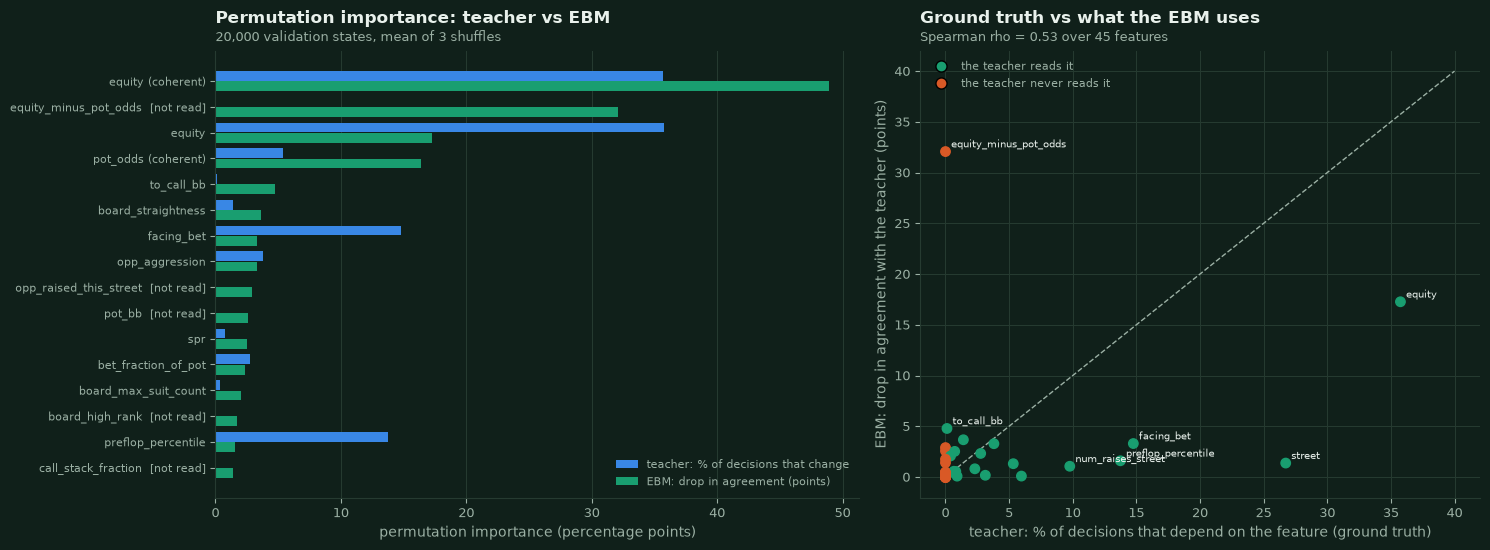

| feature | teacher reads it | teacher: decisions that change | EBM: drop in agreement | EBM importance (terms) |
|---|---|---|---|---|
| `equity (coherent)` | yes | 0.3565 | 0.4890 | 6.3332 |
| `equity_minus_pot_odds` | no | 0.0000 | 0.3207 | 8.2526 |
| `equity` | yes | 0.3575 | 0.1727 | 6.3332 |
| `pot_odds (coherent)` | yes | 0.0537 | 0.1636 | 0.5251 |
| `to_call_bb` | yes | 0.0012 | 0.0478 | 1.7860 |
| `board_straightness` | yes | 0.0140 | 0.0367 | 1.8008 |
| `facing_bet` | yes | 0.1476 | 0.0330 | 0.9583 |
| `opp_aggression` | yes | 0.0380 | 0.0328 | 3.3542 |
| `opp_raised_this_street` | no | 0.0000 | 0.0290 | 0.7907 |
| `pot_bb` | no | 0.0000 | 0.0256 | 0.8608 |
| `spr` | yes | 0.0072 | 0.0252 | 1.8103 |
| `bet_fraction_of_pot` | yes | 0.0276 | 0.0232 | 0.6988 |
| `board_max_suit_count` | yes | 0.0040 | 0.0207 | 1.4999 |
| `board_high_rank` | no | 0.0000 | 0.0175 | 1.3593 |
| `preflop_percentile` | yes | 0.1374 | 0.0160 | 2.2646 |
| `call_stack_fraction` | no | 0.0000 | 0.0140 | 0.9013 |
| `street` | yes | 0.2673 | 0.0137 | 1.3868 |
| `pot_odds` | yes | 0.0533 | 0.0131 | 0.5251 |
| `num_raises_street` | yes | 0.0977 | 0.0106 | 0.5087 |
| `opp_fold_to_bet` | yes | 0.0231 | 0.0081 | 2.0742 |

**Reading.** Of the 45 features the teacher reads 19 in at least one rule. Shuffling the single feature `equity_minus_pot_odds`, which the teacher never reads, costs the EBM more agreement (32.1 points) than shuffling `equity` itself (17.3). Features the teacher *never* reads but whose shuffling costs the EBM more than 1 point: `equity_minus_pot_odds` (32.1 pt), `opp_raised_this_street` (2.9 pt), `pot_bb` (2.6 pt), `board_high_rank` (1.8 pt), `call_stack_fraction` (1.4 pt). Features the teacher reads whose shuffling costs the EBM at most half a point (the model ignores them): `straight_outs`, `opp_pfr`, `is_button`, `effective_stack_bb`. The coherent variants answer the caveat above: shuffling `equity` coherently drops the EBM's agreement by 48.9 points against 17.3 for the plain shuffle (teacher: 35.7% of decisions change); `pot_odds` 16.4 against 1.3. Rank correlation between the two importance profiles: 0.53 (p = 1.8e-04). Note that a derived feature such as `equity_minus_pot_odds` or `to_call_bb` is not *independent* information: it re-encodes what the teacher reads, so using it is not 'cheating' - but it does mean the EBM's credit is spread over names the teacher never mentions.

In [36]:
base_teacher = teacher_actions(XP, LP)
base_ebm = ebm_actions(XP, LP)
assert (base_teacher == YP).all()
prng = np.random.default_rng(DEMO_SEED + 5)
perm_rows = []
EMP = FEATURE_INDEX["equity_minus_pot_odds"]
variants = [(name, FEATURE_INDEX[name], False) for name in FEATURE_NAMES] + [("equity (coherent)", FEATURE_INDEX["equity"], True), ("pot_odds (coherent)", FEATURE_INDEX["pot_odds"], True)]
ever_read = set().union(*READ.values())
for label, j, coherent in variants:
    t_flip, e_drop = [], []
    for _ in range(PERMUTATION_REPEATS):
        shuffled = XP.copy()
        shuffled[:, j] = XP[prng.permutation(len(XP)), j]
        if coherent:
            shuffled[:, EMP] = shuffled[:, FEATURE_INDEX["equity"]] - shuffled[:, FEATURE_INDEX["pot_odds"]]
        t_flip.append(float((teacher_actions(shuffled, LP) != base_teacher).mean()))
        e_pred = ebm_actions(shuffled, LP)
        e_drop.append(float((e_pred != YP).mean() - (base_ebm != YP).mean()))
    perm_rows.append({"feature": label, "teacher reads it": label.split(" ")[0] in ever_read, "teacher: decisions that change": float(np.mean(t_flip)), "EBM: drop in agreement": float(np.mean(e_drop)),
                      "EBM importance (terms)": float(imp.loc[imp["features"].map(lambda feats: label.split(" ")[0] in feats), "importance"].sum())})
perm = pd.DataFrame(perm_rows).sort_values("EBM: drop in agreement", ascending=False).reset_index(drop=True)
plain = perm[~perm["feature"].str.contains("coherent")]
plain_idx = plain.set_index("feature")
rho_perm = stats.spearmanr(plain["teacher: decisions that change"], plain["EBM: drop in agreement"])
exploited = plain[(~plain["teacher reads it"]) & (plain["EBM: drop in agreement"] > 0.01)]
ignored = plain[(plain["teacher reads it"]) & (plain["EBM: drop in agreement"] <= 0.005)]

fig, axes = plt.subplots(1, 2, figsize=(15.0, 5.6), gridspec_kw={"width_ratios": [1.15, 1.0]})
ax = axes[0]
shown = perm.head(16)
ypos = np.arange(len(shown))
ax.barh(ypos - 0.2, 100 * shown["teacher: decisions that change"], height=0.38, color=nbp.SERIES[1], label="teacher: % of decisions that change")
ax.barh(ypos + 0.2, 100 * shown["EBM: drop in agreement"], height=0.38, color=nbp.ACCENT, label="EBM: drop in agreement (points)")
ax.set_yticks(ypos, [f"{f}{'' if r else '  [not read]'}" for f, r in zip(shown["feature"], shown["teacher reads it"])], fontsize=8)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("permutation importance (percentage points)")
ax.legend(loc="lower right", fontsize=8)
nbp.title(ax, "Permutation importance: teacher vs EBM", f"{len(XP):,} validation states, mean of {PERMUTATION_REPEATS} shuffles")
ax = axes[1]
colors_pt = [nbp.ACCENT if r else nbp.SERIES[2] for r in plain["teacher reads it"]]
ax.scatter(100 * plain["teacher: decisions that change"], 100 * plain["EBM: drop in agreement"], c=colors_pt, s=46, zorder=3)
for feature_name, t_value, e_value in zip(plain["feature"], plain["teacher: decisions that change"], plain["EBM: drop in agreement"]):
    if e_value > 0.04 or t_value > 0.09:
        ax.annotate(feature_name, (100 * t_value, 100 * e_value), xytext=(4, 3), textcoords="offset points", fontsize=7.5, color=nbp.TEXT)
ax.plot([0, 40], [0, 40], color=nbp.MUTED, linestyle="--", linewidth=1)
ax.set_xlabel("teacher: % of decisions that depend on the feature (ground truth)")
ax.set_ylabel("EBM: drop in agreement with the teacher (points)")
handles = [plt.Line2D([0], [0], marker="o", color="none", markerfacecolor=c, markersize=8) for c in (nbp.ACCENT, nbp.SERIES[2])]
ax.legend(handles, ["the teacher reads it", "the teacher never reads it"], loc="upper left", fontsize=8)
nbp.title(ax, "Ground truth vs what the EBM uses", f"Spearman rho = {rho_perm.statistic:.2f} over {len(plain)} features")
fig.tight_layout()
nbp.savefig("nb01_permutation_importance", fig)
plt.show()
display(md_table(perm.head(20).assign(feature=[f"`{f}`" for f in perm.head(20)["feature"]], **{"teacher reads it": ["yes" if v else "no" for v in perm.head(20)["teacher reads it"]]}), "{:.4f}"))
display(Markdown(
    f"**Reading.** Of the {len(plain)} features the teacher reads {int(plain['teacher reads it'].sum())} in at least one rule. Shuffling the single feature `equity_minus_pot_odds`, which the teacher never reads, costs the EBM more agreement ({100 * plain_idx.loc['equity_minus_pot_odds', 'EBM: drop in agreement']:.1f} points) than shuffling `equity` itself ({100 * plain_idx.loc['equity', 'EBM: drop in agreement']:.1f}). "
    f"Features the teacher *never* reads but whose shuffling costs the EBM more than 1 point: " + (", ".join(f"`{f}` ({100 * d:.1f} pt)" for f, d in zip(exploited["feature"], exploited["EBM: drop in agreement"])) or "none") + ". "
    f"Features the teacher reads whose shuffling costs the EBM at most half a point (the model ignores them): " + (", ".join(f"`{f}`" for f in ignored["feature"]) or "none") + ". "
    f"The coherent variants answer the caveat above: shuffling `equity` coherently drops the EBM's agreement by {100 * perm.set_index('feature').loc['equity (coherent)', 'EBM: drop in agreement']:.1f} points against {100 * perm.set_index('feature').loc['equity', 'EBM: drop in agreement']:.1f} for the plain shuffle "
    f"(teacher: {100 * perm.set_index('feature').loc['equity', 'teacher: decisions that change']:.1f}% of decisions change); `pot_odds` {100 * perm.set_index('feature').loc['pot_odds (coherent)', 'EBM: drop in agreement']:.1f} against {100 * perm.set_index('feature').loc['pot_odds', 'EBM: drop in agreement']:.1f}. "
    f"Rank correlation between the two importance profiles: {rho_perm.statistic:.2f} (p = {rho_perm.pvalue:.1e}). Note that a derived feature such as `equity_minus_pot_odds` or `to_call_bb` is not *independent* information: it re-encodes what the teacher reads, "
    f"so using it is not 'cheating' - but it does mean the EBM's credit is spread over names the teacher never mentions."
))

### 8.4 Where the EBM disagrees with the teacher - and why `[data]`

Section 5.3 showed that errors sit next to the thresholds. The rules with the highest *rate* of disagreement are not the threshold rules but the ones that need several conditions at once.

In [37]:
rule_stats = pd.DataFrame({"rule": RULES, "agree": EBM_ACTION == TEACHER_ACTION, "teacher": TEACHER_ACTION, "ebm": EBM_ACTION}).groupby("rule").agg(n=("agree", "size"), agreement=("agree", "mean"))
worst = rule_stats[rule_stats["n"] >= 50].sort_values("agreement").head(8)
conj = {"cbet_bluff": "weak hand + initiative + dry flop + folding opponent", "semi_bluff_bet": "strong draw + folding opponent + position or initiative", "raise_semi_bluff": "flush AND straight draw + folding opponent + street + raise count",
        "pre_fold_short": "short stack + percentile below the push line", "pre_push": "short stack + percentile above the push line", "pre_fold": "price vs equity after a range penalty",
        "call_odds": "equity minus a bet-size penalty vs pot odds + margin", "pre_4bet": "percentile + number of raises", "pre_shove_premium": "percentile + number of raises"}
display(Markdown("**[data]** The eight rules with the lowest agreement (at least 50 validation states):"))
display(md_table(pd.DataFrame({"rule": [f"`{r}`" for r in worst.index], "states": worst["n"], "agreement": [pct(v, 1) for v in worst["agreement"]],
                               "what the teacher combines": [conj.get(r, "-") for r in worst.index]})))
bluff_rules = ["cbet_bluff", "semi_bluff_bet", "raise_semi_bluff"]
bluff_mask = np.isin(RULES, bluff_rules)
under = float((EBM_ACTION[bluff_mask] == 1).mean())
false_bluffs = int(((EBM_ACTION >= 2) & (TEACHER_ACTION == 1) & np.isin(RULES, ["check_weak"])).sum())
n_check_weak = int((RULES == "check_weak").sum())
display(Markdown(
    f"**Reading.** The three *bluff* rules (`cbet_bluff`, `semi_bluff_bet`, `raise_semi_bluff`; {int(bluff_mask.sum()):,} states, {pct(bluff_mask.mean(), 2)} of the data) are copied with {pct(float((EBM_ACTION[bluff_mask] == TEACHER_ACTION[bluff_mask]).mean()), 0)} agreement; "
    f"in {pct(under, 0)} of them the EBM simply checks or calls instead of bluffing, while it bluffs by mistake in {false_bluffs:,} of {n_check_weak:,} `check_weak` states ({pct(false_bluffs / n_check_weak, 2)}). "
    f"A bluff is the conjunction of weak equity, a draw or initiative, a favourable board and a folding opponent - an AND of four features that an additive model builds from many small overlapping terms and that is therefore the first thing to blur. "
    f"The same picture holds for the rare short-stack push/fold states ({int(push_mask.sum())} states, {pct(push_agree, 0)} agreement). These are hypotheses about the cause, consistent with the numbers but not tested by removing features."
))

**[data]** The eight rules with the lowest agreement (at least 50 validation states):

| rule | states | agreement | what the teacher combines |
|---|---|---|---|
| `raise_semi_bluff` | 72 | 36.1% | flush AND straight draw + folding opponent + street + raise count |
| `cbet_bluff` | 484 | 69.4% | weak hand + initiative + dry flop + folding opponent |
| `semi_bluff_bet` | 324 | 75.0% | strong draw + folding opponent + position or initiative |
| `pre_fold` | 848 | 89.0% | price vs equity after a range penalty |
| `call_odds` | 5447 | 93.0% | equity minus a bet-size penalty vs pot odds + margin |
| `pre_push` | 59 | 93.2% | short stack + percentile above the push line |
| `raise_value` | 458 | 93.9% | - |
| `pre_shove_premium` | 66 | 97.0% | percentile + number of raises |

**Reading.** The three *bluff* rules (`cbet_bluff`, `semi_bluff_bet`, `raise_semi_bluff`; 880 states, 1.19% of the data) are copied with 69% agreement; in 29% of them the EBM simply checks or calls instead of bluffing, while it bluffs by mistake in 377 of 20,378 `check_weak` states (1.85%). A bluff is the conjunction of weak equity, a draw or initiative, a favourable board and a folding opponent - an AND of four features that an additive model builds from many small overlapping terms and that is therefore the first thing to blur. The same picture holds for the rare short-stack push/fold states (77 states, 86% agreement). These are hypotheses about the cause, consistent with the numbers but not tested by removing features.

## 9. Interpretation

The blocks below are kept strictly apart: **empirical findings** are numbers computed in this notebook (every number is generated from the variables above, so the text stays truthful if the artifacts are regenerated);
**assumptions** are things taken as given; **speculation** are hypotheses the data suggest but that were not tested; **limitations** and **future work** close the notebook.

In [38]:
# ---- numbers quoted by the text (all computed in the cells above) ----
fr = fresh
rule_by_n = rule_err[rule_err["size"] >= 100]
bots_lines = ", ".join(f"`{o}` {ci_text(fr['EBM', o].bb_per_100, fr['EBM', o].ci_low, fr['EBM', o].ci_high)}" for o in BOTS)
held_lines = ", ".join(f"`{o}` {ci_text(fr['EBM', o].bb_per_100, fr['EBM', o].ci_low, fr['EBM', o].ci_high)}" for o in HELD_OUT)
diff_lines = ", ".join(f"`{o}` {ci_text(d.bb_per_100, d.ci_low, d.ci_high)}" for o, d in diffs_vs_teacher.items())
exploited_names = ", ".join(f"`{f}` ({100 * d:.1f} pt)" for f, d in zip(exploited["feature"], exploited["EBM: drop in agreement"]))
ignored_names = ", ".join(f"`{f}`" for f in ignored["feature"])
pairs_gain_text = f"{pct(acc_all, 2)} with the 40 pair terms, {pct(acc_main, 2)} without them (no refit)"
dagger_sentence = (
    "DAgger produced a measurable gain in the paired comparison." if dagger_helped else
    f"It gave **no resolvable gain**: agreement on the model's own states moved by {', '.join(f'{d:+.2f}' for d in on_policy_delta[1:])} points, mean validation BB/100 spread over {max(mean_bb) - min(mean_bb):.0f} BB/100 between rounds, "
    f"and {len(paired_better)} of {len(paired_cells)} paired (round, opponent) comparisons with round 0 are significantly better ({len(paired_worse)} significantly worse) - all BB/100 of this item are from the *legacy single-table protocol* (informational; the candidates were near-tied), the agreement numbers are not affected by it."
)
teacher_sentence = {"wins": "**beats** the teacher", "loses": "**loses** to the teacher", "no significant difference": "is **not distinguishable** from the teacher"}[verdict(teacher_row.ci_low, teacher_row.ci_high)]
display(Markdown(f"""
### 9.1 Empirical findings (computed in this notebook)

1. **The data are an exactly reproducible imitation task `[data]`.** {len(FULL):,} labelled decisions ({n_hands:,} validation hands never seen in training); re-running the teacher on the stored features reproduces {pct(teacher_reproduces, 2)} of the labels, so the ground truth is known exactly.
   The classes are very unbalanced (`check_call` is {imbalance:.0f}x as frequent as `all_in`), which the class weights ({meta['class_weights']['all_in'] / meta['class_weights']['check_call']:.1f}x between the extremes) and the legal-action masks address.
2. **The EBM is a very good copy `[data]`.** It agrees with the teacher on {pct(metrics['masked_accuracy'], 2)} of the validation decisions (95% hand-level bootstrap [{pct(acc_low, 2)}, {pct(acc_high, 2)}]; macro-F1 {metrics['masked_macro_f1']:.3f}, balanced accuracy {metrics['masked_balanced_accuracy']:.3f}), highest preflop ({pct(street_acc['preflop'], 1)}) and lowest on the {worst_street} ({pct(street_acc[worst_street], 1)}).
   Disagreements are boundary effects: {pct(near_boundary_share, 0)} of the errors have a teacher margin below 0.05 (only {pct(near_boundary_rows, 0)} of the rows do), and {pct(float((step[err] == 1).mean()), 0)} of them are one step on the fold < call < raise ladder.
   The weakest spot are the *bluff* rules (`cbet_bluff`, `semi_bluff_bet`, `raise_semi_bluff`: {pct(float((EBM_ACTION[bluff_mask] == TEACHER_ACTION[bluff_mask]).mean()), 0)} agreement on {int(bluff_mask.sum()):,} states) and the rare short-stack push/fold states ({pct(push_agree, 0)} on {int(push_mask.sum())} states).
3. **Did DAgger help? `[saved]`** {dagger_sentence} The behaviour-cloning model already agrees with the teacher on {pct(first['on_policy_validation']['masked_accuracy'], 2)} of the states it visits itself ({pct(first['bc_validation']['masked_accuracy'], 2)} on the dataset's validation states): covariate shift is small for this teacher and dataset.
4. **Playing strength `[fresh]` `[saved]`.** On {teacher_row.n_pairs} fresh duplicate pairs (two-table protocol) the EBM {teacher_sentence}: {ci_text(teacher_row.bb_per_100, teacher_row.ci_low, teacher_row.ci_high)} BB/100 (match-level interval [{teacher_row.match_ci_low:+.0f}, {teacher_row.match_ci_high:+.0f}]). The official tournament, with far more pairs and the same protocol, gives EBM vs Teacher {official_text}; the fresh estimate is {compatible} it.
   It wins against the three bots ({bots_lines}) and against the three opponents it never met in training ({held_lines}). Paired on identical deals, EBM minus teacher is {diff_lines}: {len(better)} significantly positive, {len(worse)} significantly negative, {len(equal_or_better)} not resolved. In this sample imitation cost {'**no measurable strength**' if not worse else 'strength against ' + ', '.join(worse)} (the paired intervals against the solid opponents are about +-{np.median([(d.ci_high - d.ci_low) / 2 for o, d in diffs_vs_teacher.items() if o in SOLID]):.0f} BB/100 wide: a smaller loss would not be visible), and the official run, which can resolve a few BB/100, finds the EBM {official_word}.{' A ' + pct(metrics['masked_accuracy'], 1) + ' copy whose errors sit next to thresholds is not *expected* to be ahead of its teacher; why it can be is not answered here (Notebook 4, section 9 investigates).' if official_word.startswith('ahead') else ''}
   These intervals are the evidence; "wins" means the interval excludes zero, and with {len(fr)} matchups a few will do so by chance.
5. **What it looks at `[saved]` `[data]`.** `equity` and its exact copy `equity_minus_pot_odds` dominate ({', '.join(f'`{r.term}` {r.importance:.1f}' for r in imp.head(2).itertuples())}), then `spr` (almost only for `all_in`) and the board-texture counts (the teacher's wet-board rule). Interactions carry {pct(share_inter, 0)} of the importance and {n_pairs_with_opp} of the 40 pairs involve an opponent statistic.
   The 40 pair terms are not a small correction in the committed model: {pairs_gain_text}; a refitted purely additive model reaches about 96.7% (section 4.4).
6. **Local explanations are exact for the model, and only partly informative about the teacher `[data]`.** The additive identity holds to {identity_error:.0e}. The term with the largest contribution is a feature the deciding rule reads or an exact copy of one in {pct(tier_shares(tiers_actual)[:2].sum(), 0)} of {len(YF):,} states, but an explanation of an *unrelated* state scores {pct(tier_shares(tiers_null)[:2].sum(), 0)}: the test does not discriminate, because hand strength dominates everywhere.
   For the rule-specific decisive features (those that tip the teacher's decision once hand strength is fixed) the top-5 contrast terms recover {pct(spec_con, 0)} against {pct(rec(5, 'con_null', 'rule-specific recall'), 0)} for the wrong-row null and {pct(spec_rand, 0)} for five random terms. Explanations by contribution say "hand strength and situation"; they rarely single out the secondary feature that tips a decision.
7. **The learned boundaries match the teacher's parameters `[data]`.** Preflop, the EBM's percentile boundaries lie within {mean_ladder_gap:.3f} (mean) and {max_ladder_gap:.3f} (max) of the teacher's {len(ladder)} thresholds; post-flop the value-bet line follows the teacher's fold-rate slide (slope {slope('EBM (empirical)'):.2f} against the teacher's {slope('teacher (exact function)'):.2f}, largest gap {value_gap:.3f} equity points) and the call line the aggression slide (slope {call_slope('EBM (empirical)'):.2f} against {call_slope('teacher (exact function)'):.2f}, largest gap {call_gap:.3f}).
   The five largest steps of `equity` coincide with the teacher's pot-bet / raise / value-cap thresholds ({pct(by_feature_close.get('`equity`', float('nan')), 0)} of them within one bin).
8. **Opponent modelling is partial `[data]`.** Against the teacher's three adaptation statistics the EBM reproduces {pct(flip_ratio['opp_aggression'], 0)} of the teacher's sensitivity to `opp_aggression`, {pct(flip_ratio['opp_fold_to_bet'], 0)} to `opp_fold_to_bet` and {pct(flip_ratio['opp_pfr'], 0)} to `opp_pfr` (moving each from the 10th to the 90th percentile). It also reacts a little to `opp_showdown_rate` ({pct(rows_used.loc['opp_showdown_rate', 'EBM flips (all states)'], 1)} of the states), which the teacher ignores but which mirrors `opp_fold_to_bet` in the data.
9. **It uses features the teacher never reads, mostly as copies `[data]`.** Shuffling `equity_minus_pot_odds` costs the EBM {100 * plain_idx.loc['equity_minus_pot_odds', 'EBM: drop in agreement']:.1f} points of agreement though the teacher does not read it (it is `equity - pot_odds`); next come {', '.join(f'`{f}` ({100 * d:.1f} pt)' for f, d in zip(exploited['feature'], exploited['EBM: drop in agreement']) if f != 'equity_minus_pot_odds') or 'no other feature above one point'}.
   It ignores some features the teacher reads ({ignored_names or 'none'}), presumably because other columns carry the same information. Rank correlation between the teacher's ground-truth importance and the EBM's permutation importance: {rho_perm.statistic:.2f}.
"""))


### 9.1 Empirical findings (computed in this notebook)

1. **The data are an exactly reproducible imitation task `[data]`.** 432,652 labelled decisions (22,261 validation hands never seen in training); re-running the teacher on the stored features reproduces 100.00% of the labels, so the ground truth is known exactly.
   The classes are very unbalanced (`check_call` is 38x as frequent as `all_in`), which the class weights (5.9x between the extremes) and the legal-action masks address.
2. **The EBM is a very good copy `[data]`.** It agrees with the teacher on 97.86% of the validation decisions (95% hand-level bootstrap [97.76%, 97.97%]; macro-F1 0.972, balanced accuracy 0.981), highest preflop (99.2%) and lowest on the turn (96.7%).
   Disagreements are boundary effects: 64% of the errors have a teacher margin below 0.05 (only 20% of the rows do), and 94% of them are one step on the fold < call < raise ladder.
   The weakest spot are the *bluff* rules (`cbet_bluff`, `semi_bluff_bet`, `raise_semi_bluff`: 69% agreement on 880 states) and the rare short-stack push/fold states (86% on 77 states).
3. **Did DAgger help? `[saved]`** It gave **no resolvable gain**: agreement on the model's own states moved by +0.32, +0.31, +0.10 points, mean validation BB/100 spread over 44 BB/100 between rounds, and 0 of 12 paired (round, opponent) comparisons with round 0 are significantly better (2 significantly worse) - all BB/100 of this item are from the *legacy single-table protocol* (informational; the candidates were near-tied), the agreement numbers are not affected by it. The behaviour-cloning model already agrees with the teacher on 97.81% of the states it visits itself (97.92% on the dataset's validation states): covariate shift is small for this teacher and dataset.
4. **Playing strength `[fresh]` `[saved]`.** On 1000 fresh duplicate pairs (two-table protocol) the EBM is **not distinguishable** from the teacher: +17 [-17, +51] BB/100 (match-level interval [-20, +55]). The official tournament, with far more pairs and the same protocol, gives EBM vs Teacher +37 [+27, +47] BB/100 from 20,000 pairs (ahead of the teacher); the fresh estimate is compatible with it.
   It wins against the three bots (`call_station` +776 [+700, +853], `maniac` +1263 [+1082, +1445], `random` +449 [+312, +587]) and against the three opponents it never met in training (`ga_evolved` +106 [+40, +173], `balanced` +144 [+63, +225], `bluffer` +182 [+89, +276]). Paired on identical deals, EBM minus teacher is `ga_evolved` -25 [-76, +26], `balanced` +63 [-2, +127], `bluffer` -10 [-73, +54], `call_station` +20 [+6, +33], `maniac` -33 [-124, +57], `random` -63 [-186, +60]: 1 significantly positive, 0 significantly negative, 5 not resolved. In this sample imitation cost **no measurable strength** (the paired intervals against the solid opponents are about +-64 BB/100 wide: a smaller loss would not be visible), and the official run, which can resolve a few BB/100, finds the EBM ahead of the teacher. A 97.9% copy whose errors sit next to thresholds is not *expected* to be ahead of its teacher; why it can be is not answered here (Notebook 4, section 9 investigates).
   These intervals are the evidence; "wins" means the interval excludes zero, and with 13 matchups a few will do so by chance.
5. **What it looks at `[saved]` `[data]`.** `equity` and its exact copy `equity_minus_pot_odds` dominate (`equity` 5.1, `equity_minus_pot_odds` 3.7), then `spr` (almost only for `all_in`) and the board-texture counts (the teacher's wet-board rule). Interactions carry 30% of the importance and 27 of the 40 pairs involve an opponent statistic.
   The 40 pair terms are not a small correction in the committed model: 97.86% with the 40 pair terms, 80.08% without them (no refit); a refitted purely additive model reaches about 96.7% (section 4.4).
6. **Local explanations are exact for the model, and only partly informative about the teacher `[data]`.** The additive identity holds to 9e-15. The term with the largest contribution is a feature the deciding rule reads or an exact copy of one in 97% of 20,000 states, but an explanation of an *unrelated* state scores 97%: the test does not discriminate, because hand strength dominates everywhere.
   For the rule-specific decisive features (those that tip the teacher's decision once hand strength is fixed) the top-5 contrast terms recover 29% against 20% for the wrong-row null and 29% for five random terms. Explanations by contribution say "hand strength and situation"; they rarely single out the secondary feature that tips a decision.
7. **The learned boundaries match the teacher's parameters `[data]`.** Preflop, the EBM's percentile boundaries lie within 0.003 (mean) and 0.008 (max) of the teacher's 8 thresholds; post-flop the value-bet line follows the teacher's fold-rate slide (slope 0.42 against the teacher's 0.40, largest gap 0.020 equity points) and the call line the aggression slide (slope -0.72 against -0.80, largest gap 0.030).
   The five largest steps of `equity` coincide with the teacher's pot-bet / raise / value-cap thresholds (80% of them within one bin).
8. **Opponent modelling is partial `[data]`.** Against the teacher's three adaptation statistics the EBM reproduces 98% of the teacher's sensitivity to `opp_aggression`, 56% to `opp_fold_to_bet` and 9% to `opp_pfr` (moving each from the 10th to the 90th percentile). It also reacts a little to `opp_showdown_rate` (1.0% of the states), which the teacher ignores but which mirrors `opp_fold_to_bet` in the data.
9. **It uses features the teacher never reads, mostly as copies `[data]`.** Shuffling `equity_minus_pot_odds` costs the EBM 32.1 points of agreement though the teacher does not read it (it is `equity - pot_odds`); next come `opp_raised_this_street` (2.9 pt), `pot_bb` (2.6 pt), `board_high_rank` (1.8 pt), `call_stack_fraction` (1.4 pt).
   It ignores some features the teacher reads (`straight_outs`, `opp_pfr`, `is_button`, `effective_stack_bb`), presumably because other columns carry the same information. Rank correlation between the teacher's ground-truth importance and the EBM's permutation importance: 0.53.


### 9.2 Assumptions (taken as given, not tested here)

1. **Equity against a random hand is a usable summary of hand strength.** It is the teacher's design and the EBM inherits it; neither models the opponent's range beyond a penalty that grows with the bet size and the raise count.
2. **One fixed game.** Heads-up no-limit hold'em, blinds 5/10, stacks reset to 100 big blinds before every hand (10% of the training hands start shorter). Nothing here says how the agents behave at other depths, in a tournament, or against humans.
3. **The teacher is a heuristic reference, not a solver.** "Agrees with the teacher" means "reproduces this rule set", and "not distinguishable from the teacher" means "as good as this rule set against these opponents", not "good poker".
4. **Duplicate pairs are treated as independent units.** The two-table protocol removes the second-mover artifact of the legacy protocol (identical adaptive agents cancel), but adaptive agents (EBM and teacher) still make consecutive pairs of a match slightly dependent through the drift of the opponent statistics; the match-level interval next to every result is the conservative reading.
5. **The validation split resembles the training distribution.** It comes from the same behaviour and opponent mixtures (different hands); the held-out *deals and opponents* of section 5.4 are what test generalisation, and they test only a few opponents.
6. **The ground-truth sets of section 7.3 are modelling choices.** The features a rule reads (validated against the teacher itself), the exact re-encodings and partial proxies, and the definition of "decisive" (a move to the 10th/90th percentile of a single feature) can be argued; every explanation test is shown next to a null so that the reader can judge how much it discriminates.
7. **Multiplicity.** Dozens of intervals and tests are shown; a few will look significant by chance (the replication check of section 5.4 is the reminder). Findings that rest on one marginal interval are hints.

### 9.3 Speculation (hypotheses suggested by the data, not tested)

1. **Bluffs are blurred because they are conjunctions.** A bluff needs weak equity *and* a draw or the initiative *and* a favourable board *and* a folding opponent; an additive model with 40 pairs builds that from many overlapping terms. A model with higher-order terms (trees, the XGBoost agent of Notebook 2) or more targeted pairs would test it.
2. **The weaker adaptation to `opp_fold_to_bet` and `opp_pfr` comes from sparse supervision.** The teacher's adaptation only changes a decision in the few states within a few equity points of a threshold, so the data carry little signal per statistic. Up-weighting low-margin rows (the teacher margin is stored) or sampling more such states would test it.
3. **`opp_showdown_rate` acts as a proxy for the fold rate.** Their correlation is strong and the EBM reacts to the former although the teacher never reads it; removing the column and refitting would test it.
4. **The EBM's disagreements are cheap.** They sit next to thresholds, where the expected value of the two neighbouring actions is nearly equal; this would explain why a 97.9% copy shows no measurable loss against the teacher. Whether the disagreements are also related to the EBM's result against the teacher in the larger official run (item 4 of 9.1) is a separate question (Notebook 4, section 9). Only an expected-value comparison of the disputed decisions (e.g. an AIVAT-style estimator) can test either.
5. **DAgger did not help because the behaviour mixture already covered the relevant states.** A narrower behaviour policy (teacher only) would be expected to show a larger covariate shift and a clearer DAgger gain.
6. **Position (`is_button`) is ignored because other columns encode it** (commit fractions, the price of the call before the flop). A leave-one-feature-out refit would test it.
7. **The large drop when the pair terms are deleted comes from how InterpretML stages and post-processes the terms**, not from an unusual dependence on interactions. Fitting the same data with `interactions=0` at full scale and comparing the main effects with those of the committed model would test it.

### 9.4 Limitations

* **Additivity.** Every decision is a *sum* of one- and two-feature terms. Conjunctions of three or more conditions (bluffs, push/fold at specific stack depths) are approximated, and the interaction budget (40 pairs chosen by a fast ranking) is a hard cap.
* **Imitation ceiling.** The EBM learns the teacher's decisions; it cannot become better than the teacher on purpose, and it copies the teacher's blind spots (equity against a random hand, a hand-made range penalty). Outcome-based learning (the GA of Notebook 3, or reinforcement learning) is the way past that ceiling.
* **Five abstract actions** (fold, call, half pot, pot, all-in): finer sizing, check-raises or donk bets are not expressible. **Heads-up and fixed 100 big blinds** (reset every hand) - no stack-depth or tournament dynamics.
* **One training run, one dataset, one seed.** No estimate of run-to-run variability of the model; the bagging band of section 6.3 measures the stability of the fitting procedure (10 bags of one run), not the uncertainty about new data. Model selection (the DAgger round) used noisy validation BB/100.
* **Sharp probabilities.** The model is almost deterministic (section 5.2); its probabilities are not those of a stochastic player and carry no calibrated uncertainty about the *teacher* beyond "close to a threshold".
* **Credit among redundant features is arbitrary.** `equity`, `equity_minus_pot_odds`, `preflop_percentile`, the price family and the stack family are near-copies; individual curves and contributions must be read together, and every test of section 7-8 that needs "the" feature has to define aliases.
* **Counterfactuals move one feature at a time**, which creates states that do not occur in play (the opponent statistics are correlated, equity and its derivative must move together); the coherent variants only handle the exact identities.
* **Interactive widgets.** `interpret.show` needs a live Jupyter kernel and a free local port; GitHub renders none of them. The static figures carry the same messages.
* **Sub-samples.** The explanation, permutation and counterfactual studies use seeded subsets of 20,000 validation states, not all 73,777.

### 9.5 Ideas for future work

* **Beyond imitation:** fine-tune or evolve the EBM's decisions against *outcomes* (self-play, regret-based methods, GA fitness as in Notebook 3) and use the teacher only as a held-out judge; or distil from a stronger teacher (a solver-based policy).
* **Richer opponent models:** equity against an *estimated range* instead of a random hand, Bayesian opponent statistics with uncertainty (`opp_log_hands` is a crude proxy), and a test of whether an EBM can learn the adaptation to `opp_pfr` that it missed here.
* **Targeted model improvements:** monotonic constraints on equity (`monotone_constraints`), more pairs or a different pair-selection rule, margin-weighted rows, a leave-one-group-out study of the redundant features, several seeds with the spread of the shape functions.
* **Better evidence:** expected-value (variance-reduced, AIVAT-style) comparison of the disputed decisions, more opponents, human hand histories, other stack depths.
* **Explanation methods side by side:** apply SHAP to the XGBoost agent on the *same cases* (Notebook 2) and compare with the exact EBM contributions; rule traces for the GA agent (Notebook 3); the tournament comparison of all agents is Notebook 4.

### 9.6 How the EBM's explanations differ in nature from the other agents' (pointer to Notebooks 2, 3, 4)

| | **EBM (this notebook)** | **XGBoost + SHAP (Notebook 2)** | **Genetic algorithm (Notebook 3)** |
|---|---|---|---|
| What is explained | the model's logit, **exactly**: a sum of lookup tables | a tree ensemble's output, **approximately**, by Shapley values (a fair split of the output among features) | the decision *procedure itself*: a fixed rule cascade with 18 named genes |
| Global view | the shape functions *are* the model; global and local views come from the same tables | an aggregate of local attributions (mean \|SHAP\|); no table that reproduces the model | the strategy card: thresholds and frequencies in poker terms |
| Local view | a bar per term (one feature or a pair), adding up to the logit | a bar per feature, adding up to the output relative to a background average | "which rule fired, with which gene values" |
| Redundant features | credit is spread over copies by the fit (as seen here) | credit depends on the background distribution and on how correlated features are handled | not applicable: the rules read named quantities |
| Fidelity | exact for the model; the model is only an approximation of the teacher | exact for the attribution *definition*, an approximation of what the model does off-distribution | exact: the explanation is the program |
| Typical weakness | additivity (higher-order conjunctions), thousands of numbers behind 85 terms | post-hoc and model-dependent; stability under correlated features | tiny hypothesis space (18 genes) |

In [39]:
runtime = time.perf_counter() - NOTEBOOK_STARTED
figure_files = sorted((ARTIFACTS_DIR / "figures").glob("nb01_*.png"))
display(Markdown(
    f"Notebook run time: **{runtime / 60:.1f} min** on {N_WORKERS} worker processes (fresh simulations) plus the main process. {len(figure_files)} figures written to `artifacts/figures/` ({sum(f.stat().st_size for f in figure_files) / 1e6:.1f} MB): "
    + ", ".join(f"`{f.name}`" for f in figure_files) + "."
))

Notebook run time: **2.4 min** on 4 worker processes (fresh simulations) plus the main process. 24 figures written to `artifacts/figures/` (3.1 MB): `nb01_calibration.png`, `nb01_case_1_strong_value_bet.png`, `nb01_case_2_thin_value_bet.png`, `nb01_case_3_semi_bluff.png`, `nb01_case_4_fold_big_bet.png`, `nb01_case_5_marginal_call.png`, `nb01_case_6_preflop_open.png`, `nb01_case_7_push_fold.png`, `nb01_case_8_river_decision.png`, `nb01_confusion_and_streets.png`, `nb01_dagger_rounds.png`, `nb01_dataset_overview.png`, `nb01_error_analysis.png`, `nb01_explanation_fidelity.png`, `nb01_explanation_recovery.png`, `nb01_feature_correlation.png`, `nb01_importance.png`, `nb01_interactions.png`, `nb01_learned_thresholds.png`, `nb01_opponent_modelling.png`, `nb01_permutation_importance.png`, `nb01_policy_evaluation.png`, `nb01_shape_functions.png`, `nb01_shapes_vs_teacher.png`.